# Class 19: Machine Learning 2 — Graph ML & GNNs

Goals of today's class:
1. Understand what a neural network does, starting from the logistic regression we fit on Wednesday
2. Build a graph neural network by putting the same little neural network on every node
3. Train a graph convolutional network (GCN) to predict the topics of papers in a citation network, and compare it to a model that never sees the network
4. See what can go wrong: too many layers, and papers whose neighbors are on other topics
__________

## Getting today's notebook

**Every class, duplicate the notebook before you run anything, and work in the copy.** Running a cell changes the file, and a changed original can block your next pull.

1. Log in to [Open OnDemand](https://ood.explorer.northeastern.edu/), open the **Courses** menu, and click **JupyterLab (Python)**. Launch it with the same settings as last class; they should already be filled in.
2. Once JupyterLab starts, open a terminal (**File → New → Terminal**) and pull the new material, where `USERNAME` is your Northeastern username:
   ```bash
   cd /courses/NETS7052.202710/students/USERNAME/nets7052_fa26
   git fetch upstream
   git checkout main
   git merge --no-edit upstream/main
   ```
   Once you've committed work of your own to your fork (Assignment 1, for example), this merge needs a commit message. `--no-edit` lets Git write that message itself instead of opening a text editor in your terminal.
3. **Duplicate today's notebook before you run anything.** In the file browser, open `notebooks/class_19_machine_learning2/`, right-click `class_19_machine_learning2.ipynb`, and choose **Duplicate**. Open the copy (`class_19_machine_learning2-Copy1.ipynb`) and work there.
4. **Today we use a different environment, one with PyTorch installed.** Register it as a kernel the same way you registered `cmns-graphtool` in Class 8; you only do this once. In the terminal, run this single line, exactly as written:
   ```bash
   /courses/NETS7052.202710/shared/cmns-ml/bin/python -m ipykernel install --user --name cmns-ml --display-name "Python (cmns-ml)"
   ```
   Then reload the browser tab, open your copy of the notebook, and choose **Kernel → Change Kernel…** → **Python (cmns-ml)**. The top-right corner should say **Python (cmns-ml)**. Parts 1 and 2 also run in **Python (cmns-core)**, so if the new kernel gives you trouble, start there. When we get to Part 3, switch to **Python (cmns-ml)** and rerun everything above with **Run → Run All Above Selected Cell**.

**If the merge doesn't work:**

- *"Your local changes to the following files would be overwritten by merge"*: you changed a notebook that I've since updated, and Git lists which one. If you took notes in it, duplicate it first. Then close it and reset it, using the path Git listed:
  ```bash
  git restore notebooks/class_18_machine_learning1/class_18_machine_learning1.ipynb
  ```

  `git restore` throws away every change you made to that one file and puts back the version from your last pull. Git can't undo it, which is why you duplicate first. Then run `git merge --no-edit upstream/main` again.
- *"'upstream' does not appear to be a git repository"*: you missed a step in Class 0. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote add upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```
- **Git asks for a GitHub username or password:** don't type them. Your `upstream` address is wrong. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote set-url upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```

In [1]:
import copy
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib.colors import LinearSegmentedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.manifold import TSNE

# White backgrounds for axes, figures and saved files; gridlines drawn behind the data
rc('axes', axisbelow=True, fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')

# One seed for the whole notebook, so the data, the starting weights and the plots come out
# the same every time you run it
SEED = 42

# Two colors for the two classes in Part 1, and seven for the seven paper topics in Part 3.
# They were picked to stay distinguishable for color-blind readers, and we always use them in this order.
TWO = ['#0072B2', '#D55E00']
SEVEN = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#882255']

# A color scale for a model's probability of class 1: blue near 0, white at 0.5, orange near 1
shade = LinearSegmentedColormap.from_list('shade', [TWO[0], 'white', TWO[1]])

## Part 1: What does a neural network do?

On Wednesday we asked whether two political blogs should be linked, and we answered with a logistic regression. A neural network is built out of many small units called **neurons**, and each neuron does almost the same calculation as that logistic regression. So let's start by writing out what a logistic regression computes, using Wednesday's question.

Take one pair of blogs. We describe the pair with a few numbers, called **features**. Let's use two of Wednesday's:

- $x_1$, the number of common neighbors the two blogs have
- $x_2$, which is 1 if both blogs are on the same side (both liberal or both conservative), and 0 if they aren't

The model gives each feature a **weight**, which says how much that feature counts and in which direction. It multiplies each feature by its weight, adds them up, and adds one more number $b$, called the **bias**. We'll call this total $z$:

$$z = w_1 x_1 + w_2 x_2 + b.$$

Then it squashes $z$ into a number between 0 and 1 with the function $\sigma$ (the Greek letter sigma):

$$\hat{y} = \sigma(z), \qquad \text{where} \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

The output $\hat{y}$ (say "y-hat") is the model's guess for the probability that the two blogs are linked.

The squashing function $\sigma$ is called the **sigmoid**. A big positive $z$ comes out close to 1, a big negative $z$ comes out close to 0, and $z = 0$ comes out as 0.5.

On Wednesday we called the weights $\beta_1, \beta_2$ and the bias $\beta_0$, which is what statisticians call them. Machine learning people say weights and bias, so that's what we'll say today. With more features there are more weights, $w_1 x_1 + w_2 x_2 + \dots + w_p x_p + b$, but nothing else changes.

Here's one neuron with some made-up weights plugged in, for a pair of blogs on the same side with 3 common neighbors:

![one neuron](./images/neuron.png)

The weights say that each common neighbor adds 0.8 to the score, and being on the same side adds 1.5. The bias of $-3$ is where the score starts before we look at any features. For a pair on opposite sides with no common neighbors, $z = -3$ and the neuron says about 5%, which makes sense since most pairs of blogs aren't linked. Let's check the diagram's numbers in code.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


x = np.array([3, 1])       # 3 common neighbors, same side
w = np.array([0.8, 1.5])   # one weight per feature
b = -3                     # the bias

z = w @ x + b              # 0.8(3) + 1.5(1) - 3

print('weighted sum plus bias, z =', z.round(3))
print('after the sigmoid, y-hat =', sigmoid(z).round(3))

weighted sum plus bias, z = 0.9
after the sigmoid, y-hat = 0.711


Same numbers as the diagram. Here's what the sigmoid does to every possible $z$, with our pair of blogs marked on the curve.

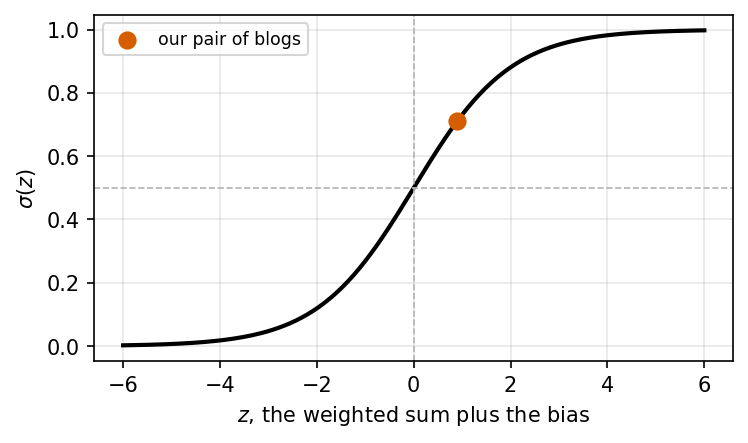

In [3]:
zs = np.linspace(-6, 6, 200)

fig, ax = plt.subplots(1, 1, figsize=(5.5, 3), dpi=150)
ax.plot(zs, sigmoid(zs), color='k', lw=2)
ax.scatter([z], [sigmoid(z)], color=TWO[1], s=60, zorder=3, label='our pair of blogs')
ax.axhline(0.5, color='0.7', lw=0.8, ls='--')
ax.axvline(0, color='0.7', lw=0.8, ls='--')

ax.set_xlabel('$z$, the weighted sum plus the bias')
ax.set_ylabel(r'$\sigma(z)$')
ax.legend(loc='upper left', fontsize='small')
ax.grid(alpha=0.3)

plt.show()

Our pair lands a little right of zero, so the neuron says 0.711. Notice the shape of the curve. It's steepest at $z = 0$ and flattens out at both ends, so once $z$ is far from 0, changing it barely changes $\hat{y}$.

Now let's see what this neuron says for every pair of blogs at once. Each pair is a point $(x_1, x_2)$, so we can color the plane by what the neuron says at each point. Same side is only ever 0 or 1, but the neuron will take any number, so we'll color in everything in between too.

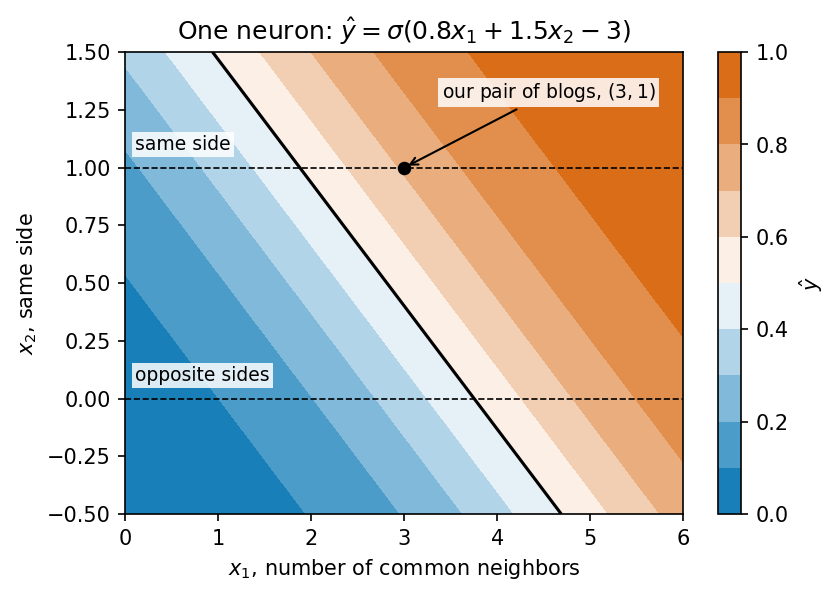

In [4]:
# Every point of the plane, and what our neuron says at each one
x1s, x2s = np.meshgrid(np.linspace(0, 6, 200), np.linspace(-0.5, 1.5, 200))
y_hat_plane = sigmoid(w[0] * x1s + w[1] * x2s + b)

fig, ax = plt.subplots(1, 1, figsize=(6, 4), dpi=150)
filled = ax.contourf(x1s, x2s, y_hat_plane, levels=np.linspace(0, 1, 11), cmap=shade)
ax.contour(x1s, x2s, y_hat_plane, levels=[0.5], colors='k', linewidths=1.5)

# The two rows that real pairs of blogs can be on
for row, label in [(1, 'same side'), (0, 'opposite sides')]:
    ax.axhline(row, color='k', lw=0.8, ls='--')
    ax.text(0.1, row + 0.06, label, ha='left', va='bottom', fontsize=9,
            bbox=dict(fc='white', ec='none', alpha=0.85, pad=1.5))

ax.scatter(*x, color='k', s=30, zorder=3)
ax.annotate('our pair of blogs, $(3, 1)$', xy=x, xytext=(3.4, 1.3), fontsize=9,
            bbox=dict(fc='white', ec='none', alpha=0.85, pad=1.5), arrowprops=dict(arrowstyle='->'))
plt.colorbar(filled, ax=ax, label=r'$\hat{y}$')

ax.set_xlabel('$x_1$, number of common neighbors')
ax.set_ylabel('$x_2$, same side')
ax.set_title(r'One neuron: $\hat{y} = \sigma(0.8 x_1 + 1.5 x_2 - 3)$')

plt.show()

The black line is where $0.8 x_1 + 1.5 x_2 - 3 = 0$, so the neuron says exactly 0.5 all along it. Above the line it says more than 0.5 (orange), below the line it says less (blue), and the farther a point is from the line, the more sure the neuron is.

Notice what the line says about blogs. For two blogs on the same side, 2 common neighbors are enough to get past 0.5, and for blogs on opposite sides it takes 4. Changing the weights and the bias tilts the line and slides it around, but it's always a straight line.

### A little history

Model neurons like this one go back more than 80 years, and they started as a simplified version of the neurons in the brain. A real neuron gets signals from other neurons through connections called synapses, and it fires when enough signals arrive at about the same time. When we learn something, some of those connections get stronger and others get weaker. In a model neuron, the inputs are numbers, each connection has a weight that says how strong it is, and the output is one number.

![natural and artificial neurons](./images/history_nobel2024_neurons.jpg)

*From the [popular science background](https://www.nobelprize.org/prizes/physics/2024/popular-information/) for the 2024 Nobel Prize in Physics. © Johan Jarnestad/The Royal Swedish Academy of Sciences.*

The right half of the drawing describes one particular rule for learning the weights: connections between nodes that are active at the same time get stronger. This is called Hebbian learning, after the psychologist Donald Hebb, and it's how Hopfield's network (1982, below) stores patterns. The networks we'll train today learn their weights a different way, with gradient descent, later in Part 1.

**1943.** Warren McCulloch and Walter Pitts described a model neuron that adds up its inputs and outputs 1 if the total is above a threshold and 0 otherwise (a step instead of the sigmoid). They showed that networks of these neurons can compute logical functions like AND, OR and AND NOT (this input but not that one). They didn't give a way to learn the connections from examples. Each network was designed by hand to compute a particular logical formula. Here are the first four drawings from their Figure 1:

![Figure 1, panels (a) to (d), from McCulloch & Pitts (1943)](./images/history_mcculloch_pitts_1943.png)

*Figure 1, panels (a) to (d), from McCulloch & Pitts (1943), as reprinted in the Bulletin of Mathematical Biology in 1990.*

Each triangle is a neuron, labeled with its number, and its output leaves to the right. Each black dot is a connection that excites the neuron, and the open circle in (d) is a connection that blocks it from firing. In these drawings, a neuron fires when at least two of its black dots get a signal at once, and it fires one time step after its inputs.
- (a) Neuron 1 has two dots on neuron 2, so neuron 2 copies neuron 1, one time step later.
- (b) Neuron 1 has two dots on neuron 3, and so does neuron 2. Neuron 3 fires if neuron 1 **or** neuron 2 fired.
- (c) Neurons 1 and 2 have one dot each on neuron 3, so neuron 3 fires only if neuron 1 **and** neuron 2 fired.
- (d) Neuron 3 fires if neuron 1 fired **and not** neuron 2.

**1958.** Frank Rosenblatt's **perceptron** learned its weights from labeled examples. During training it was shown labeled examples, and feedback on its answers changed the strengths of its connections. Rosenblatt's group also built a perceptron as a machine, the Mark I Perceptron:

![the Mark I Perceptron](./images/history_mark1_perceptron.jpg)

*The Mark I Perceptron at the Cornell Aeronautical Laboratory, in a U.S. Navy photo released in 1960. National Museum of the U.S. Navy, public domain.*

The lamps light up a card with the letter C on it for the machine to look at. The machine's input was a 20 × 20 grid of 400 light sensors, so each image it saw was 400 numbers. The weights it learned were dials (potentiometers), and during training, small electric motors turned the dials.

**1969.** Marvin Minsky and Seymour Papert's book *Perceptrons* worked out what a single layer of these neurons can and can't compute. The simplest thing it can't compute is XOR (below). The book is often blamed for a slump in neural network research through the 1970s.

**1982.** John Hopfield, a physicist, built a network of neurons that stores patterns and recovers a whole pattern from part of it, using an energy function borrowed from models of magnetic spins.

![a Hopfield network recalling a stored pattern](./images/history_nobel2024_hopfield.jpg)

*From the [popular science background](https://www.nobelprize.org/prizes/physics/2024/popular-information/) for the 2024 Nobel Prize in Physics. © Johan Jarnestad/The Royal Swedish Academy of Sciences.*

Storing a pattern carves a valley into the network's energy. To recall a pattern, we start the network at a noisy or partial version of it (top right) and let one neuron at a time switch on or off, whichever lowers the energy. The energy never goes up, so the network ends up at the bottom of a valley. If it started close enough to a stored pattern, that's the pattern it ends up at (bottom right). If it started too far away, it can end up in a different valley, and some valleys aren't any of the stored patterns.

**1986.** David Rumelhart, Geoffrey Hinton and Ronald Williams showed that **backpropagation** can train neural networks with hidden layers, and that the hidden neurons learn useful features on their own. A hidden layer is a layer of neurons in between the inputs and the output, and backpropagation is a way to work out, from the network's mistakes, which way to change each of its weights (Appendix A has the details). The method itself is older, but this paper is what got people using it.

Hopfield and Hinton shared the [2024 Nobel Prize in Physics](https://www.nobelprize.org/prizes/physics/2024/press-release/) for their early work on neural networks.

Here's XOR ("exclusive or"). It takes two inputs that are each 0 or 1, and its answer is 1 when exactly one of them is 1:

In [5]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])          # 1 when exactly one input is 1

for (x1, x2), answer in zip(X_xor, y_xor):
    print(f'x1 = {x1}, x2 = {x2}   ->   XOR = {answer}')

x1 = 0, x2 = 0   ->   XOR = 0
x1 = 0, x2 = 1   ->   XOR = 1
x1 = 1, x2 = 0   ->   XOR = 1
x1 = 1, x2 = 1   ->   XOR = 0


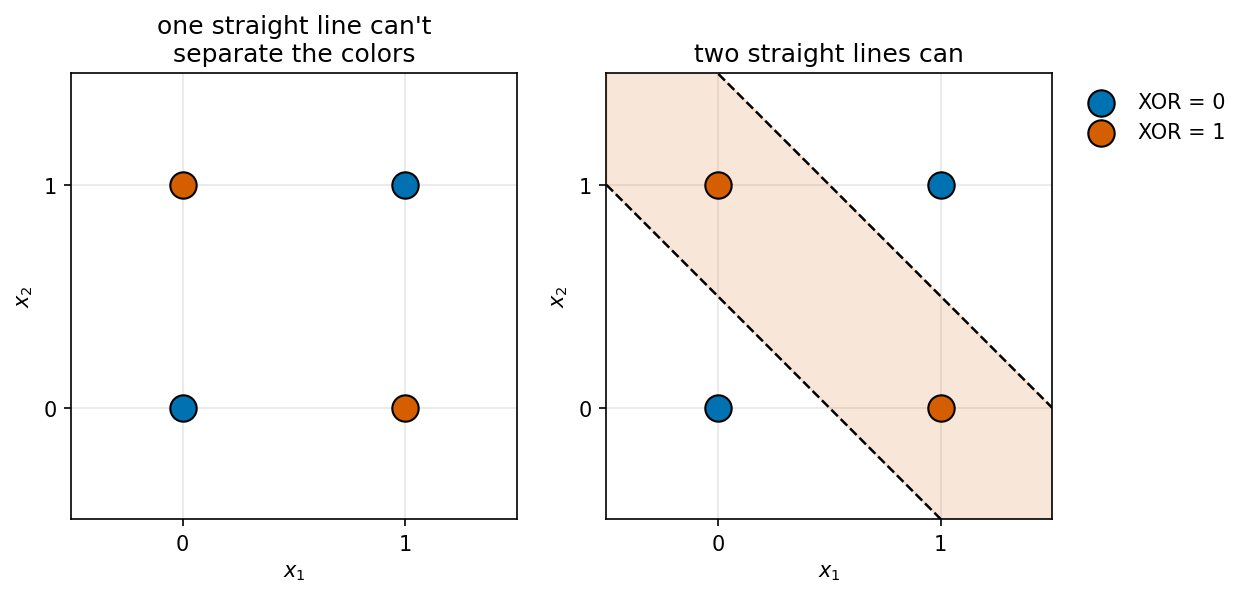

In [6]:
line_x = np.array([-0.5, 1.5])

fig, axes = plt.subplots(1, 2, figsize=(8.5, 4), dpi=150)

for ax in axes:
    for c in [0, 1]:
        ax.scatter(*X_xor[y_xor == c].T, s=160, color=TWO[c], edgecolor='k', zorder=3, label=f'XOR = {c}')

    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_aspect('equal')
    ax.grid(alpha=0.3)

# right panel: the lines x1 + x2 = 0.5 and x1 + x2 = 1.5, with the band between them shaded
axes[1].fill_between(line_x, 0.5 - line_x, 1.5 - line_x, color=TWO[1], alpha=0.15)

for offset in [0.5, 1.5]:
    axes[1].plot(line_x, offset - line_x, color='k', ls='--', lw=1.2)

axes[0].set_title("one straight line can't\nseparate the colors")
axes[1].set_title('two straight lines can')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)

plt.tight_layout()
plt.show()

Each panel shows the four possible inputs, colored by XOR's answer. On the left, try to draw one straight line with both orange points on one side and both blue points on the other. There's no such line, because the segment joining the two orange points and the segment joining the two blue points cross at $(0.5, 0.5)$, and that point can't be on both sides of a line. So a single neuron can't compute XOR, whatever its weights are.

On the right, the two dashed lines are $x_1 + x_2 = 0.5$ and $x_1 + x_2 = 1.5$, and the orange points are exactly the ones between them. In a neural network with a hidden layer of two neurons, each hidden neuron can draw one of these lines, and the output neuron can then say 1 for the points between them. For example, let the first hidden neuron output 1 when $x_1 + x_2 > 0.5$ and the second output 1 when $x_1 + x_2 > 1.5$ (threshold neurons, like McCulloch and Pitts'). The first output minus the second is 0 at $(0, 0)$, 1 at $(0, 1)$ and $(1, 0)$, and 0 at $(1, 1)$, which is XOR. Finding weights like these from data, instead of by hand, is what backpropagation made practical.

Let's see what one neuron does on data where a line isn't enough. Here are 400 points in two interlocking crescents (scikit-learn calls them "moons"). Each point has two features, its $x_1$ and $x_2$ coordinates, and a class, 0 (blue) or 1 (orange). These two numbers don't stand for anything. We use made-up data here because we can draw every point in one picture, and because it's built so that no straight line can separate the two classes. Real data usually have many more features, like the 1,433 per paper in Part 3, and we can't draw those, but a neural network handles them the same way. Like on Wednesday, we hold out a test set, here a quarter of the points.

In [7]:
X_moons, y_moons = make_moons(n_samples=400, noise=0.2, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.25, random_state=SEED)

print(len(X_train), 'training points,', len(X_test), 'test points')

300 training points, 100 test points


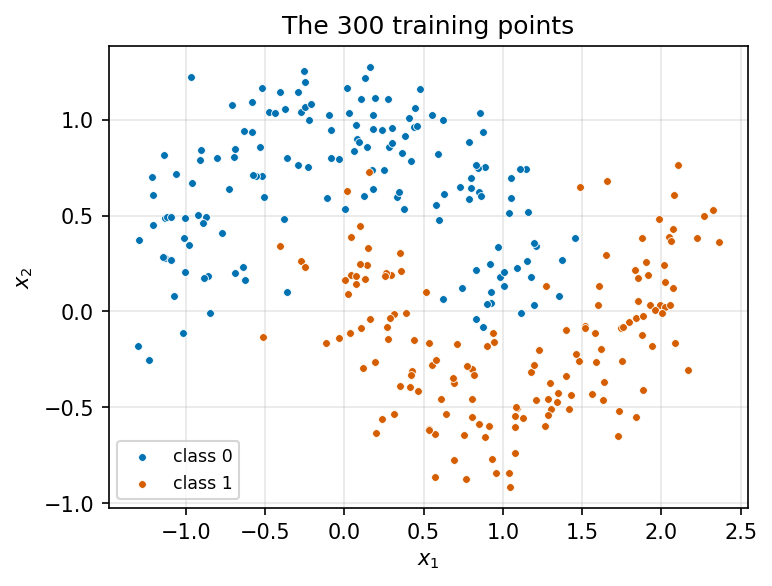

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(5.5, 4), dpi=150)

for c in [0, 1]:
    ax.scatter(*X_train[y_train == c].T, s=14, color=TWO[c], edgecolor='w', linewidth=0.4, label=f'class {c}')

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title(f'The {len(X_train)} training points')
ax.legend(loc='lower left', fontsize='small')
ax.grid(alpha=0.3)

plt.show()

Each dot is one training point, drawn at its $(x_1, x_2)$ and colored by its class. Try to imagine a straight line with all of the blue points on one side and all of the orange points on the other. There isn't one, because the tip of each crescent pokes into the other one. Let's see what logistic regression does anyway. First, a helper function that colors the background by a model's guess, the same way we colored the plane above.

In [9]:
# A fine grid of points covering the plot. We'll ask a model for its guess at every grid point
# and color the background by the answer.
xx, yy = np.meshgrid(np.linspace(-1.7, 2.7, 300), np.linspace(-1.3, 1.8, 300))
grid = np.column_stack([xx.ravel(), yy.ravel()])


def plot_boundary(model, ax, title='', points=True):
    p = model.predict_proba(grid)[:, 1].reshape(xx.shape)   # the model's probability of class 1
    ax.contourf(xx, yy, p, levels=np.linspace(0, 1, 11), cmap=shade, alpha=0.35)
    ax.contour(xx, yy, p, levels=[0.5], colors='k', linewidths=1.5)
    if points:
        for c in [0, 1]:
            ax.scatter(*X_train[y_train == c].T, s=14, color=TWO[c], edgecolor='w', linewidth=0.4,
                       label=f'class {c}')

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)

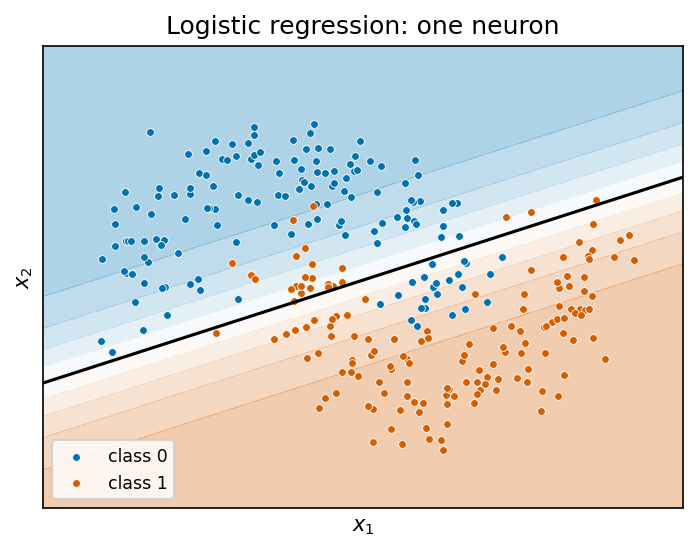

Test accuracy: 0.81


In [10]:
logreg = LogisticRegression().fit(X_train, y_train)

fig, ax = plt.subplots(1, 1, figsize=(5.5, 4), dpi=150)
plot_boundary(logreg, ax, 'Logistic regression: one neuron')

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.legend(loc='lower left', fontsize='small')

plt.show()

print(f'Test accuracy: {logreg.score(X_test, y_test):.2f}')

The black line is where the model says exactly 0.5, and the shading shows how sure it is on each side. The line gets most points right, but it has to get the tips of both crescents wrong, because no straight line can separate these two interlocking crescents.

What can we do? On Wednesday we built extra features by hand. The other option is to let the model build its own features, and that's what a neural network does.

### Stacking neurons into a network
(this section borrows from the coverage of ML in Bagrow & Ahn, section 16.2)

Instead of one neuron, we use several. Each neuron in the first layer looks at the inputs and draws its own line. Then one more neuron takes *their* outputs as its inputs and combines them into the final answer. These can seem complicated to understand, but they are, at their heart, just doing a bunch of very parallelizable matrix operations.

Neural networks consist of sets of units (neurons) arranged in a sequence of layers. When we talk about the **architecture** of a neural network, we're talking about how the units are arranged, how many of them there are, how many layers we have, and the number of units per layer. In a fully connected feed-forward network, each unit in each layer is connected to all the units in the layer after it. First, the input units receive the input data. Data moves through the network in the picture from left to right. Here's the network we'll train in a minute:

![feed-forward neural network](./images/network.png)

On the left are the two inputs, $x_1$ and $x_2$. The 16 circles in the middle are the **hidden layer**, called that because our data only says what the final output should be, and never what the 16 neurons in the middle should output. There's nothing special about 16. The number of hidden neurons is a choice we make before training, and at the end of Part 1 we'll see what happens with only 8. Every gray line is a weight, and every hidden neuron gets both inputs. The one circle on the right is the output neuron, which takes all 16 hidden outputs as its inputs and gives $\hat{y}$.

Every neuron works like the one we started with. The output of a particular unit is $\sigma(\vec{x} \cdot \vec{w} + b)$, where $\vec{w}$ is the weights of the inputs for that unit, $\vec{x}$ is the inputs coming from the previous layer, and $b$ is the unit's bias. ($\vec{x} \cdot \vec{w}$ is the same weighted sum $w_1 x_1 + w_2 x_2 + \dots$ as before, written with vectors.) The function we apply to the weighted sum is called the unit's **activation function**. In logistic regression it was the sigmoid, but it doesn't have to be, so from here on $\sigma$ stands for whichever one we pick. The output neuron in our picture uses the sigmoid, so that $\hat{y}$ is a probability. The hidden neurons use a different one, the ReLU (the R in each circle), which we'll get to in a second.

### Why do we need an activation function at all?

Suppose we skip it, and pass each weighted sum straight on to the next layer. Let's try it. In practice we compute a whole layer at once. Treat the input $x$ as a row vector, and put each neuron's weights in one column of a matrix $W$. Then $xW$ gives every neuron's weighted sum at the same time, one number per neuron. Here are two layers of weights with nothing in between, next to one layer whose weight matrix is the product of the two:

In [11]:
rng = np.random.default_rng(SEED)
W1 = rng.normal(size=(2, 8))   # layer 1: 2 inputs -> 8 neurons, one column per neuron
W2 = rng.normal(size=(8, 1))   # layer 2: 8 neurons -> 1 output
x = np.array([2, -1])          # one example, as a row vector

print('two layers, nothing in between:', (x @ W1) @ W2)
print('one layer with W = W1 @ W2:    ', x @ (W1 @ W2))
print('W1 @ W2 has shape', (W1 @ W2).shape, '-> one neuron with two weights')

two layers, nothing in between: [4.87876855]
one layer with W = W1 @ W2:     [4.87876855]
W1 @ W2 has shape (2, 1) -> one neuron with two weights


They're the same, because $(xW_1)W_2 = x(W_1 W_2)$, and that's true for any input and any weights. $W_1 W_2$ has 2 rows and 1 column, so the two layers are really one neuron with two weights. Without activation functions, any number of layers collapses into a single layer, and we'd be back to one straight line.

So what does an activation function change? Let's look at the simplest case we can draw: one input $x$, two neurons, and the **ReLU** (rectified linear unit) as the activation function,

$$\text{ReLU}(z) = \max(0, z).$$

It passes positive numbers through unchanged and turns negative numbers into 0, so $\text{ReLU}(3) = 3$ and $\text{ReLU}(-2) = 0$. Our two neurons have weighted sums $x - 1$ and $-0.5x - 1$, and we add up their outputs, first without an activation function and then with the ReLU.

In [12]:
def relu(z):
    return np.maximum(0, z)


print('ReLU(3) =', relu(3), '  ReLU(-2) =', relu(-2))

ReLU(3) = 3   ReLU(-2) = 0


In [13]:
xs = np.linspace(-3, 3, 301)
z_1, z_2 = xs - 1, -0.5 * xs - 1  # the two neurons' weighted sums

# For the last panel: 8 ReLU neurons that switch on at 8 different points, added up so that
# they trace the gray curve. Each neuron's output weight is how much the slope changes at its point.
knots = np.linspace(-3, 3, 9)
target = np.sin(1.5 * knots)
slopes = np.diff(target) / np.diff(knots)
out_weights = np.diff(slopes, prepend=0)
traced = target[0] + sum(c * relu(xs - k) for c, k in zip(out_weights, knots[:-1]))

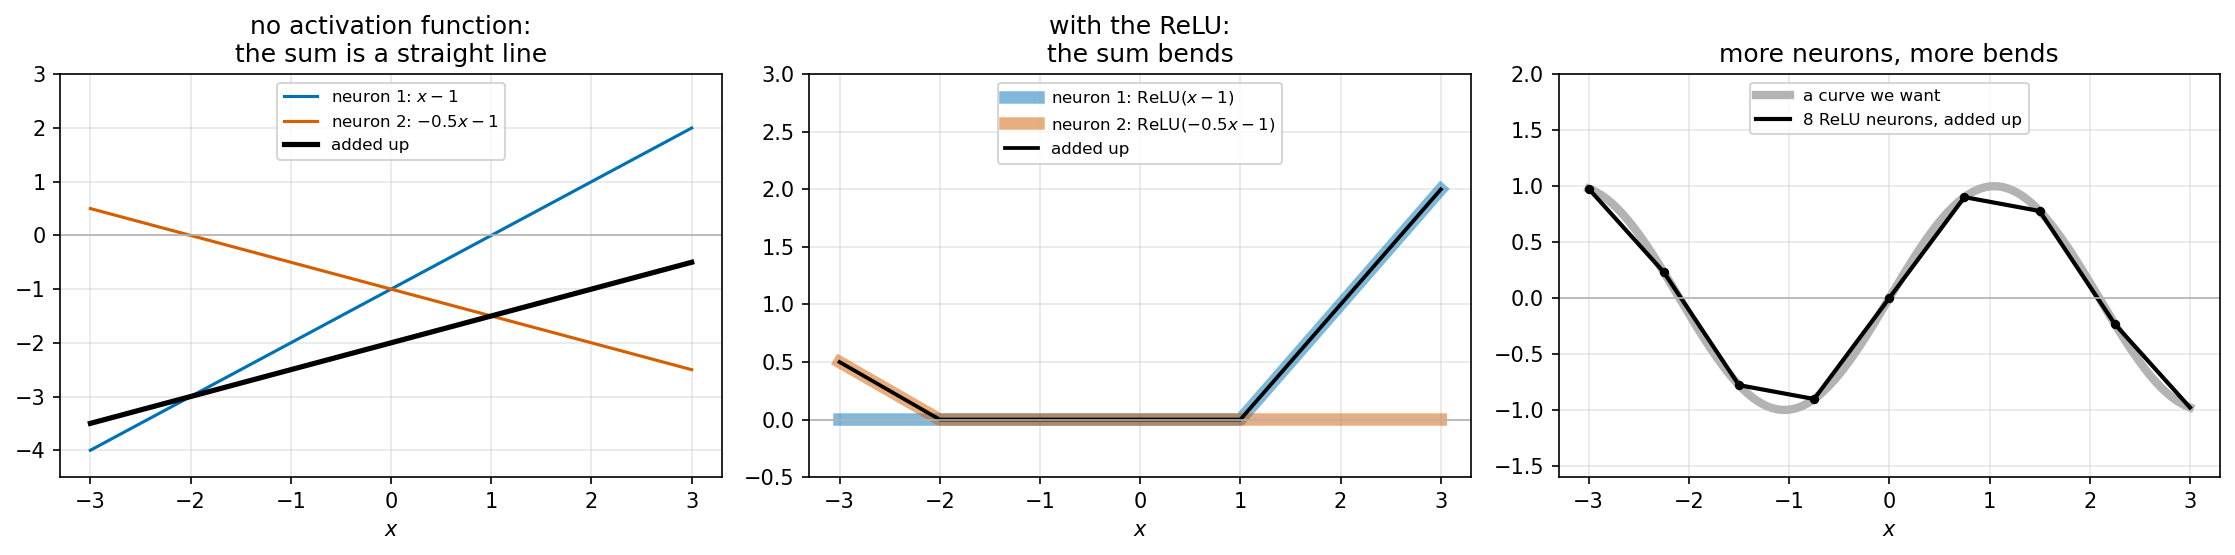

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), dpi=150)
axes[0].plot(xs, z_1, color=TWO[0], lw=1.5, label='neuron 1: $x - 1$')
axes[0].plot(xs, z_2, color=TWO[1], lw=1.5, label='neuron 2: $-0.5x - 1$')
axes[0].plot(xs, z_1 + z_2, color='k', lw=2.5, label='added up')
axes[0].set_title('no activation function:\nthe sum is a straight line')

axes[1].plot(xs, relu(z_1), color=TWO[0], lw=6, alpha=0.5, label=r'neuron 1: ReLU$(x - 1)$')
axes[1].plot(xs, relu(z_2), color=TWO[1], lw=6, alpha=0.5, label=r'neuron 2: ReLU$(-0.5x - 1)$')
axes[1].plot(xs, relu(z_1) + relu(z_2), color='k', lw=1.8, label='added up')
axes[1].set_title('with the ReLU:\nthe sum bends')

axes[2].plot(xs, np.sin(1.5 * xs), color='0.7', lw=4, label='a curve we want')
axes[2].plot(xs, traced, color='k', lw=2, label='8 ReLU neurons, added up')
axes[2].scatter(knots[:-1], target[:-1], color='k', s=12, zorder=3)
axes[2].set_title('more neurons, more bends')

for ax in axes:
    ax.axhline(0, color='0.7', lw=0.8)
    ax.set_xlabel('$x$')
    ax.legend(loc='upper center', fontsize=8)
    ax.grid(alpha=0.3)

axes[0].set_ylim(-4.5, 3)
axes[1].set_ylim(-0.5, 3)
axes[2].set_ylim(-1.6, 2)

plt.tight_layout()
plt.show()

In the left panel the two neurons' weighted sums are straight lines, and so is their sum. That would be true for any weights. In the middle panel the ReLU flattens each line to 0 on one side, and their sum has two bends in it, which no straight line can do. In the right panel there are 8 ReLU neurons, each one switching on at a different black dot, and we picked their output weights so that each one changes the slope by just the right amount at its dot. Each neuron adds one bend, and with enough bends we can follow pretty much any curve we want.

The weights choose where the bends go and how sharp they are, and the activation functions are what make bending possible in the first place. In our network the input has two numbers instead of one, so each hidden neuron bends along a line in the plane instead of at a point, and we'll see those lines in a few minutes. A trained network finds weights like these by itself.

### The usual activation functions

There are lots of activation functions, and these are the three you'll see most. The **sigmoid** is the one from logistic regression. **tanh** (the hyperbolic tangent) has the same S shape, but goes from $-1$ to 1 instead of 0 to 1. And the **ReLU** is the one we just used. All three are nonlinear, so a network whose hidden neurons use any of them can draw a boundary that bends.

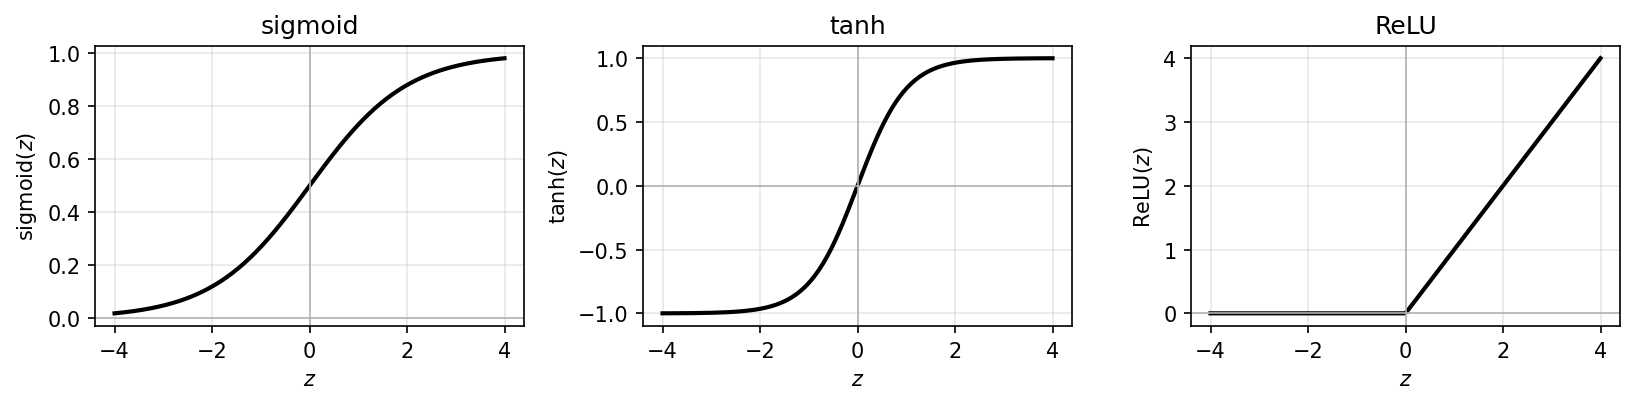

In [15]:
zs = np.linspace(-4, 4, 200)
activations = {'sigmoid': sigmoid(zs), 'tanh': np.tanh(zs), 'ReLU': relu(zs)}

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), dpi=150)

for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(zs, values, color='k', lw=2)
    ax.axhline(0, color='0.7', lw=0.8)
    ax.axvline(0, color='0.7', lw=0.8)

    ax.set_title(name)
    ax.set_xlabel('$z$')
    ax.set_ylabel(f'{name}($z$)')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Notice that the sigmoid and tanh flatten out at both ends, and the ReLU is completely flat (exactly 0) for every negative number. Those flat parts matter for training, and they're the main thing to think about when choosing an activation function for the hidden layers.

### Training: nudging the weights

The network in the picture has $2 \times 16 = 32$ weights going into the hidden layer, 16 hidden biases, 16 weights going into the output, and 1 output bias. That's 65 numbers, and training is how we pick them.

The outputs we get from each unit in the middle layer are passed to the final layer, and then we compare the final layer's output to our desired output. Our task is to use a **loss function**, of which there are many, to express how far off we are from our correct answer. Then we nudge the weights ($\vec{w}$) towards values that would be closer to producing the desired label, which means values that make the loss smaller.

Our choice of loss function is important here; what works well for classifying products may be terrible for predicting flight prices, for example. We might use a squared error loss function if we're predicting flight prices, and we might use a cross-entropy loss function to quantify how incorrect our predictions are for a classifier. Here we have a classifier, so we'll use the cross-entropy loss (also called log loss). It's the loss that scikit-learn's logistic regression and its neural network classifier both make as small as they can when we fit them, along with a small penalty that keeps the weights from getting too big. For a training point in class 1 it's $-\log \hat{y}$, and for a point in class 0 it's $-\log(1 - \hat{y})$, where $\log$ is the natural log. Here's what those two look like:

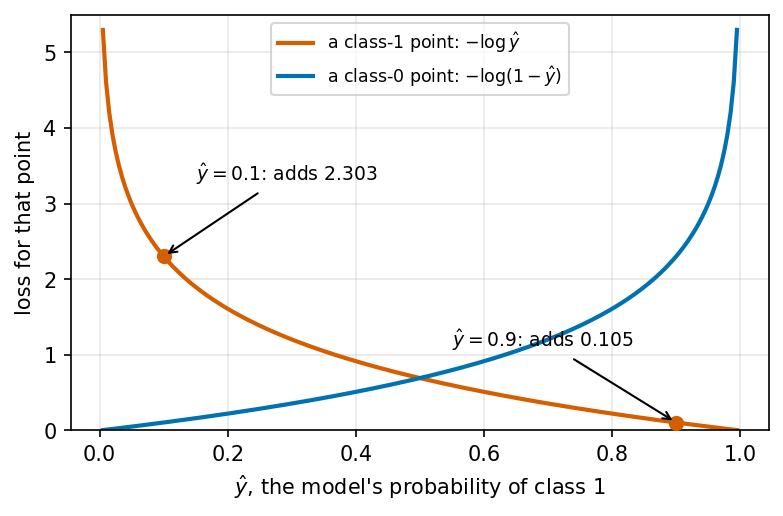

In [16]:
y_hats = np.linspace(0.005, 0.995, 200)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.6), dpi=150)
ax.plot(y_hats, -np.log(y_hats), color=TWO[1], lw=2, label=r'a class-1 point: $-\log \hat{y}$')
ax.plot(y_hats, -np.log(1 - y_hats), color=TWO[0], lw=2, label=r'a class-0 point: $-\log(1 - \hat{y})$')

for p, (dx, dy) in [(0.9, (-0.35, 1.0)), (0.1, (0.05, 1.0))]:
    ax.scatter([p], [-np.log(p)], color=TWO[1], s=40, zorder=3)
    ax.annotate(rf'$\hat{{y}} = {p}$: adds {-np.log(p):.3f}', xy=(p, -np.log(p)), xytext=(p + dx, -np.log(p) + dy),
                fontsize=9, arrowprops=dict(arrowstyle='->'))

ax.set_xlabel(r"$\hat{y}$, the model's probability of class 1")
ax.set_ylabel('loss for that point')
ax.set_ylim(0, 5.5)
ax.legend(loc='upper center', fontsize='small')
ax.grid(alpha=0.3)

plt.show()

Take a class-1 point, the orange curve. If the model gives it $\hat{y} = 0.9$, it adds $-\log 0.9 = 0.105$ to the loss, and if it gives it $\hat{y} = 0.1$, it adds $-\log 0.1 = 2.303$. The curve shoots up as $\hat{y}$ heads toward 0, so being confidently wrong is expensive. The blue curve does the same for class-0 points, which should get a $\hat{y}$ close to 0. The training loss is the average over all of the training points, and a model that said 0.5 for every point would get $-\log 0.5 = 0.693$.

How do we know which way to nudge? Let's look at just one weight. Take the logistic regression from above, keep its bias and its second weight where they are, and slide its first weight $w_1$ back and forth. For every value of $w_1$ we can compute the training loss, which gives us a curve. We'll start from a bad value, $w_1 = -3$, and measure the **slope** of the curve there: nudge $w_1$ a tiny bit in each direction, see how much the loss changes, and divide by how much $w_1$ changed (rise over run).

In [17]:
# Keep the bias and the second weight where logistic regression put them, and only change w1
w2_fixed, b_fixed = logreg.coef_[0, 1], logreg.intercept_[0]


def loss_w1(w1):
    p = sigmoid(w1 * X_train[:, 0] + w2_fixed * X_train[:, 1] + b_fixed)   # y-hat for every training point
    return np.mean(-np.log(np.where(y_train == 1, p, 1 - p)))              # the average cross-entropy loss


def slope(w1, tiny=1e-4):
    # rise over run: the change in the loss, divided by a tiny change in w1
    return (loss_w1(w1 + tiny) - loss_w1(w1 - tiny)) / (2 * tiny)


w1_values = np.linspace(-4, 9, 300)
loss_curve = np.array([loss_w1(w) for w in w1_values])
best_w1 = w1_values[loss_curve.argmin()]

print(f'start:       w1 = {-3:.2f}, loss = {loss_w1(-3):.3f}, slope = {slope(-3):.3f}')
print(f'lowest loss: w1 = {best_w1:.2f}, loss = {loss_curve.min():.3f}')

start:       w1 = -3.00, loss = 1.638, slope = -0.563
lowest loss: w1 = 1.22, loss = 0.285


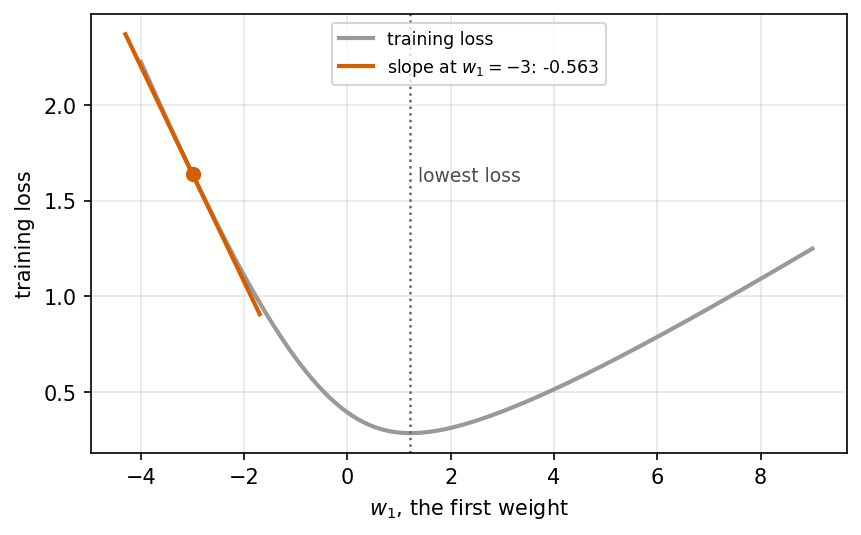

In [18]:
w_start = -3.0
near = np.linspace(w_start - 1.3, w_start + 1.3, 2)   # a short stretch around the starting point

fig, ax = plt.subplots(1, 1, figsize=(6.5, 3.8), dpi=150)
ax.plot(w1_values, loss_curve, color='0.6', lw=2, label='training loss')
ax.plot(near, loss_w1(w_start) + slope(w_start) * (near - w_start), color=TWO[1], lw=2,
        label=f'slope at $w_1 = -3$: {slope(w_start):.3f}')
ax.scatter([w_start], [loss_w1(w_start)], color=TWO[1], s=40, zorder=3)
ax.axvline(best_w1, color='0.4', ls=':', lw=1.2)
ax.text(best_w1 + 0.15, 1.6, 'lowest loss', fontsize=9, color='0.3')

ax.set_xlabel('$w_1$, the first weight')
ax.set_ylabel('training loss')
ax.legend(loc='upper center', fontsize='small')
ax.grid(alpha=0.3)

plt.show()

The gray curve is the training loss for every value of $w_1$, with everything else held fixed, and we want to end up at its lowest point, around $w_1 = 1.2$ (the dotted line). The orange line touches the curve at our starting point, and its slope is the slope of the curve there, $-0.563$. A negative slope means the loss goes down as $w_1$ goes up, so to go downhill we should make $w_1$ bigger. That's the idea behind **gradient descent**: measure the slope where we are, and take a step downhill,

$$w_1 \leftarrow w_1 - \eta \times \text{slope}.$$

Here $\eta$ (the Greek letter eta) is the **learning rate**, which sets how big the steps are, and the arrow means "replace $w_1$ with". The minus sign is what sends us downhill: where the slope is negative, $w_1$ gets bigger, and where it's positive, $w_1$ gets smaller. For example, with $\eta = 3$ the first step takes us from $-3$ to $-3 - 3 \times (-0.563) = -1.31$:

In [19]:
w1 = -3.0
w1 = w1 - 3 * slope(w1)     # one step of gradient descent, with learning rate 3

print(f'after one step: w1 = {w1:.2f}, loss = {loss_w1(w1):.3f}')

after one step: w1 = -1.31, loss = 0.797


The loss dropped from 1.638 to 0.797 in one step. Near the bottom the curve flattens out, so the slope gets close to 0, and so do the steps. How big should $\eta$ be? Let's take 8 steps from $w_1 = -3$ with three different learning rates.

In [20]:
paths = {}

for learning_rate in [0.5, 3, 20]:
    steps = [-3.0]                                                     # the bad starting value

    for step in range(8):
        steps.append(steps[-1] - learning_rate * slope(steps[-1]))     # one step downhill

    paths[learning_rate] = steps

for learning_rate, steps in paths.items():
    print(f'learning rate {learning_rate:>3}:  w1 =', np.round(steps, 1))

learning rate 0.5:  w1 = [-3.  -2.7 -2.4 -2.2 -1.9 -1.7 -1.5 -1.2 -1. ]
learning rate   3:  w1 = [-3.  -1.3 -0.1  0.5  0.8  1.   1.1  1.1  1.2]
learning rate  20:  w1 = [-3.   8.3  5.1  2.3  0.7  2.1  0.7  2.1  0.7]


Each row lists $w_1$ after each step, starting from $-3$. Here are the same steps drawn on the loss curve:

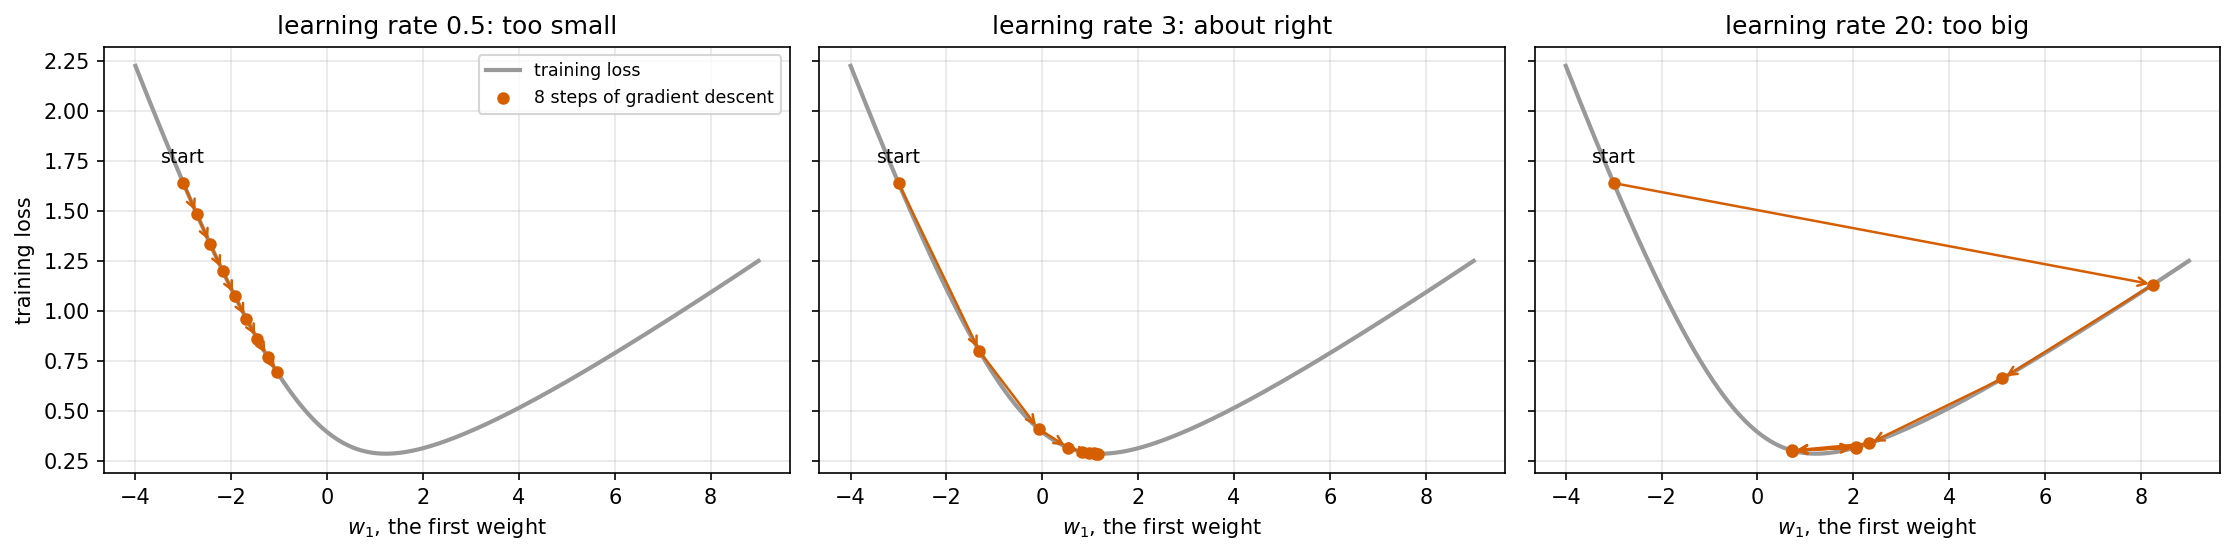

In [21]:
verdicts = {0.5: 'too small', 3: 'about right', 20: 'too big'}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), dpi=150, sharey=True)

for ax, (learning_rate, steps) in zip(axes, paths.items()):
    step_losses = [loss_w1(w) for w in steps]

    # the loss curve, with the starting point marked
    ax.plot(w1_values, loss_curve, color='0.6', lw=2, label='training loss')
    ax.text(steps[0], step_losses[0] + 0.08, 'start', ha='center', va='bottom', fontsize=9)

    # one arrow for each step
    for w_from, w_to, loss_from, loss_to in zip(steps[:-1], steps[1:], step_losses[:-1], step_losses[1:]):
        ax.annotate('', xy=(w_to, loss_to), xytext=(w_from, loss_from),
                    arrowprops=dict(arrowstyle='->', color=TWO[1], lw=1.2))

    ax.scatter(steps, step_losses, color=TWO[1], s=25, zorder=3, label='8 steps of gradient descent')

    ax.set_title(f'learning rate {learning_rate}: {verdicts[learning_rate]}')
    ax.set_xlabel('$w_1$, the first weight')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('training loss')
axes[0].legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

Each orange arrow is one step. With a learning rate of 0.5, eight steps don't get anywhere near the bottom. With 3, the loss is close to its lowest value after four or five steps. With 20, the first step flies way past the bottom, all the way to about $w_1 = 8$. The next few steps come back down the right side, and then the weight hops back and forth between about 0.7 and 2.1, on either side of the bottom at 1.2, without settling down.

### From one weight to all 65

A real network does the same thing with every weight at once. Each of our 65 numbers gets its own slope (all of the slopes together are called the **gradient**, which is where the name gradient descent comes from), and each one takes a step downhill. Working out 65 slopes by nudging each weight separately, like we just did with one, gets slow for big networks. Instead we use an algorithm called **backpropagation**, which computes all of the slopes in one pass backward through the network. Appendix A at the end walks through backpropagation if you want the details.

### Back to activation functions: how do we choose one?

For a weight going into a hidden neuron, the slope of the loss is a product of several factors (that's the chain rule, which is what backpropagation uses), and one of those factors is the slope of the neuron's activation function, at whatever the neuron's weighted sum is. If the activation function is flat there, its slope is close to 0, so the whole product is close to 0, and the weight barely moves. Here are the slopes of our three activation functions:

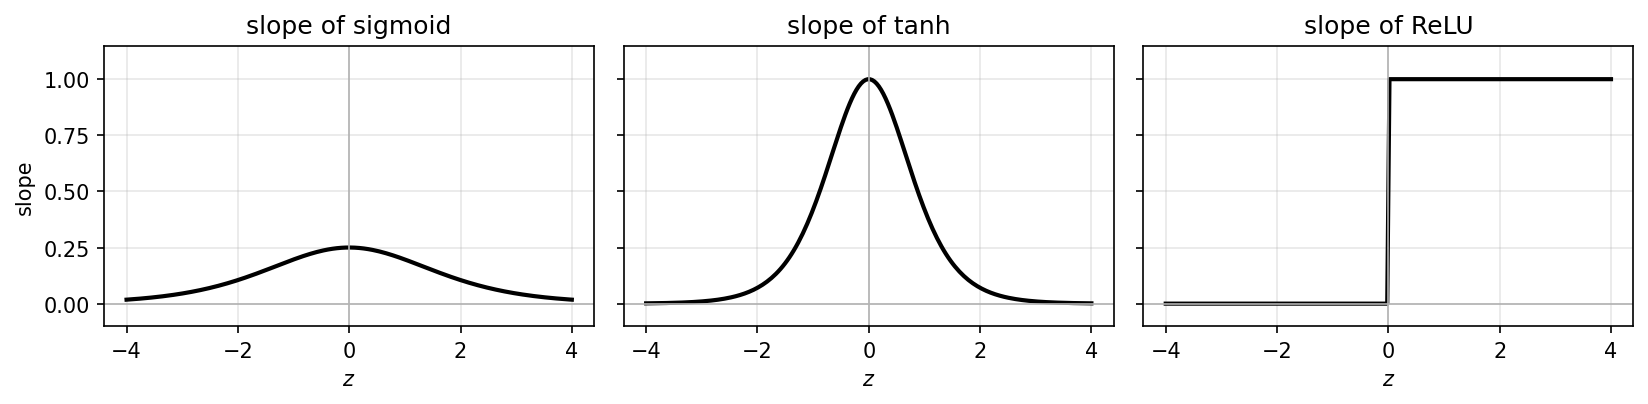

In [22]:
sig = sigmoid(zs)
activation_slopes = {'sigmoid': sig * (1 - sig), 'tanh': 1 - np.tanh(zs) ** 2, 'ReLU': (zs > 0).astype(float)}

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), dpi=150, sharey=True)

for ax, (name, values) in zip(axes, activation_slopes.items()):
    ax.plot(zs, values, color='k', lw=2)
    ax.axhline(0, color='0.7', lw=0.8)
    ax.axvline(0, color='0.7', lw=0.8)

    ax.set_title(f'slope of {name}')
    ax.set_xlabel('$z$')
    ax.grid(alpha=0.3)

axes[0].set_ylim(-0.1, 1.15)
axes[0].set_ylabel('slope')

plt.tight_layout()
plt.show()

The sigmoid's slope is never more than 0.25, which it hits at $z = 0$, and it's nearly 0 once $z$ is far from 0 in either direction. tanh is steeper in the middle (its slope is 1 at $z = 0$), but it has the same flat ends. In a network with many layers, a change to an early weight has to pass through every layer after it, and the chain rule multiplies in one of these slopes for each layer (along with that layer's weights). With the sigmoid, each of those slopes is at most 0.25, and $0.25^{10}$ is about one in a million, so unless the weights are big, the slopes for the early layers come out tiny and those layers barely learn. People call this the **vanishing gradient** problem. The ReLU's slope is exactly 1 for every positive input, so it doesn't shrink anything as it passes back through the layers, and the ReLU is also very cheap to compute.

On the other side, the ReLU's slope is exactly 0 for every negative input. (At exactly 0 the ReLU has a corner, so it has no slope there, and scikit-learn and PyTorch both just use 0.) A neuron whose weighted sum is negative for every training point gets no nudges from the data at all. We'll find a few of those in our trained network in a minute.

So how do we choose? In practice:
- **Hidden layers:** start with the ReLU. It's a common default, and it's what the GCN in Part 3 uses. There are many variations on it, like the "leaky ReLU", which has a small slope instead of 0 for negative inputs, so a neuron whose weighted sum is negative still gets nudged by the data.
- **Output layer:** this depends on what kind of answer we want. For yes or no (class 0 or 1), we use the sigmoid, so the output is a probability, like in logistic regression and in our network. For one of several classes, we use the **softmax**, which turns a list of scores, one per class, into probabilities that add up to 1 (our GCN in Part 3 uses it). For a number that can be anything, like a price, we use no activation function at all on the output.
- Like the other settings we choose before training, the hidden-layer activation function can be compared on validation data, if there's time to try a few.

### Training our network

Training goes in rounds. One pass through all of the training data is called an **epoch**. Let's train our network for 300 epochs, one at a time, and save a copy of it at a few points along the way so we can watch it learn. In scikit-learn this network is called an `MLPClassifier`, for multi-layer perceptron, an old name for a feed-forward network. By default it uses a fancier version of the stepping rule called Adam, which we'll meet again in Part 3.

There are two more things to know before we train. First, training starts from small random weights. If every weight started at 0, all 16 hidden neurons would compute the same thing, get the same slopes, and stay identical forever, so we'd have one line instead of sixteen. Second, scikit-learn doesn't wait for a whole epoch to take a step. It shuffles the training points, splits them into batches of up to 200, and takes one step per batch, so with our 300 training points that's two steps per epoch. (Because we set `random_state`, the starting weights and the shuffled order come out the same every time we run this.)

We set the learning rate to 0.03. That might look tiny next to the 3 that worked best in the picture above, but Adam's steps work differently. Adam divides each weight's slope by a running average of how big that weight's recent slopes have been, so a step is usually no bigger than about the learning rate, whatever the size of the slope (Kingma & Ba, 2015). That puts Adam's learning rates on a different scale from plain gradient descent's.

In [23]:
mlp = MLPClassifier(hidden_layer_sizes=(16,), activation='relu', learning_rate_init=0.03, random_state=SEED)

snapshots, losses = {}, []
for epoch in range(1, 301):
    mlp.partial_fit(X_train, y_train, classes=[0, 1])   # one more pass through the training data
    losses.append(mlp.loss_)
    if epoch in [1, 10, 30, 300]:
        snapshots[epoch] = copy.deepcopy(mlp)            # a copy of the network as it is right now

n_numbers = sum(W.size for W in mlp.coefs_) + sum(bias.size for bias in mlp.intercepts_)

print('numbers to learn:', n_numbers)
print(f'Test accuracy, logistic regression: {logreg.score(X_test, y_test):.2f}')
print(f'Test accuracy, neural network:      {mlp.score(X_test, y_test):.2f}')

numbers to learn: 65
Test accuracy, logistic regression: 0.81
Test accuracy, neural network:      0.96


Here are the two models' boundaries side by side. Look at what each one does near the tips of the crescents, where each class reaches into the other.

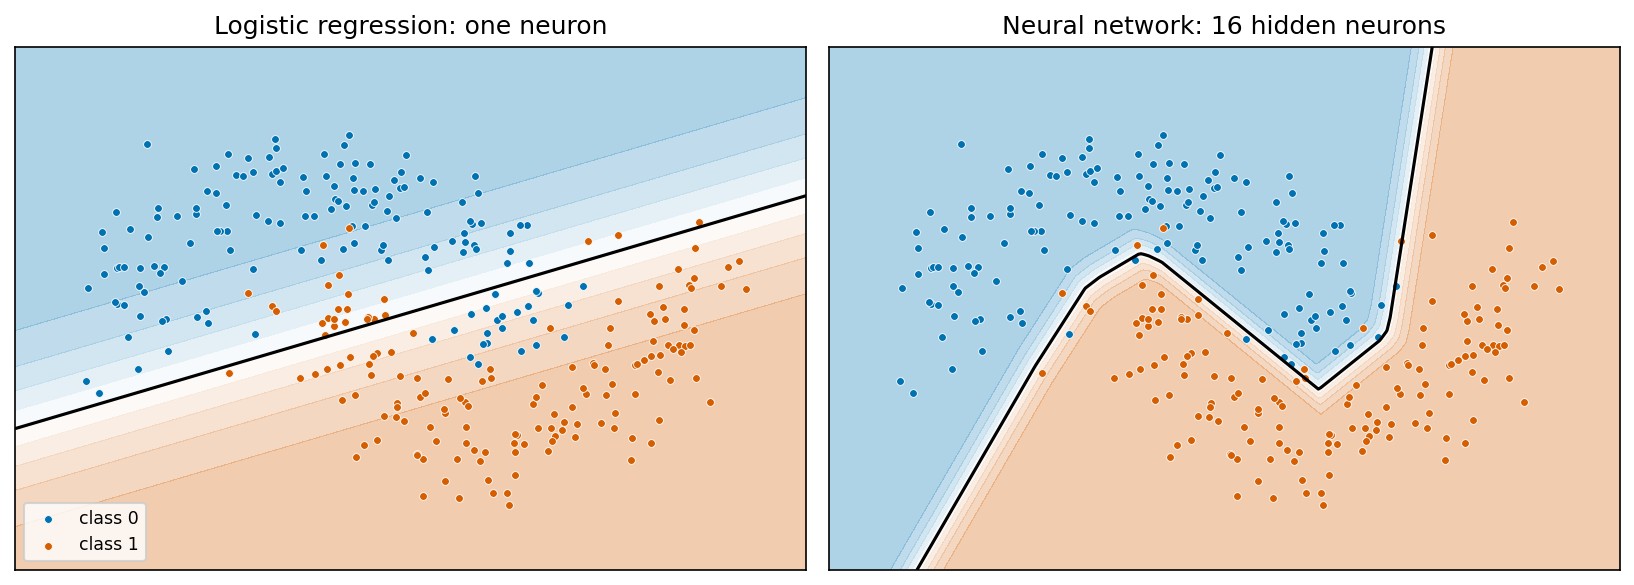

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=150)
plot_boundary(logreg, axes[0], 'Logistic regression: one neuron')
plot_boundary(mlp, axes[1], 'Neural network: 16 hidden neurons')

axes[0].legend(loc='lower left', fontsize='small')

plt.tight_layout()
plt.show()

The data and the training points haven't changed, but now the boundary bends around the crescents. Let's watch how it got there.

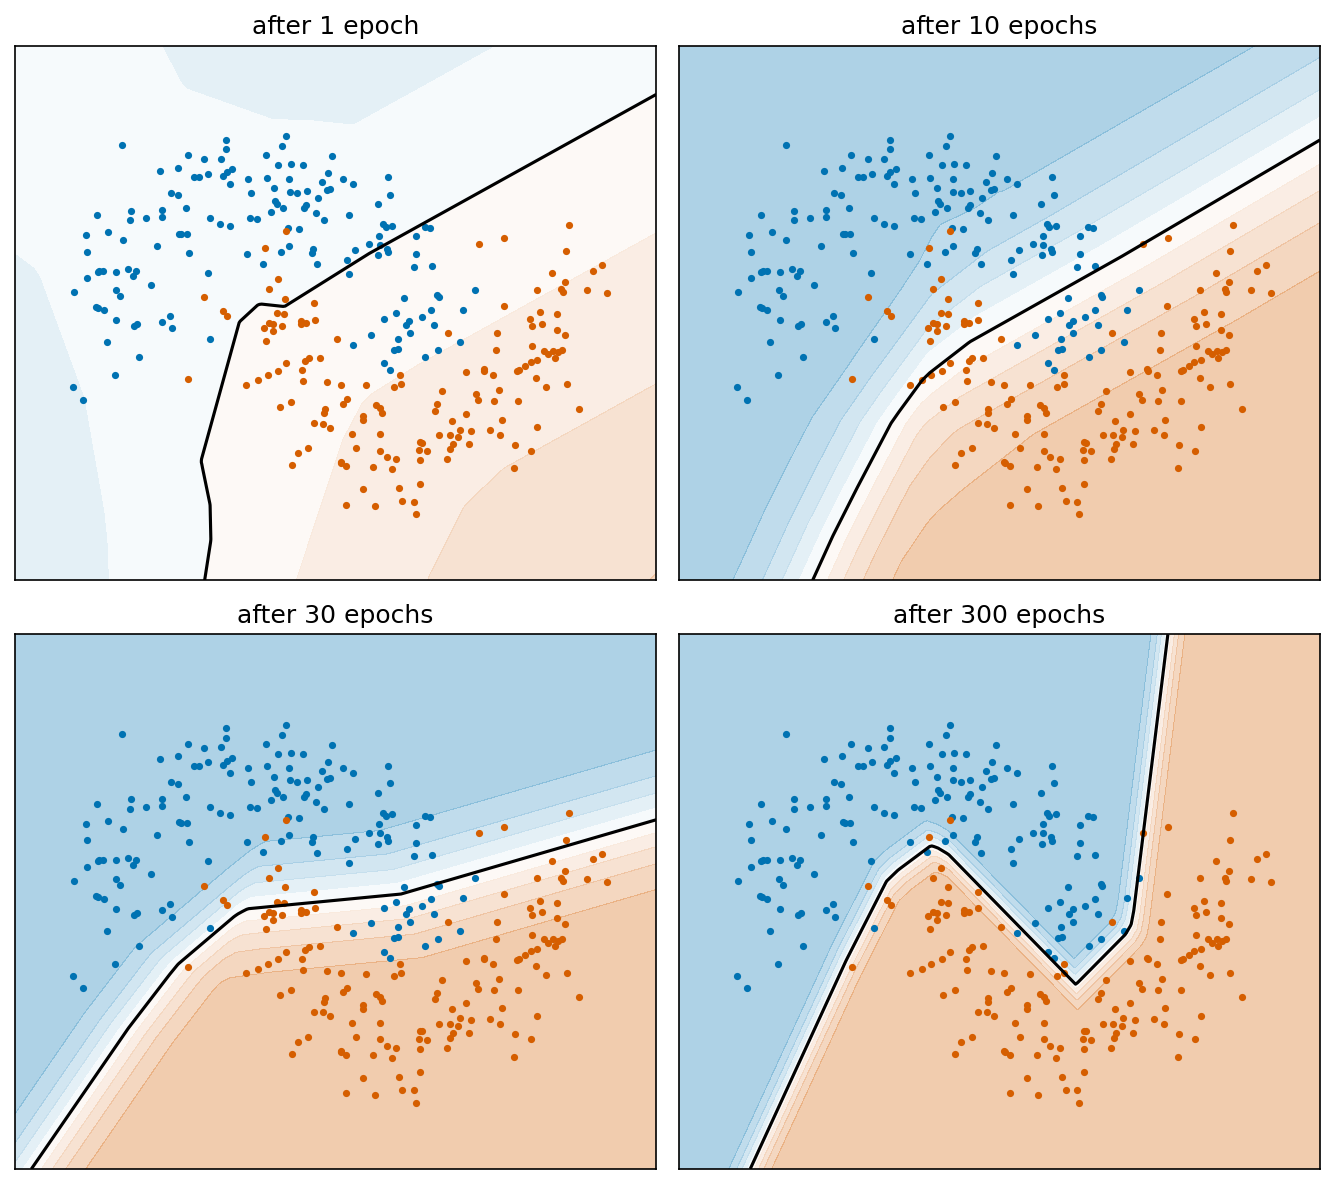

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8), dpi=150)

for ax, (epoch, model) in zip(axes.flat, snapshots.items()):
    plot_boundary(model, ax, f'after {epoch} epoch' + ('s' if epoch > 1 else ''), points=False)

    for c in [0, 1]:
        ax.scatter(*X_train[y_train == c].T, s=6, color=TWO[c])

plt.tight_layout()
plt.show()

After one epoch the weights are still close to their random starting values, and the boundary cuts right through the blue crescent and clips the tip of the orange one. Every step nudges the weights a little bit downhill for the batch of points it just looked at, and the boundary slides and bends until it fits. The learning rate, which we set with `learning_rate_init=0.03` above, sets how big each nudge is. We also saved the training loss after every epoch.

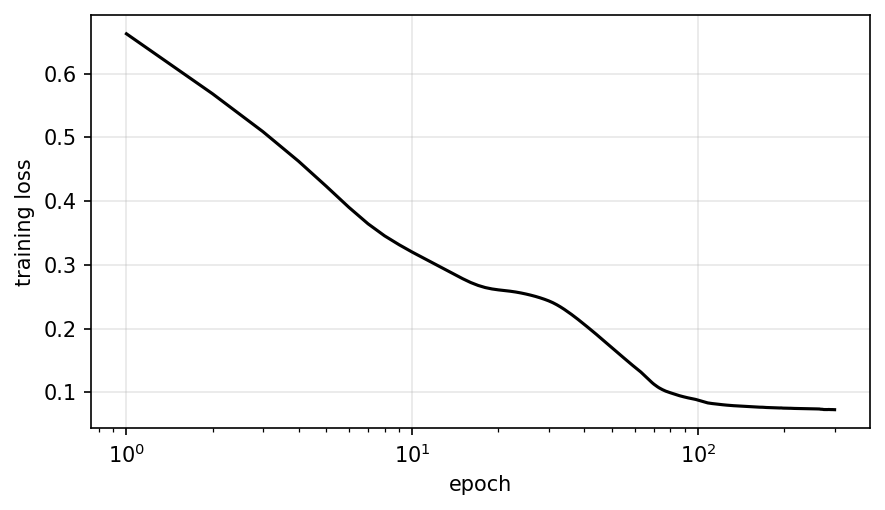

In [26]:
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=150)

ax.plot(range(1, len(losses) + 1), losses, color='k', lw=1.5)
ax.set_xscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('training loss')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Almost all of the drop happens in the first 100 epochs, and after that it barely moves. It doesn't go down at every epoch, though. Each step only looks at one batch, so the loss on all of the training points sometimes goes up a little from one epoch to the next. (The epoch axis is on a log scale, so epochs 1 to 10 get as much room as epochs 10 to 100. Otherwise the first few epochs, where the boundary changes the most, would be squeezed against the left edge.)

### What is each hidden neuron doing?

Each hidden neuron is a little logistic regression with a ReLU instead of a sigmoid, so it has its own line. Below, each panel but the last is one hidden neuron. The dashed line is where its weighted sum crosses zero. On one side the ReLU outputs 0 (white), and on the other side the output grows the farther you go (darker). Each panel has its own shading scale, so compare which side is dark, not how dark it gets. The panel title shows the weight that the output neuron gives it: a positive weight pushes toward class 1 (orange), and a negative weight pushes toward class 0 (blue). We've sorted the panels from the most negative weight to the most positive, and left out the neurons that output 0 for every training point (more on those in a second). The last panel adds them all up.

First we pull the weights out of the trained network and compute every hidden neuron's output at every point of our grid.

In [27]:
W_in, W_out = mlp.coefs_         # W_in is 2 x 16 (inputs -> hidden), W_out is 16 x 1 (hidden -> output)
b_in, b_out = mlp.intercepts_

pre = grid @ W_in + b_in         # each hidden neuron's weighted sum, at every grid point
hidden = relu(pre)               # ... after the ReLU
never_on = (X_train @ W_in + b_in <= 0).all(axis=0)   # neurons that output 0 for every training point
live = [j for j in np.argsort(W_out[:, 0]) if not never_on[j]]   # the others, sorted by output weight
total = hidden @ W_out[:, 0] + b_out[0]   # what the output neuron adds up, at every grid point

print(f'{never_on.sum()} of the 16 hidden neurons output 0 for every training point, so they are left out')
print('Adding up the hidden neurons matches the network\'s own answer:', np.allclose(sigmoid(total), mlp.predict_proba(grid)[:, 1]))


def dashed_line(ax, j, color='k', lw=1):
    # where hidden neuron j's weighted sum crosses zero (if that happens inside the plot)
    if pre[:, j].min() < 0 < pre[:, j].max():
        ax.contour(xx, yy, pre[:, j].reshape(xx.shape), levels=[0], colors=color, linestyles='--', linewidths=lw)

5 of the 16 hidden neurons output 0 for every training point, so they are left out
Adding up the hidden neurons matches the network's own answer: True


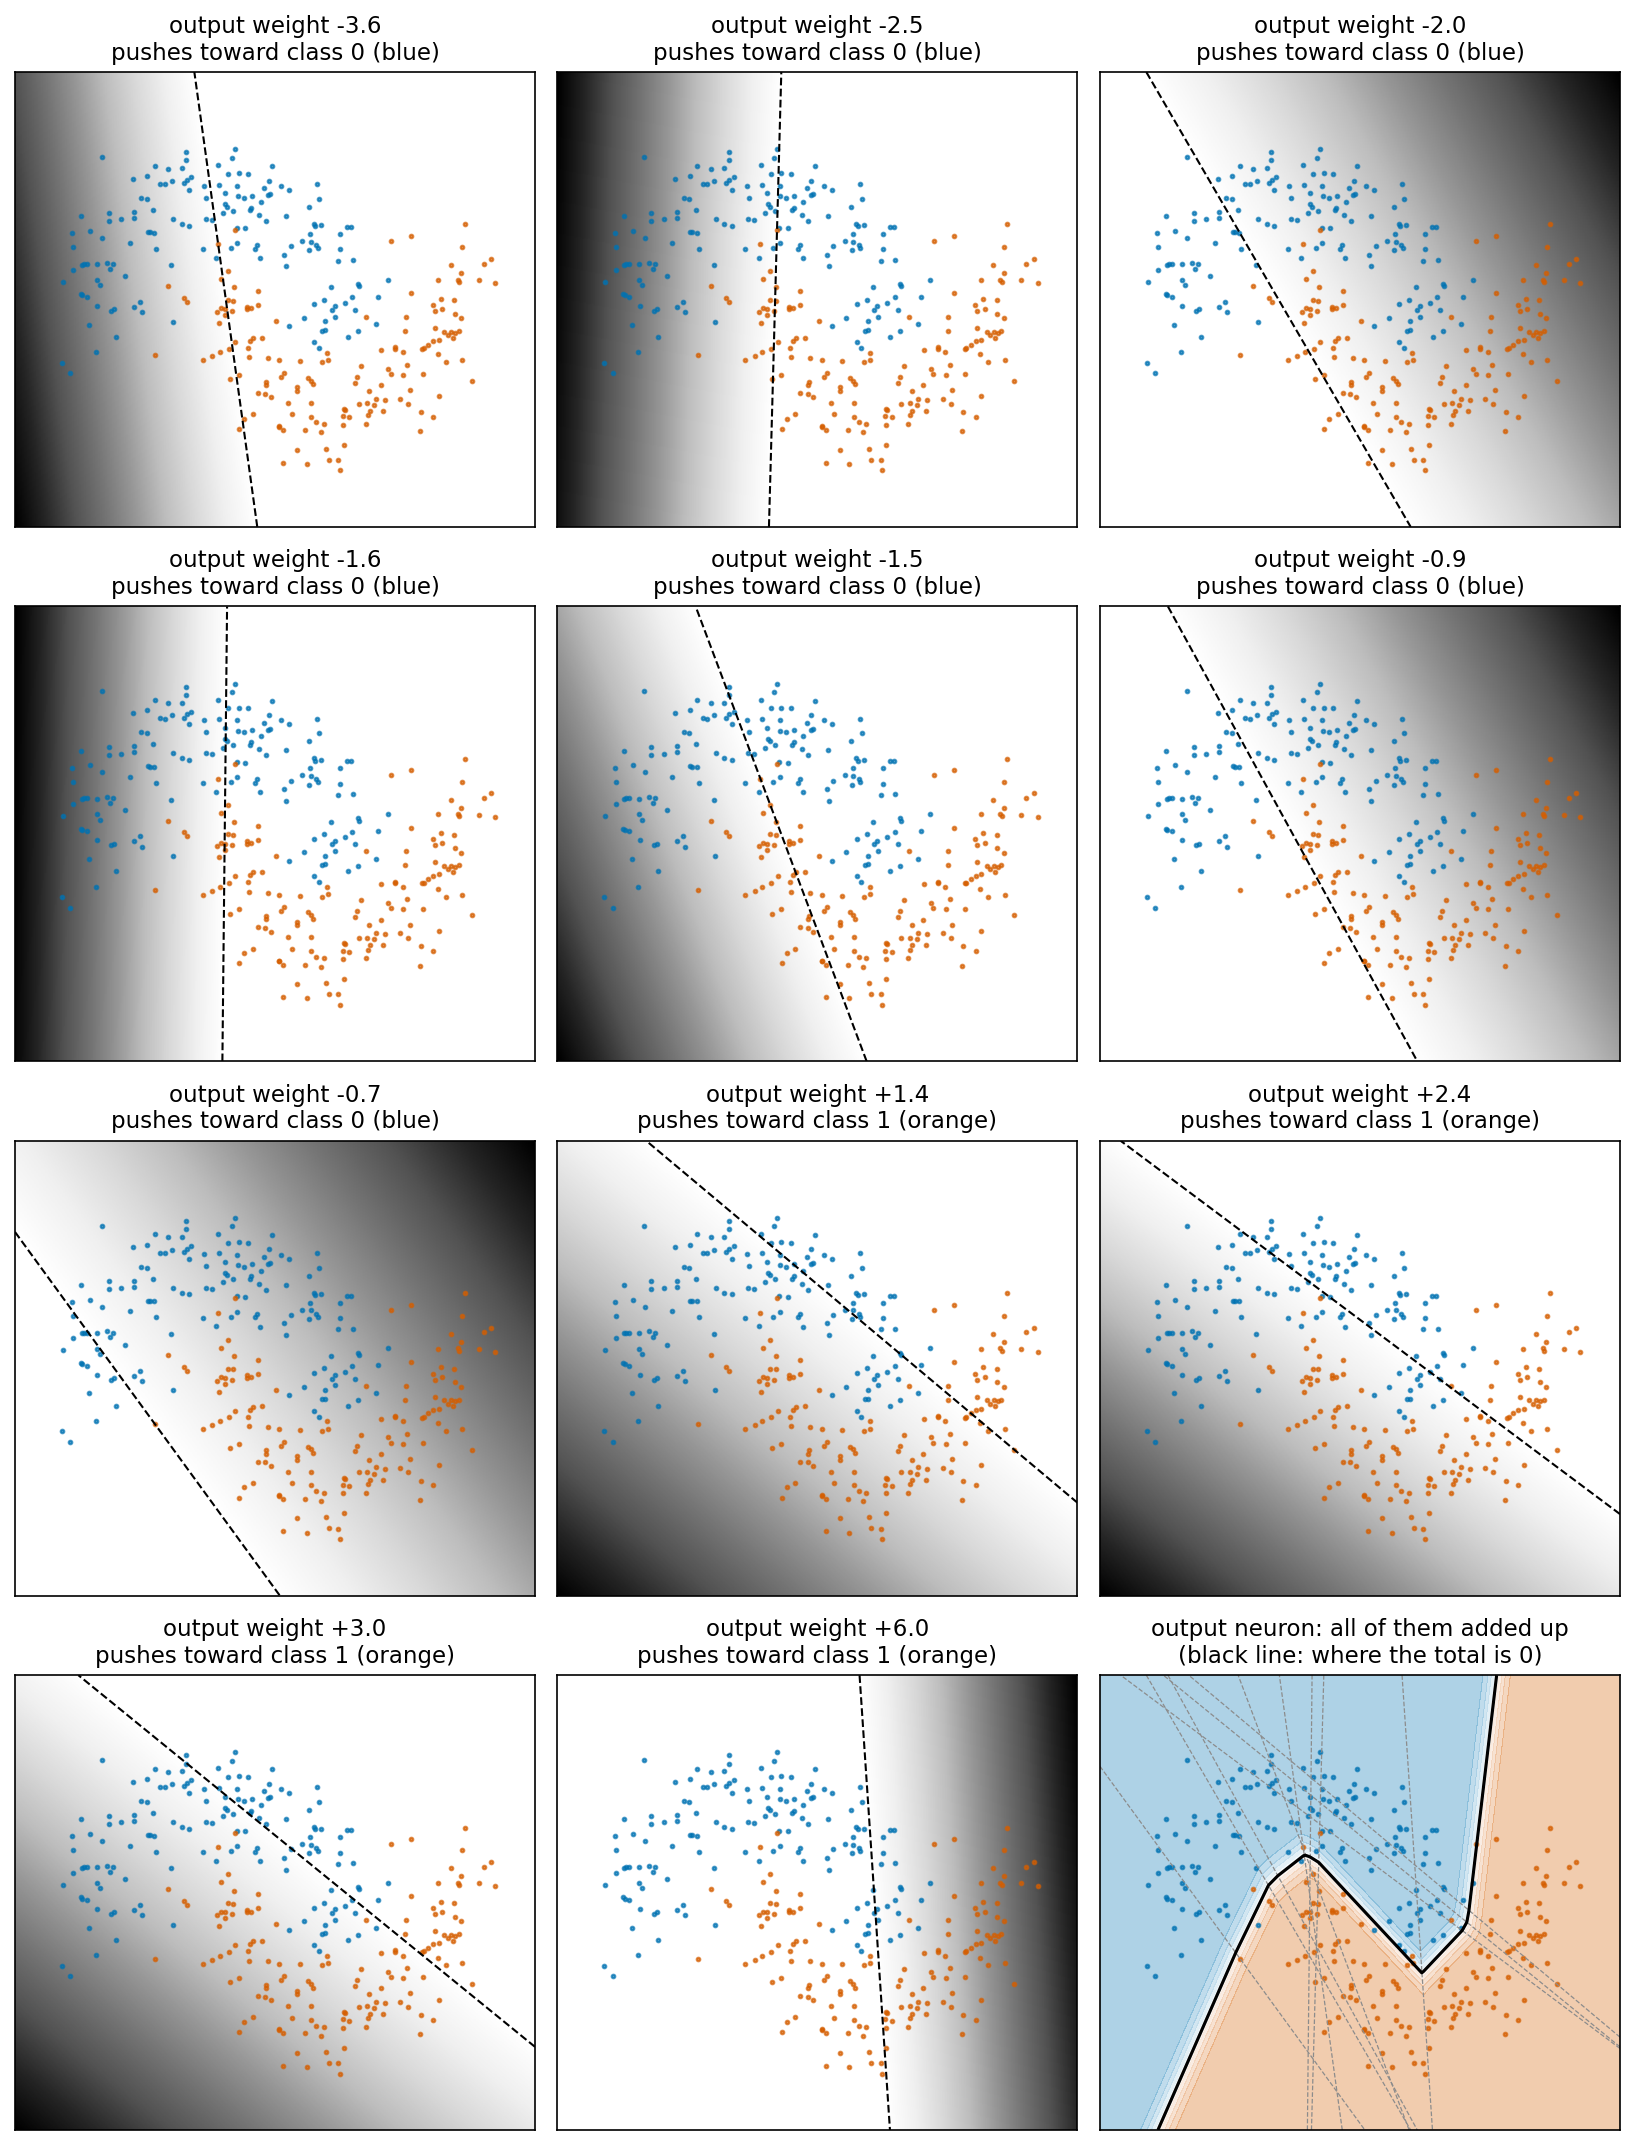

In [28]:
n_panels = len(live) + 1

fig, axes = plt.subplots(int(np.ceil(n_panels / 3)), 3, figsize=(11, 3.6 * np.ceil(n_panels / 3)), dpi=150)

for ax, j in zip(axes.flat, live):
    ax.imshow(hidden[:, j].reshape(xx.shape), origin='lower', cmap='Greys', aspect='auto',
              extent=[xx.min(), xx.max(), yy.min(), yy.max()])
    dashed_line(ax, j)
    weight = round(W_out[j, 0], 1) + 0.0     # (+ 0.0 turns -0.0 into 0.0)

    ax.set_title(f'output weight {weight:+.1f}\npushes toward ' + ('class 1 (orange)' if weight > 0 else 'class 0 (blue)'),
                 fontsize=11)

ax = axes.flat[len(live)]   # the last panel: weight times picture, added up, plus the bias
ax.contourf(xx, yy, sigmoid(total).reshape(xx.shape), levels=np.linspace(0, 1, 11), cmap=shade, alpha=0.35)

for j in live:
    dashed_line(ax, j, color='0.55', lw=0.6)

ax.contour(xx, yy, total.reshape(xx.shape), levels=[0], colors='k', linewidths=1.5)
ax.set_title('output neuron: all of them added up\n(black line: where the total is 0)', fontsize=11)

for ax in axes.flat[:n_panels]:
    for c in [0, 1]:
        ax.scatter(*X_train[y_train == c].T, s=3, color=TWO[c], alpha=0.7)
    ax.set_xticks([])
    ax.set_yticks([])

for ax in axes.flat[n_panels:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

The output neuron multiplies each of these pictures by its weight, adds them up along with its bias, and puts the total through a sigmoid. That's the last panel. Its black line is where the total crosses zero, and it's the same boundary the trained network drew next to logistic regression's, a few figures up. Each picture is zero on one side of its line and a ramp on the other, so their weighted sum is a surface made of flat pieces, with creases along the dashed lines. That's the two-input version of the bends we built by hand earlier, and it's why the boundary is made of straight segments that bend where it crosses a dashed line.

Five of the 16 hidden neurons aren't in the picture. They output 0 for every training point, so they add nothing to the answer for any of them. These are the stuck neurons from the activation function section: their weighted sum is zero or negative for every training point, where the ReLU's slope is 0, so the data gives gradient descent no reason to move their weights. (Their weights can still drift a little, because scikit-learn adds a small penalty to the loss that pulls every weight toward 0, and because Adam's steps carry some memory of earlier slopes.) People call these **dead neurons**, and they're common with ReLU. Having more neurons than we strictly need means losing a few doesn't hurt.

Notice that we never told the network which lines to draw; it found them by nudging the weights to make the loss smaller. On Wednesday we built features like common neighbors by hand, and here the hidden neurons are features the model built for itself.

What can go wrong? Training starts from random weights, and different starting points end up in different places. Let's train our network ten times, from ten different random starting points (the seed also sets the order the training points go into batches), and do the same for a smaller network with only 8 hidden neurons.

In [29]:
for size in [16, 8]:
    accuracies = []
    for seed in range(10):
        net = MLPClassifier(hidden_layer_sizes=(size,), activation='relu', learning_rate_init=0.03, random_state=seed)

        for epoch in range(300):
            net.partial_fit(X_train, y_train, classes=[0, 1])
        accuracies.append(net.score(X_test, y_test))

    print(f'{size} hidden neurons, test accuracy from ten starting points:', np.round(accuracies, 2))

print(f'logistic regression, for comparison: {logreg.score(X_test, y_test):.2f}')

16 hidden neurons, test accuracy from ten starting points: [0.97 0.97 0.95 0.96 0.96 0.95 0.96 0.96 0.98 0.97]


8 hidden neurons, test accuracy from ten starting points: [0.83 0.96 0.83 0.98 0.83 0.98 0.95 0.95 0.95 0.95]
logistic regression, for comparison: 0.81


With 16 hidden neurons, all ten starting points end up between 0.95 and 0.98. With 8, three of the ten get stuck at 0.83, barely better than the logistic regression. Test accuracy alone can't tell us why. One common reason is that a run lands on a flat stretch of the loss, where small nudges barely help even though much better weights exist. People call a flat stretch like this a **plateau**, and if no small nudge helps at all, the spot is called a **local minimum**. Training for longer sometimes gets a run off a plateau: when we tried training these three runs for 5,000 epochs (that takes a while, so it isn't in this notebook), two of them got to 0.94 and 0.96, and the third only got to 0.85. In practice there are two common fixes: use more neurons than seem necessary, like we did, or train from several starting points and keep whichever one does best on validation data. (We printed test accuracy here only to see the spread. To actually pick one of the runs, we'd use a validation set, like on Wednesday, and save the test set for the very end.)

__________
## Part 2: A little neural network on every node

From here on, "network" means the graph, with its nodes and links, and we'll say "neural network" whenever we mean the model. On Wednesday, every example was a *pair* of nodes, and we had to build its features by hand (common neighbors, Jaccard, and so on). Today every example is a single node, and the question is about the node itself, like which topic a paper is on.

In a lot of real networks, each node comes with its own data, separate from its links. In a social network, each person has an age, a school and a list of interests. In a citation network, each paper has its words. We turn this data into numbers and call it the node's **features**, a vector $x_i$ for node $i$. (In Part 1, $x_1$ and $x_2$ were the two numbers describing one example. From here on, the subscript names a node, so $x_2$ is node 2's whole feature vector.) The thing we want to predict about a node is its **label**. In practice we know every node's features and links, and only some nodes' labels.

Notice that "same side" in Part 1 was already built from a node feature. Which side a blog is on comes from the blog itself, not from its links. If we wanted to predict a blog's side instead, the side would be the label.

In Part 3, a node is a paper, its features say which words appear in it, and its label is its topic. We could feed each paper's $x_i$ into a neural network like the one in Part 1 and ignore the links entirely. But linked nodes tend to be alike (homophily). Friends often went to the same school, and papers mostly cite papers on similar topics, so a paper's neighbors probably know something useful about it. If a paper's own words are vague, the papers around it are a strong hint about what it's about, and a Part 1 neural network can't use that hint, because it only ever looks at one paper at a time. We want a model that uses both a node's own features and its neighbors' features.

Every node does the following, all at the same time:
1. collects the feature vectors of its neighbors,
2. averages them into one vector,
3. glues its own vector and that average end to end, and feeds the result into a little neural network (one layer, like the hidden layer in Part 1),
4. and the output becomes the node's new vector.

We keep the node's own vector apart from the neighbor average, so the little network can learn to treat a node's own features differently from its neighbors' features.

Every node uses **the same** little network, with the same weights. A model that works this way is a **graph neural network** (GNN). Bottom line: GNNs learn weight matrices, just like regular neural networks. The weights transform each node's vector, and every layer gathers up information from a node's neighborhood to make that node's next vector.

Tiny graph time. Six nodes: two triangles joined by one link, like two small groups with one link between them. Node 2 has two neighbors in its own triangle and one in the other, so its neighbor average mixes the two groups. Every node has a feature vector with two numbers in it, written next to the node. Think of each node as a paper, and its two numbers as how many times it uses two words, say "neuron" and "graph". The numbers are made up and small, so that we can check the arithmetic by hand. Let's follow node 2 through one update.

In [30]:
G_tiny = nx.Graph([(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)])
X_tiny = np.array([[2.0, 0.0],    # node 0
                   [1.0, 1.0],    # node 1
                   [0.0, 2.0],    # node 2
                   [3.0, 2.0],    # node 3
                   [1.0, 0.0],    # node 4
                   [0.0, 1.0]])   # node 5

pos_tiny = {0: (-2, 0.8), 1: (-2, -0.8), 2: (-0.7, 0), 3: (0.7, 0), 4: (2, 0.8), 5: (2, -0.8)}
focus, focus_neighbors = 2, sorted(G_tiny.neighbors(2))
colors = ['k' if u == focus else '0.55' if u in focus_neighbors else '0.88' for u in G_tiny]

print('node 2 is linked to nodes', focus_neighbors)

node 2 is linked to nodes [0, 1, 3]


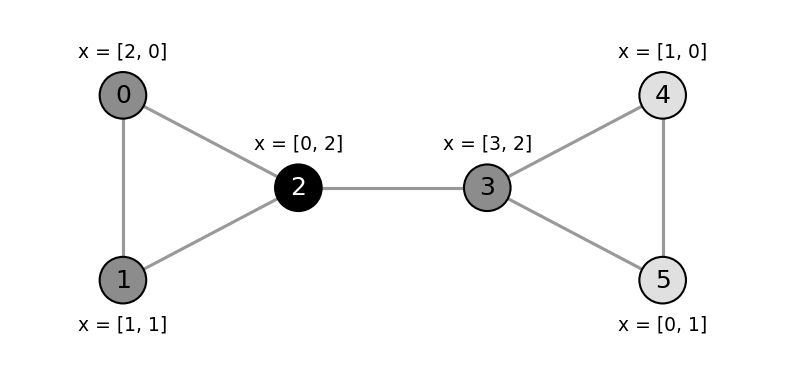

In [31]:
fig, ax = plt.subplots(1, 1, figsize=(6.5, 3), dpi=150)
nx.draw_networkx_edges(G_tiny, pos_tiny, ax=ax, width=1.5, edge_color='0.6')
nx.draw_networkx_nodes(G_tiny, pos_tiny, ax=ax, node_color=colors, node_size=500, edgecolors='k')
nx.draw_networkx_labels(G_tiny, pos_tiny, ax=ax, font_color='w', labels={focus: focus})
nx.draw_networkx_labels(G_tiny, pos_tiny, ax=ax, labels={u: u for u in G_tiny if u != focus})

for u, (px, py) in pos_tiny.items():
    ax.text(px, py + (0.38 if py >= 0 else -0.38), f'x = [{X_tiny[u, 0]:g}, {X_tiny[u, 1]:g}]',
            ha='center', va='center', fontsize=9)

ax.set_xlim(-2.8, 2.8)
ax.set_ylim(-1.5, 1.5)
ax.axis('off')

plt.show()

Node 2 (black) has three neighbors, nodes 0, 1 and 3 (gray). Here's the whole update for node 2 in one picture, with the numbers filled in. The squares are numbers, colored like they will be in the next few figures (red for positive, blue for negative, white for 0), and the circles in the middle are the 3 neurons of the little neural network.

![the little neural network on node 2](./images/gnn_node.png)

Reading left to right: the three neighbors' vectors get averaged, node 2's own vector gets glued on in front of that average, and those 4 numbers go into 3 neurons. Each neuron takes a weighted sum and applies a ReLU, and the 3 outputs are node 2's new vector. We picked 3 neurons, so the new vector has 3 numbers. The label under the neurons, $W_{\text{self}}$ stacked on $W_{\text{neigh}}$, is their weights, which we'll write down in a moment.

Here's the same update for any node $i$ with at least one neighbor, written as an equation:

$$h_i = \text{ReLU}\Big(x_i \, W_{\text{self}} + \Big(\frac{1}{k_i}\sum_{j \in N_i} x_j\Big) W_{\text{neigh}}\Big)$$

- $N_i$ is the set of $i$'s neighbors and $k_i$ is its degree, so the part in the inner parentheses is the average of the neighbors' feature vectors.
- $W_{\text{self}}$ and $W_{\text{neigh}}$ are weight matrices with 2 rows (one per input number) and 3 columns (one per output number). We treat $x_i$ as a row vector, so $x_i W_{\text{self}}$ has 3 numbers in it. Column $j$ of $W_{\text{self}}$ holds output neuron $j$'s weights for the node's own 2 numbers, and column $j$ of $W_{\text{neigh}}$ holds its weights for the 2 numbers in the neighbor average, so each output number comes from one neuron like the ones in Part 1, taking a weighted sum of 4 inputs.
- $h_i$ is node $i$'s new vector, with 3 numbers.
- To keep the arithmetic small, we leave out the biases.

Normally the weights would be learned. For now we'll just pick some, and follow node 2 step by step.

In [32]:
W_self = np.array([[1.0, 0.0, -1.0],
                   [0.0, 1.0,  1.0]])
W_neigh = np.array([[0.5, -1.0, 0.0],
                    [0.0, -0.5, 1.0]])

focus_avg = X_tiny[focus_neighbors].mean(axis=0)      # step 2: average the neighbors' vectors
own_part = X_tiny[focus] @ W_self                     # node 2's own vector, through W_self
neighbor_part = focus_avg @ W_neigh                   # the neighbor average, through W_neigh
h_2 = relu(own_part + neighbor_part)                  # add them up, then the ReLU

print('average of the neighbors:', focus_avg)
print('own part:                ', own_part)
print('neighbor part:           ', neighbor_part)
print('added up:                ', own_part + neighbor_part)
print('after the ReLU, h_2 =    ', h_2)

average of the neighbors: [2. 1.]
own part:                 [0. 2. 2.]
neighbor part:            [ 1.  -2.5  1. ]
added up:                 [ 1.  -0.5  3. ]
after the ReLU, h_2 =     [1. 0. 3.]


Here are the same steps as colored boxes, one row per step:

In [33]:
# one row of boxes per step: a label and its numbers (None leaves a small gap)
steps = [(f'neighbor {j}: $x_{j}$', X_tiny[j]) for j in focus_neighbors] + [
         ('average of the neighbors', focus_avg),
         (None, None),
         ('node 2 itself: $x_2$', X_tiny[focus]),
         (None, None),
         (r'own part: $x_2 W_{\mathrm{self}}$', own_part),
         (r'neighbor part: average $\times W_{\mathrm{neigh}}$', neighbor_part),
         ('add them up', own_part + neighbor_part),
         ('ReLU: the new vector $h_2$', h_2)]

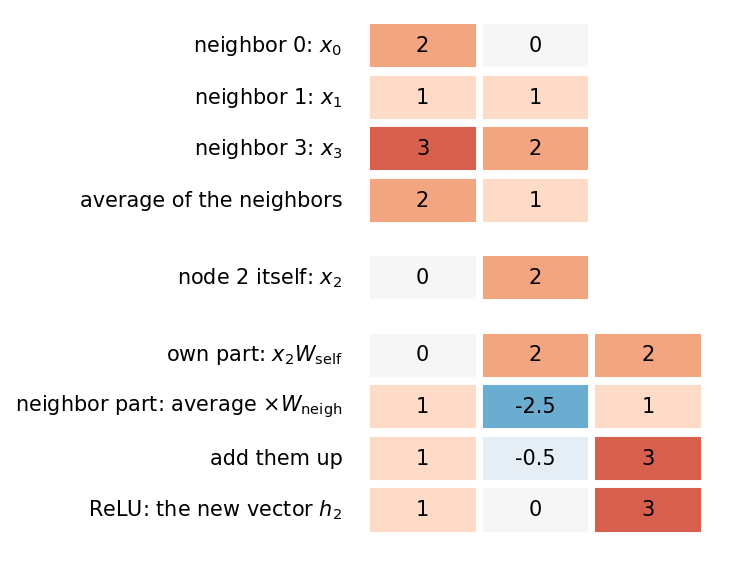

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(3.4, 4.6), dpi=150)

row = 0
for label, values in steps:
    if label is None:        # a small gap between groups of rows
        row += 0.5
        continue

    for k, v in enumerate(values):
        ax.add_patch(plt.Rectangle((k, -row), 0.92, 0.8, color=plt.cm.RdBu_r(0.5 + v / 10)))
        ax.text(k + 0.46, -row + 0.4, f'{v:g}', ha='center', va='center')

    ax.text(-0.25, -row + 0.4, label, ha='right', va='center')
    row += 1

ax.set_xlim(-0.4, 3.1)
ax.set_ylim(-row + 0.7, 1)
ax.axis('off')

plt.show()

Red boxes are positive numbers, blue boxes are negative, and the darker the box, the farther the number is from 0. Reading from the top: the three neighbors' vectors average to $[2, 1]$. Node 2's own vector goes through $W_{\text{self}}$. Each number in $x_2$ multiplies one row of $W_{\text{self}}$, so $[0, 2]\,W_{\text{self}} = 0 \cdot [1, 0, -1] + 2 \cdot [0, 1, 1] = [0, 2, 2]$. The neighbor average goes through $W_{\text{neigh}}$ the same way, $[2, 1]\,W_{\text{neigh}} = 2 \cdot [0.5, -1, 0] + 1 \cdot [0, -0.5, 1] = [1, -2.5, 1]$, and we add the two. The middle number came out negative ($-0.5$), so the ReLU turns it into 0, and node 2's new vector is $h_2 = [1, 0, 3]$.

We can also do the same calculation the way the diagram of the little neural network draws it. Glue node 2's own vector and the neighbor average end to end into one row of 4 numbers, and stack $W_{\text{self}}$ on top of $W_{\text{neigh}}$ to make one $4 \times 3$ weight matrix:

In [35]:
glued = np.concatenate([X_tiny[focus], focus_avg])   # node 2's own vector, then the neighbor average: 4 numbers
W_stacked = np.vstack([W_self, W_neigh])            # W_self on top of W_neigh: a 4 x 3 matrix

print('glued input:', glued)
print('one layer, 4 inputs -> 3 neurons, before the ReLU:', glued @ W_stacked)
print('one layer, 4 inputs -> 3 neurons, after the ReLU: ', relu(glued @ W_stacked))

glued input: [0. 2. 2. 1.]
one layer, 4 inputs -> 3 neurons, before the ReLU: [ 1.  -0.5  3. ]
one layer, 4 inputs -> 3 neurons, after the ReLU:  [1. 0. 3.]


Multiplying the glued row $[0, 2, 2, 1]$ by the stacked matrix gives the same $[1, -0.5, 3]$ before the ReLU. The first two inputs only ever meet the first two rows of the stacked matrix, which are $W_{\text{self}}$, and the last two only meet $W_{\text{neigh}}$, so it's the same arithmetic. That's exactly one layer of a neural network from Part 1, with 4 inputs and 3 neurons.

And here's a whole GNN layer in one picture. Every node does what node 2 just did, at the same time, with its own copy of the same little neural network (the same weights). Each row is one node:

![the same little neural network on every node](./images/gnn_every_node.png)

Node 2's row (shaded) is the one we just worked out, and every other row works the same way: list the node's neighbors, average their vectors, glue the node's own vector in front, and run the result through the same little neural network. Notice that nodes 4 and 5 sit in identical spots in the graph, but they start with different vectors, so they end up with different new vectors. Node 3, which links the two triangles, has the biggest vector to start with, and it ends up with the biggest first number (3.17) and the only middle number that survives the ReLU. The new vectors depend on both the features and the links.

#### All the nodes at once

Doing this one node at a time with a loop is slow for big graphs. Let's write the same thing for every node at once with matrices. Stack the feature vectors as the rows of a matrix $X$, one row per node. In the adjacency matrix, $A_{ij} = 1$ if $i$ and $j$ are linked, so row $i$ of $AX$ is the *sum* of $i$'s neighbors' vectors. For node 2, row 2 of $A$ is $[1, 1, 0, 1, 0, 0]$, so row 2 of $AX$ is $x_0 + x_1 + x_3 = [6, 3]$. Dividing row $i$ by $k_i$ turns the sum into an average, and for node 2 that's $[6, 3] / 3 = [2, 1]$, the average from before. In matrix language, that's multiplying by $D^{-1}$, where $D$ is the diagonal matrix with the degrees on the diagonal. (You might recognize $D^{-1}A$ from Class 12: it's the transition matrix of a random walk.) So the update for every node is

$$H = \text{ReLU}\big(X W_{\text{self}} + D^{-1} A X W_{\text{neigh}}\big),$$

and row $i$ of $H$ is node $i$'s new vector. Here are the matrices for our tiny graph, with node 2's row outlined:

In [36]:
A_tiny = nx.to_numpy_array(G_tiny, nodelist=range(6))
D_inv = np.diag(1 / A_tiny.sum(axis=1))      # 1 / degree on the diagonal

print('degrees:', A_tiny.sum(axis=1))

degrees: [2. 2. 3. 3. 2. 2.]


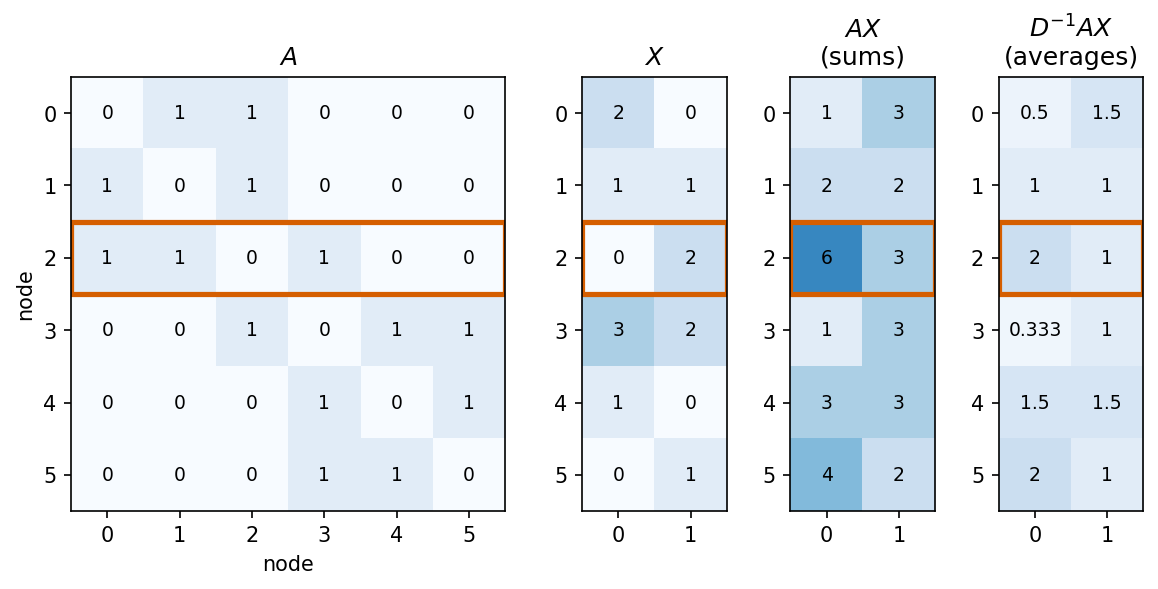

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(8, 3.8), dpi=150, gridspec_kw={'width_ratios': [6, 2, 2, 2]})

for ax, values, title in [(axes[0], A_tiny, '$A$'), (axes[1], X_tiny, '$X$'),
                          (axes[2], A_tiny @ X_tiny, '$AX$\n(sums)'), (axes[3], D_inv @ A_tiny @ X_tiny, '$D^{-1}AX$\n(averages)')]:
    ax.imshow(values, cmap='Blues', vmin=0, vmax=9)

    for (r, c), v in np.ndenumerate(values):
        ax.text(c, r, f'{v:.3g}', ha='center', va='center', fontsize=9)
    ax.add_patch(plt.Rectangle((-0.5, 1.5), values.shape[1], 1, fill=False, edgecolor=TWO[1], lw=2.5))
    ax.set_xticks(range(values.shape[1]))
    ax.set_yticks(range(6))
    ax.set_title(title)

axes[0].set_ylabel('node')
axes[0].set_xlabel('node')

plt.tight_layout()
plt.show()

Every number in this figure is 0 or more, so here darker blue just means bigger. Row 2 of $A$ has 1s in columns 0, 1 and 3, so row 2 of $AX$ adds up rows 0, 1 and 3 of $X$ to get $[6, 3]$, and dividing by node 2's degree turns that sum into the average $[2, 1]$. $A$ multiplies from the left and mixes *nodes*: each row of $AX$ combines several nodes' rows. The weight matrices multiply from the right and mix the numbers *within* each node's vector. Sanity check: the loop and the matrix version should agree.

In [38]:
H_matrix = relu(X_tiny @ W_self + D_inv @ A_tiny @ X_tiny @ W_neigh)

H_loop = np.zeros((6, 3))
for node in G_tiny.nodes():
    avg = X_tiny[list(G_tiny.neighbors(node))].mean(axis=0)
    H_loop[node] = relu(X_tiny[node] @ W_self + avg @ W_neigh)

print(H_matrix)
print('Loop and matrix version agree:', np.allclose(H_loop, H_matrix))

[[2.25       0.         0.        ]
 [1.5        0.         1.        ]
 [1.         0.         3.        ]
 [3.16666667 1.16666667 0.        ]
 [1.75       0.         0.5       ]
 [1.         0.         2.        ]]
Loop and matrix version agree: True


Row 2 of the printout is $[1, 0, 3]$, the $h_2$ we got by hand. Your turn! Work out $h_4$ for node 4 by hand, and check it against row 4.

### Why average the neighbors, instead of gluing them all together?

Nodes in networks have neighborhoods of very different sizes, but we want to represent all nodes with vectors of the same size. In Part 1, the network had a fixed number of inputs. If we glued the neighbors' vectors end to end, node 2's three neighbors would hand the network 6 numbers and node 4's two neighbors would hand it 4, on top of the node's own 2. And a hub with a hundred neighbors would hand it 200.

Neighbors also don't come in any natural order. Gluing them together in a different order gives a different vector, and the model shouldn't care which neighbor we happened to list first. Functions that give the same output no matter how you order the inputs are called **permutation-invariant**. So if $f(x, y, z) = f(y, z, x)$, and so on for all orderings of $x, y, z$, then $f$ is permutation-invariant. Operations like the mean, maximum, sum, and minimum are all permutation-invariant. We can put in as many nodes' attributes as we'd like, and our output will keep the same size. Here are node 2's three neighbors, listed in two different orders:

In [39]:
order_1 = [0, 1, 3]
order_2 = [3, 0, 1]

print('glued together, order 1:', X_tiny[order_1].ravel())
print('glued together, order 2:', X_tiny[order_2].ravel())
print('averaged, order 1:      ', X_tiny[order_1].mean(axis=0))
print('averaged, order 2:      ', X_tiny[order_2].mean(axis=0))

glued together, order 1: [2. 0. 1. 1. 3. 2.]
glued together, order 2: [3. 2. 2. 0. 1. 1.]
averaged, order 1:       [2. 1.]
averaged, order 2:       [2. 1.]


The same three neighbors give two different glued vectors, so a neural network fed the glued version would treat them as two different situations. The average is $[2, 1]$ both times.

### Why the same weights on every node?

$W_{\text{self}}$ and $W_{\text{neigh}}$ have 12 numbers between them, and that stays true whether the graph has 6 nodes or 6 million. Every node gets the same treatment, so the model can also be used on a node it has never seen, or on a whole new graph. A layer with one weight matrix for the node and one for the average of its neighbors is close to the GraphSAGE layer (Hamilton et al., 2017).

### Stacking layers: how far can a node see?

One layer mixes each node with its neighbors. If we feed the new vectors through a second layer (with its own weights), each node now hears from its neighbors' neighbors, too. After $L$ layers, a node's vector can depend on anything within $L$ hops of it, and on nothing further away. People call this the node's **receptive field**.

Let's watch it grow on a grid graph, where each node is linked to the nodes above, below, left and right of it, like pixels in an image. We give every node 8 random features, run three layers with random weights, then change the features of only the center node and see whose outputs change.

In [40]:
G_grid = nx.grid_2d_graph(9, 9)
grid_nodes = list(G_grid.nodes())
A_grid = nx.to_numpy_array(G_grid, nodelist=grid_nodes)
D_inv_grid = np.diag(1 / A_grid.sum(axis=1))

rng = np.random.default_rng(SEED)
X_grid = rng.normal(size=(len(grid_nodes), 8))
layer_weights = [(rng.normal(size=(8, 8)), rng.normal(size=(8, 8))) for layer in range(3)]


def run_layers(X):
    # three of our Part 2 layers in a row; returns every layer's output
    outputs, H = [], X
    for W_s, W_n in layer_weights:
        H = relu(H @ W_s + D_inv_grid @ A_grid @ H @ W_n)
        outputs.append(H)

    return outputs


center = grid_nodes.index((4, 4))
X_nudged = X_grid.copy()
X_nudged[center] += 1.0          # change only the center node's features
before, after = run_layers(X_grid), run_layers(X_nudged)

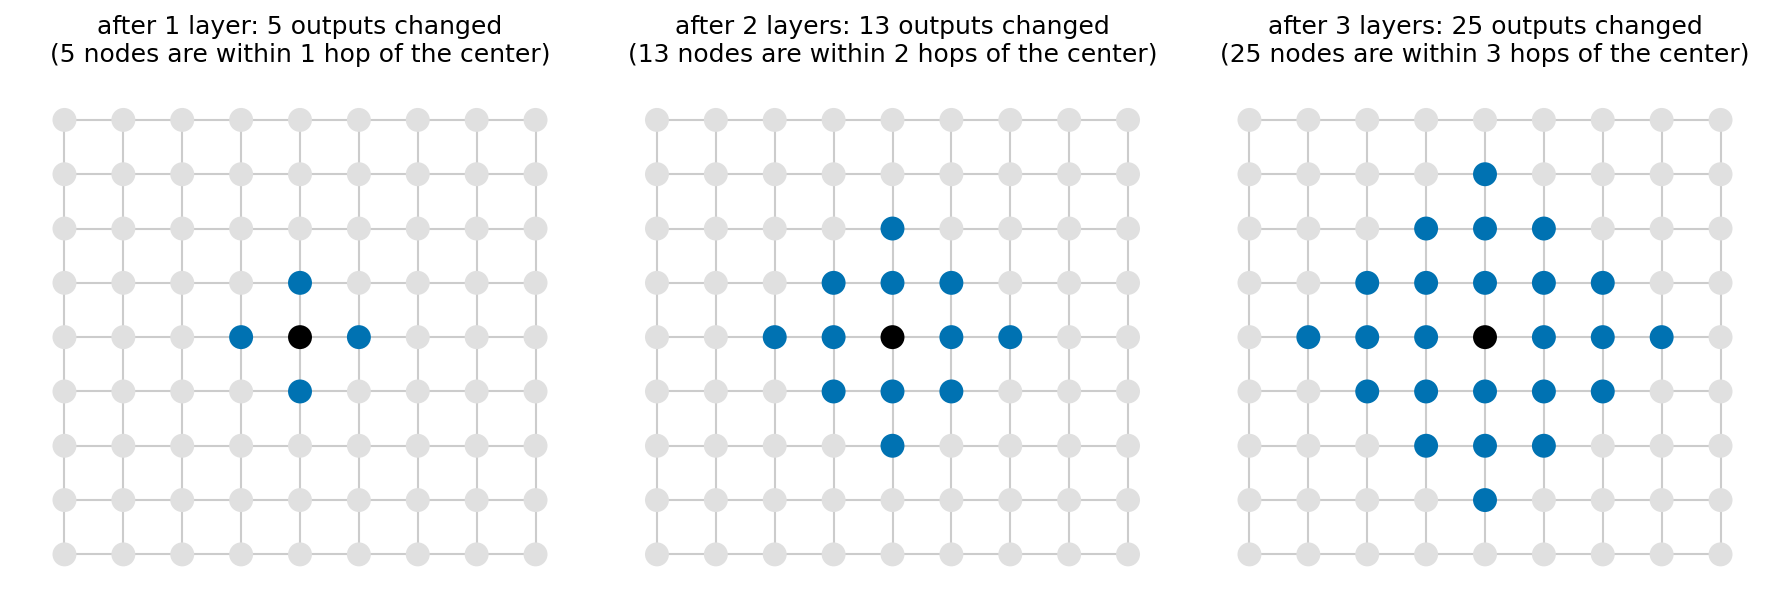

In [41]:
pos_grid = {(r, c): (c, -r) for r, c in grid_nodes}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), dpi=150)

for layer, ax in enumerate(axes):
    changed = np.abs(after[layer] - before[layer]).max(axis=1) > 1e-9
    colors = ['k' if u == center else TWO[0] if changed[u] else '0.88' for u in range(len(grid_nodes))]
    nx.draw_networkx_edges(G_grid, pos_grid, ax=ax, edge_color='0.8')
    nx.draw_networkx_nodes(G_grid, pos_grid, ax=ax, nodelist=grid_nodes, node_color=colors, node_size=110)
    within = len(nx.single_source_shortest_path_length(G_grid, (4, 4), cutoff=layer + 1))

    ax.set_title(f'after {layer + 1} layer' + ('s' if layer else '') + f': {changed.sum()} outputs changed\n'
                 f'({within} nodes are within {layer + 1} hop' + ('s' if layer else '') + ' of the center)')
    ax.axis('off')

plt.tight_layout()
plt.show()

In each panel, the black node in the middle is the one we changed, and the blue nodes are the ones whose outputs changed. After one layer, only the center and its four neighbors change. After two layers, everything within two hops changes, and after three, everything within three. On a grid, "within $L$ hops" is a diamond. Nothing outside the diamond can ever change, whatever the weights are. Inside the diamond, a node's output can occasionally stay the same anyway, if a ReLU turns the change into 0 somewhere along the way, either at that node or at a node the change has to pass through, but that didn't happen with these weights.

Averaging each pixel with the pixels around it is exactly what an image blur does, and in image processing that kind of operation is called a **convolution**. A graph is like an image whose pixels can have any number of neighbors, in no particular arrangement, and that's the sense in which these layers are called graph convolutions. In neural networks for images, a pixel's neighbors come in a fixed arrangement (above, below, left, right), so an image model can learn a different weight for each direction. A node's neighbors have no "above" or "left", which is why a GNN averages them and uses the same weights for all of them.

Wait a second though... we picked every weight in this part ourselves, by hand for the tiny graph and at random for the grid, so none of these vectors mean anything yet. To make them useful, we train the weights exactly like in Part 1: compare the outputs to the right answers with a loss function, and nudge the weights to make the loss smaller. That's Part 3.

__________
## Part 3: Graph convolutional networks (GCNs)

Material in this section relies heavily on Maxime Labonne's [blog post](https://towardsdatascience.com/graph-convolutional-networks-introduction-to-gnns-24b3f60d6c95) in *Towards Data Science* and Thomas Kipf's [blog post](https://tkipf.github.io/graph-convolutional-networks/) on his GitHub website.

In Part 2, we picked the weights ourselves. Now let's train a GNN on real data, using the best-known kind of GNN, the [GCN](https://arxiv.org/pdf/1609.02907) (Kipf & Welling, 2017).

### Our data: Cora

Cora is a commonly used citation dataset (McCallum et al., 2000; Sen et al., 2008). The name comes from Cora, a search engine for computer science research papers that McCallum and colleagues built in the late 1990s, which sorted papers into topics automatically so people could browse them by subject. The task is to label machine learning publications by subject area based on their words and the links (citations) between publications. Labeling papers by hand means someone has to read them, so in practice we'd like a model to do most of the work.

- 2,708 papers, each labeled with one of seven topics, like Neural Networks, Genetic Algorithms and Reinforcement Learning. The topic is the label we predict.
- Each paper has 1,433 features, one per word in a fixed dictionary: 1 if the word appears in the paper and 0 if it doesn't. These are the node features from Part 2. The dataset doesn't tell us which words they are, only their column numbers.
- Links are citations. We ignore who cited whom and treat each citation as an undirected link.

In [42]:
papers = pd.read_csv('data/cora_papers.tsv', sep='\t')   # paper_id, topic, and which words appear (column numbers)
cites = pd.read_csv('data/cora_cites.tsv', sep='\t')     # cited paper, citing paper

topics = sorted(papers['topic'].unique())
n = len(papers)
n_words = 1433                                           # the size of the dictionary
row_of = {paper_id: r for r, paper_id in enumerate(papers['paper_id'])}

X_cora = np.zeros((n, n_words), dtype=np.float32)

for r, words in enumerate(papers['words']):
    X_cora[r, [int(w) for w in words.split()]] = 1

y_cora = papers['topic'].map(topics.index).values       # each topic as a number from 0 to 6

G_cora = nx.Graph()
G_cora.add_nodes_from(range(n))
G_cora.add_edges_from((row_of[a], row_of[b]) for a, b in zip(cites['cited'], cites['citing']))

Let's check the basics: how many papers and links there are, how many words a paper uses, how big each topic is, and how often a link joins two papers on the same topic.

In [43]:
print(f'{n} papers, {G_cora.number_of_edges()} links, {nx.number_connected_components(G_cora)} connected components')
print(f'biggest component: {len(max(nx.connected_components(G_cora), key=len))} papers; '
      f'fewest links of any paper: {min(d for _, d in G_cora.degree())}')
print(f'words per paper: {X_cora.sum(axis=1).mean():.1f} on average')
print()
print(papers['topic'].value_counts().to_string())
same_topic = np.mean([y_cora[u] == y_cora[v] for u, v in G_cora.edges()])

print(f'\n{same_topic:.0%} of links join two papers on the same topic')

2708 papers, 5278 links, 78 connected components
biggest component: 2485 papers; fewest links of any paper: 1
words per paper: 18.2 on average

topic
Neural_Networks           818
Probabilistic_Methods     426
Genetic_Algorithms        418
Theory                    351
Case_Based                298
Reinforcement_Learning    217
Rule_Learning             180

81% of links join two papers on the same topic


Every paper is linked to at least one other paper, but the network isn't connected: there's one big component with 2,485 papers and 77 small ones. Each paper uses about 18 of the 1,433 words in the dictionary.

The topics aren't the same size. Neural Networks is the biggest, with 818 papers, and Rule Learning is the smallest, with 180. Guessing at random would be right 1 time in 7 (14%), and always guessing Neural Networks would be right 30% of the time (818 out of 2,708).

Also, 81% of links join two papers on the same topic. That's homophily again, and it's the reason a paper's neighbors should help us guess its topic.

Let's look at the biggest connected component, with each paper colored by its topic.

In [44]:
giant = max(nx.connected_components(G_cora), key=len)
G_giant = G_cora.subgraph(giant)
pos_cora = nx.spring_layout(G_giant, seed=SEED, iterations=100)   # positions for the picture

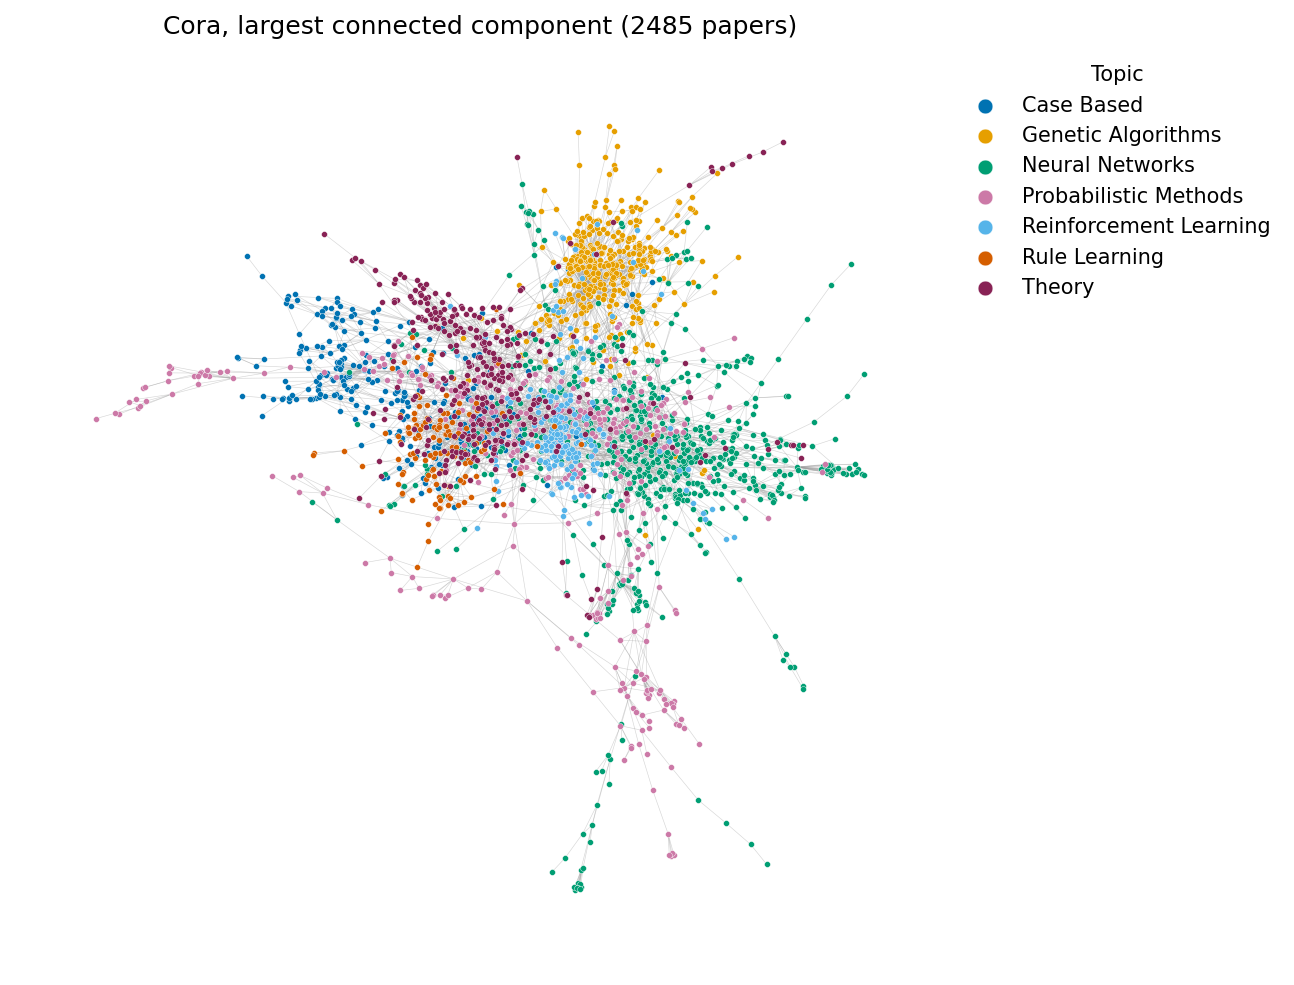

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8), dpi=150)
nx.draw_networkx_edges(G_giant, pos_cora, ax=ax, width=0.3, alpha=0.4, edge_color='0.6')

for t, topic in enumerate(topics):
    members = [u for u in G_giant if y_cora[u] == t]
    ax.scatter(*np.array([pos_cora[u] for u in members]).T, s=8, color=SEVEN[t], edgecolor='w', linewidth=0.2,
               label=topic.replace('_', ' '), zorder=2)

ax.legend(loc='upper left', bbox_to_anchor=(1, 1), markerscale=2.5, frameon=False, title='Topic')
ax.set_title(f'Cora, largest connected component ({len(giant)} papers)')
ax.axis('off')

plt.show()

Papers on the same topic mostly clump together, but the clumps overlap, especially in the middle, where a lot of papers have neighbors on other topics. We'd guess that papers whose neighbors share their topic will be easy for a model that uses the network, and papers whose neighbors mostly don't will be harder. We'll check that guess once we've trained a GCN.

#### Training, validation and test papers

The data file has every paper's topic, but we'll pretend we know the topics of only a few papers, 20 per topic (140 in all), and try to predict the topic of every other paper. All 2,708 papers, with their words and links, stay in the network the whole time. Only the 140 training papers' topics are used to fit the model. In real life labels cost money, because someone has to read the paper. We use the same sizes as Kipf & Welling (2017), who took a common benchmark setup for Cora (Yang et al., 2016) and added 500 papers for validation: 140 papers for training, 500 for validation, and 1,000 for testing. They report 81.5% test accuracy for a GCN on their fixed split, and 80.1% on average over 10 random splits of the same sizes. Their model also does two things ours leaves out (dropout, which randomly zeroes out half of the numbers going into each layer at every training step, and stopping training once the validation loss stops improving). They also only penalize big weights in the first layer, and their code rescales each paper's row of words to add up to 1, so our numbers won't exactly match theirs.

In [46]:
def make_split(seed):
    # 20 training papers per topic, then 500 for validation and 1,000 for testing, all at random
    rng = np.random.default_rng(seed)
    train_idx = np.concatenate([rng.choice(np.flatnonzero(y_cora == t), 20, replace=False) for t in range(7)])
    rest = rng.permutation(np.setdiff1d(np.arange(n), train_idx))
    return train_idx, rest[:500], rest[500:1500]


split = make_split(SEED)
train_idx, val_idx, test_idx = split

print(f'{len(train_idx)} training papers, {len(val_idx)} validation papers, {len(test_idx)} test papers')

140 training papers, 500 validation papers, 1000 test papers


### Why would we want a GNN?

We have 2,708 papers, and the model only gets to see the topics of 140 of them, about 5%. What could we use to guess the rest? There are three options:

1. **Only the words.** Train a model on the labeled papers' words, the way the model in Part 1 learned from the moons' two coordinates. This ignores the network.
2. **Only the links.** Guess each paper's topic from the topics of the labeled papers it's linked to. This ignores the words.
3. **Both.** Mix each paper's words with its neighbors' words, and learn from the result. That's what a GNN does.

Let's start with option 2. How many papers are linked to a labeled paper at all?

In [47]:
labeled = np.zeros(n, dtype=bool)
labeled[train_idx] = True

has_labeled_neighbor = np.array([labeled[list(G_cora.neighbors(u))].any() for u in range(n)])
within_2_hops = np.array([labeled[[v for v in nx.single_source_shortest_path_length(G_cora, u, cutoff=2) if v != u]].any()
                          for u in range(n)])

print(f'papers linked to at least one labeled paper:  {has_labeled_neighbor.mean():.0%}')
print(f'papers with a labeled paper within 2 hops:    {within_2_hops.mean():.0%}')

papers linked to at least one labeled paper:  17%
papers with a labeled paper within 2 hops:    60%


Only 17% of the papers are linked to even one labeled paper, so for the other 83%, option 2 has no neighbor's topic to go on. (Methods that spread the known topics further out through the network do better than this, and we'll see one in a table from the GCN paper below.) Going out to 2 hops gets us to 60%, but a paper 2 hops away is less likely to share the topic. Every paper has words, though, and so does every one of its neighbors, labeled or not. Option 3 can use all of them.

Before we build anything new, let's test option 3 with a model we already know: logistic regression, from Wednesday. scikit-learn's `LogisticRegression` handles seven topics by giving each topic its own score and picking the highest (we'll see how scores like these turn into probabilities when we get to the softmax below). We fit it three times, always on the same 140 labeled papers, and score it on the 500 validation papers:
- on each paper's own words (option 1),
- on each paper's words averaged with its neighbors' words, where every paper counts itself as one of its own neighbors so that its own words stay in the mix,
- and on those averaged words, averaged once more the same way, which mixes in the neighbors' neighbors.

In matrix language, the averaging is multiplying $X$ by $D^{-1}A$ from Part 2, after adding a self-loop to every node. There's no neural network here, and nothing about the averaging is learned.

In [48]:
from scipy import sparse

A_loops = nx.to_scipy_sparse_array(G_cora, nodelist=range(n)) + sparse.identity(n, format='csr')  # A plus a self-loop on every node
average = sparse.diags(1 / A_loops.sum(axis=1)) @ A_loops    # D^-1 A: every row adds up to 1
X_avg1 = average @ X_cora    # each paper's words, averaged with its neighbors' words

X_avg2 = average @ X_avg1    # ...and averaged once more

val_acc = {}
for name, X_in in [('own words only', X_cora), ('averaged once', X_avg1), ('averaged twice', X_avg2)]:
    logreg_cora = LogisticRegression(max_iter=1000).fit(X_in[train_idx], y_cora[train_idx])
    val_acc[name] = logreg_cora.score(X_in[val_idx], y_cora[val_idx])
    print(f'{name:15s} validation accuracy: {val_acc[name]:.3f}')

own words only  validation accuracy: 0.582
averaged once   validation accuracy: 0.778
averaged twice  validation accuracy: 0.804


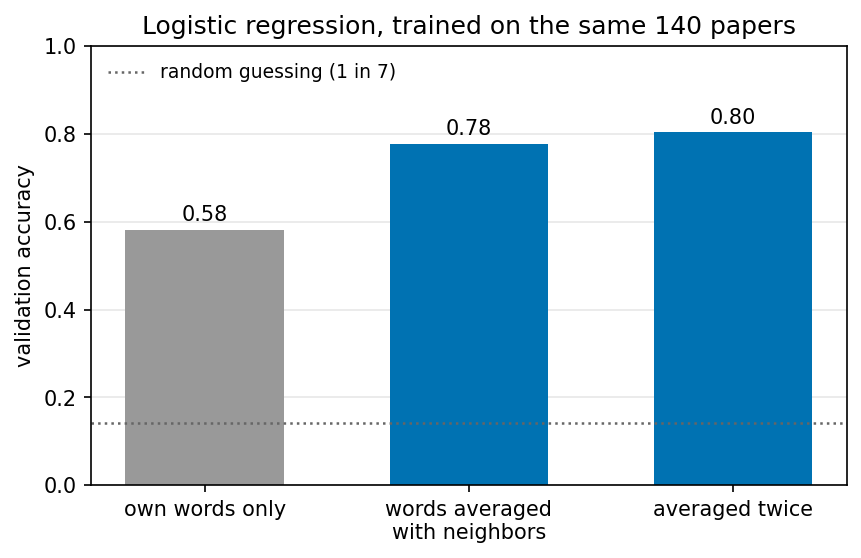

In [49]:
fig, ax = plt.subplots(1, 1, figsize=(6.5, 3.8), dpi=150)
ax.bar(range(3), list(val_acc.values()), color=['0.6', TWO[0], TWO[0]], width=0.6)

for k, v in enumerate(val_acc.values()):
    ax.text(k, v + 0.02, f'{v:.2f}', ha='center')

ax.axhline(1 / 7, color='0.4', ls=':', lw=1.2, label='random guessing (1 in 7)')
ax.legend(loc='upper left', fontsize=9, frameon=False)
ax.set_xticks(range(3))
ax.set_xticklabels(['own words only', 'words averaged\nwith neighbors', 'averaged twice'])
ax.set_ylabel('validation accuracy')
ax.set_ylim(0, 1)
ax.set_title('Logistic regression, trained on the same 140 papers')
ax.grid(alpha=0.3, axis='y')

plt.show()

With only its own words, logistic regression gets 0.58 of the validation papers right. Averaging each paper's words with its neighbors' takes it to 0.78, and averaging twice takes it to 0.80. The model and the 140 labels are the same in all three. The only thing that changed is that each paper's input now includes some of its neighbors' words.

Why does that help so much? A paper uses only about 18 of the 1,433 words, so its own words are thin evidence about its topic. Let's see how many words two papers have in common, using 20,000 random pairs of papers:

In [50]:
rng = np.random.default_rng(SEED)
pairs = rng.choice(n, size=(20000, 2))                     # 20,000 random pairs of papers
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
same_pair = y_cora[pairs[:, 0]] == y_cora[pairs[:, 1]]
shared_words = (X_cora[pairs[:, 0]] * X_cora[pairs[:, 1]]).sum(axis=1)

print(f'words shared by two papers on the same topic:   {shared_words[same_pair].mean():.2f} on average')
print(f'words shared by two papers on different topics: {shared_words[~same_pair].mean():.2f} on average')
print(f'same-topic pairs that share no words at all:    {(shared_words[same_pair] == 0).mean():.0%}')

words shared by two papers on the same topic:   1.31 on average
words shared by two papers on different topics: 0.96 on average
same-topic pairs that share no words at all:    34%


Two papers on the same topic share only about 1.3 words on average, and a third of them share none at all, compared with about 1 word for two papers on different topics. But 81% of links join two papers on the same topic, so averaging in a paper's neighbors' words is like averaging several noisy measurements of the same thing: the noise partly cancels out, and the topic shows through more clearly. On Cora, this works because of homophily. If most links joined papers on different topics, averaging would mix in the wrong topics' words.

A GNN does the same averaging, but it puts a little neural network on every node, like in Part 2, so the model learns how to transform the words while it averages them. And because every node uses the same weights, 140 labeled papers are enough to train a model that works on all 2,708.

Kipf & Welling compared all three kinds of methods on Cora, and on three other datasets, in the paper that introduced the GCN. Here's their Table 2:

![Table 2 from Kipf & Welling (2017)](./images/kipf_welling_table2.png)

*Table 2 from Kipf & Welling (2017). Each number is the percent of test nodes a method got right.*

Look at the Cora column. Every method here learned from 20 labeled papers per topic, 140 in all, like we have. LP (label propagation) uses only the links and the 140 known topics: it spreads the known topics out through the network, step by step, until every paper has a guess. DeepWalk learns a vector for each paper from random walks on the links (it's a close cousin of node2vec, in Appendix B). These two get 68.0% and 67.2%, so the links are worth a lot once the labels can travel more than one hop. ManiReg and SemiEmb learn from the words and use the links only to nudge linked papers toward similar answers, and they get about 59%, close to our words-only model. ICA and Planetoid feed both the words and the links into the prediction itself, and get about 75%. The GCN gets 81.5%. The last row, 80.1%, is the GCN's average over 10 random splits like ours.

Here's how Kipf & Welling drew a GCN in their paper:

![Figure 1a from Kipf & Welling (2017)](./images/kipf_welling_fig1a.png)

*Figure 1a from Kipf & Welling (2017).*

On the left is the input: the network, with a feature vector $X_i$ on every node. Each $X_i$ has $C$ numbers in it (for us, $C$ = 1,433 words), and the stack of cards behind the network stands for those $C$ numbers (the paper calls them channels). The hidden layers in the middle are layers like the ones in Part 2, and the paper's caption points out that every layer uses the same links (the black lines), even though each layer has its own weights. On the right, every node ends up with $F$ numbers $Z_i$ (for us, $F$ = 7, one score per topic). Only some nodes have a label $Y_i$ (here, nodes 1 and 4), just like our 140 papers. Only the labeled nodes count in the loss, but every node's features feed into its neighbors' vectors, so the unlabeled nodes help, too.

### The GCN layer

A GCN layer works like our Part 2 layer, with two changes: it uses one weight matrix instead of two, and it averages in a slightly different way. We'll use it for a few reasons. It has half as many weights as our Part 2 layer. Each layer runs every node's vector through the same weight matrix, then does one multiplication by a matrix that's mostly zeros, so the cost of the averaging grows with the number of links, and it stays fast on big networks (as far as GNNs go). And it's the standard model that newer GNNs compare themselves against.

Let's tackle what happens in GCNs at the node level first. We'll look at how we create the new vector for node $i$, $h_i$. Our Part 2 layer had two weight matrices, one for the node itself and one for its neighbors. A GCN uses only one: it treats each node as one of its own neighbors. That's simpler, but it costs something, because a node's own vector now goes through exactly the same weights as its neighbors' vectors. The model can't learn to transform a paper's own words differently from its neighbors' words. We'll write $\tilde{N}_i$ for $i$'s neighbors $N_i$ plus $i$ itself, and $\tilde{k}_i = k_i + 1$ for how many nodes that is.

The simplest thing we could do is multiply each node $j$'s features $x_j$ by a weight matrix $W$, then sum them:

$$h_i = \sum_{j \in \tilde{N}_i} x_j W$$

**INTERACTIVE MOMENT**: Nodes in graphs don't all have the same degree. Say every node had the same input vector. How would the sum for a node with two neighbors compare with the sum for a node with twenty, and how might we fix that?

--------------------

Spoiler alert: we're going to divide by $\tilde{k}_i$. This keeps vector magnitudes around the same-ish size, and it turns the sum into an average, like in Part 2:

$$h_i = \frac{1}{\tilde{k}_i}\sum_{j \in \tilde{N}_i} x_j W$$

Let's see the problem and the fix on Cora. We'll leave out $W$, because it treats every paper the same way, so it can't undo a difference that depends on degree. For every paper, we add up its own word vector and its neighbors' word vectors, and measure the length of the result. Then we do the same with the average.

In [51]:
k_tilde_cora = A_loops.sum(axis=1)       # degree plus one, for every paper
summed = A_loops @ X_cora                # row i: paper i's words plus all of its neighbors' words
length_sum = np.linalg.norm(summed, axis=1)
length_avg = np.linalg.norm(summed / k_tilde_cora[:, None], axis=1)

print(f'correlation between degree and length: sum {np.corrcoef(k_tilde_cora, length_sum)[0, 1]:.2f}, '
      f'average {np.corrcoef(k_tilde_cora, length_avg)[0, 1]:.2f}')

for k in [2, 11]:
    print(f'papers with k_tilde = {k}: average length {length_sum[k_tilde_cora == k].mean():.1f} with the sum, '
          f'{length_avg[k_tilde_cora == k].mean():.1f} with the average')

correlation between degree and length: sum 0.97, average -0.44
papers with k_tilde = 2: average length 6.4 with the sum, 3.2 with the average
papers with k_tilde = 11: average length 21.7 with the sum, 2.0 with the average


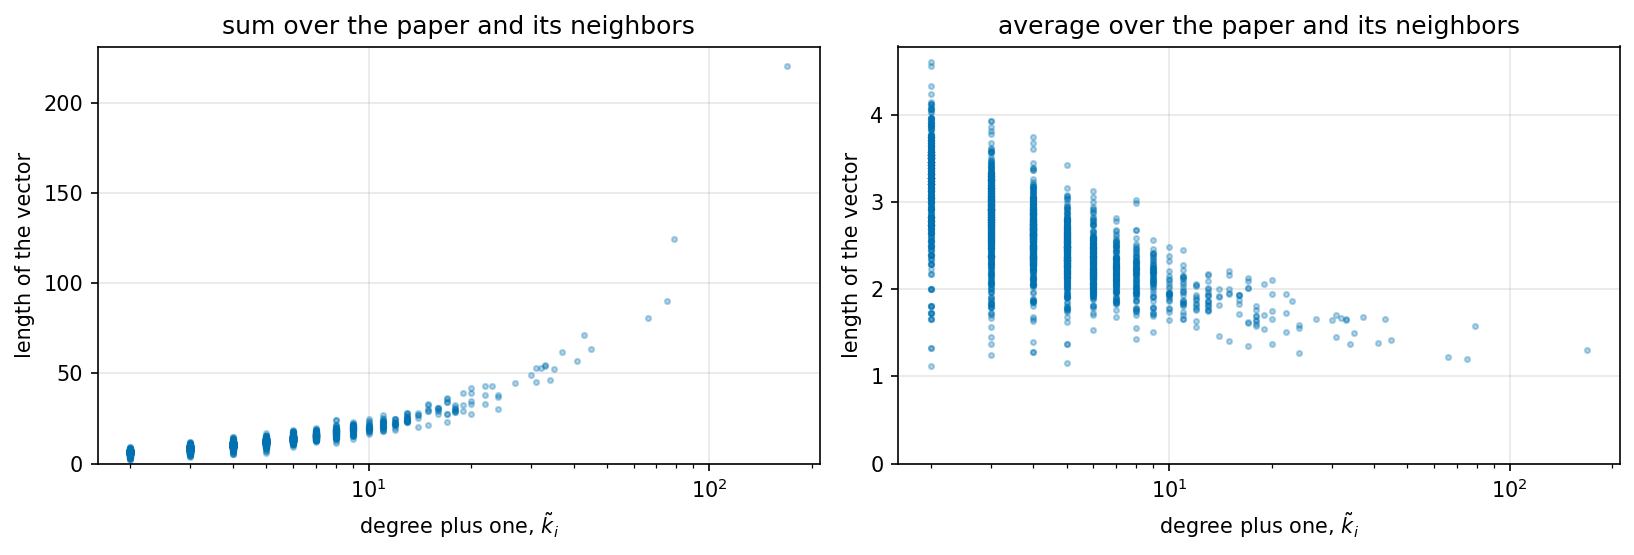

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=150)

for ax, lengths, title in [(axes[0], length_sum, 'sum over the paper and its neighbors'),
                           (axes[1], length_avg, 'average over the paper and its neighbors')]:
    ax.scatter(k_tilde_cora, lengths, s=6, alpha=0.3, color=TWO[0])
    ax.set_xscale('log')
    ax.set_xlabel(r'degree plus one, $\tilde{k}_i$')
    ax.set_ylabel('length of the vector')
    ax.set_ylim(0, None)
    ax.set_title(title)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Each dot is one paper. With the sum (left), the length grows right along with the degree: papers with $\tilde{k} = 2$ get vectors about 6.4 long on average, and papers with $\tilde{k} = 11$ get vectors about 21.7 long. Stack a few layers like this, and the papers with the most links would tend to get bigger and bigger vectors, just because of their degree. With the average (right), the lengths stay around the same size, and even shrink a little as the degree grows, because an average of many different rows of zeros and ones has lots of small numbers in it.

The GCN paper uses a slightly different weighting. It comes out of the paper's derivation from spectral graph theory, along with a fix the authors call the "renormalization trick", which adds the self-loops before dividing. Each neighbor $j$ gets the weight $1/\sqrt{\tilde{k}_i \tilde{k}_j}$ instead of $1/\tilde{k}_i$:

$$h_i = \sum_{j \in \tilde{N}_i} \frac{1}{\sqrt{\tilde{k}_i}}\frac{1}{\sqrt{\tilde{k}_j}} x_j W$$

Compared with a plain average, a neighbor with more links than node $i$ counts for less, and a neighbor with fewer links counts for more. (Divide the two weights and you get $\sqrt{\tilde{k}_i / \tilde{k}_j}$, which is bigger than 1 exactly when $\tilde{k}_j < \tilde{k}_i$.) The idea is that if one of your neighbors is linked to a hundred papers, its link to you says less about you in particular than a link from a neighbor with only three. It's the same idea as the Adamic–Adar index from Wednesday, where a common neighbor with lots of links counted for less.

Tiny graph time again: three nodes in a row, where node 1 is linked to node 0 and to node 2. With the self-loops, the end nodes have $\tilde{k} = 2$ and the middle node has $\tilde{k} = 3$.

In [53]:
A_path = nx.to_numpy_array(nx.path_graph(3))
A_tilde_path = A_path + np.eye(3)            # add a self-loop to every node
k_tilde_path = A_tilde_path.sum(axis=1)      # degree plus one

plain_path = A_tilde_path / k_tilde_path[:, None]                           # plain average: divide row i by k_i
A_hat_path = A_tilde_path / np.sqrt(np.outer(k_tilde_path, k_tilde_path))   # GCN: divide entry (i, j) by sqrt(k_i * k_j)

print('degree plus one:', k_tilde_path)

degree plus one: [2. 3. 2.]


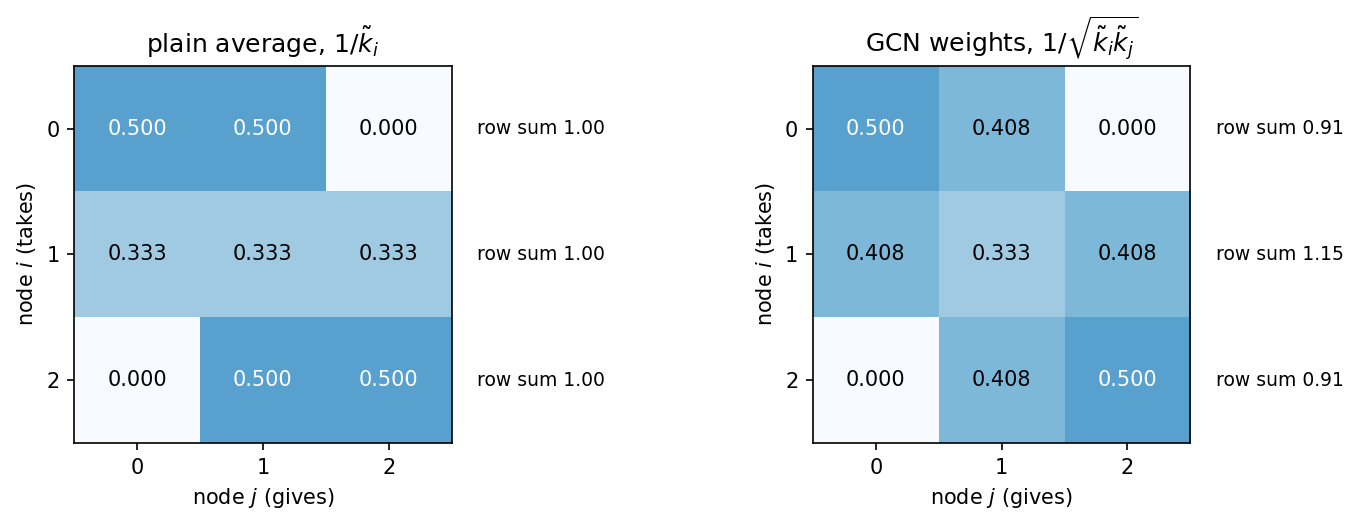

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=150)

for ax, weights, title in [(axes[0], plain_path, r'plain average, $1/\tilde{k}_i$'),
                           (axes[1], A_hat_path, r'GCN weights, $1/\sqrt{\tilde{k}_i \tilde{k}_j}$')]:
    ax.imshow(weights, cmap='Blues', vmin=0, vmax=0.9)

    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{weights[i, j]:.3f}', ha='center', va='center',
                    color='w' if weights[i, j] > 0.45 else 'k')
        ax.text(2.7, i, f'row sum {weights[i].sum():.2f}', va='center', fontsize=9)

    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xlabel('node $j$ (gives)')
    ax.set_ylabel('node $i$ (takes)')
    ax.set_title(title)

plt.tight_layout()
plt.show()

Row $i$ says how much node $i$ takes from each node $j$, and darker means more. With a plain average (left), node 0 takes half of its new vector from itself and half from node 1. With the GCN weights (right), it takes 0.5 from itself and only 0.408 from node 1, because node 1 has more links. The middle node goes the other way: it takes 0.408 from each end instead of 0.333. We'll call this matrix of GCN weights $\hat{A}$ ("A-hat"). Its entry $(i, j)$ is $1/\sqrt{\tilde{k}_i \tilde{k}_j}$ if $j$ is $i$ itself or one of its neighbors, and 0 otherwise.

The GCN's rows don't add up to exactly 1 anymore. Here they're close (0.91, 1.15 and 0.91), but that isn't true in general. A row tends to add up to more than 1 when the node's neighbors have fewer links than it does, like the middle node here, and to less than 1 when they have more. In Cora, as we'll check when we build $\hat{A}$ in PyTorch below, the row sums run from about 0.46 to 5.7. So why don't vectors blow up as we stack layers? Let's look at the eigenvalues of the GCN weights.

In [55]:
print('eigenvalues of the GCN weights:', np.linalg.eigvalsh(A_hat_path).round(3))

eigenvalues of the GCN weights: [-0.167  0.5    1.   ]


Every eigenvalue is between $-1$ and 1, and the biggest is exactly 1. That's true of $\hat{A}$ for any undirected network. Multiplying by a symmetric matrix like this can make some nodes' vectors longer and others shorter, but the sum of all their squared lengths never grows.

Kipf & Welling's first version of the layer, before the renormalization trick, added the self-loop *after* dividing. It used the matrix $I + D^{-\frac{1}{2}} A D^{-\frac{1}{2}}$, where $D$ has the plain degrees $k_i$ on the diagonal: each node keeps all of its own vector and adds each neighbor's vector divided by $\sqrt{k_i k_j}$. That matrix has eigenvalues between 0 and 2, and Kipf & Welling pointed out that multiplying by it over and over could make the numbers blow up or die out in a deep model. Let's see it happen. We'll take Cora's word vectors, multiply them by each matrix 10 times, with no weights and no ReLU, and keep track of the total length of all the vectors together (the square root of the sum of all the squared numbers).

In [56]:
A_cora = nx.to_scipy_sparse_array(G_cora, nodelist=range(n))
k_cora = np.asarray(A_cora.sum(axis=1)).ravel()     # plain degrees; every paper has at least 1
first_version = sparse.identity(n) + sparse.diags(1 / np.sqrt(k_cora)) @ A_cora @ sparse.diags(1 / np.sqrt(k_cora))
A_hat_cora = sparse.diags(1 / np.sqrt(k_cora + 1)) @ (A_cora + sparse.identity(n)) @ sparse.diags(1 / np.sqrt(k_cora + 1))

total_length = {}
for name, matrix in [('first version', first_version), ('GCN', A_hat_cora)]:
    H = X_cora.astype(float)
    total_length[name] = [np.linalg.norm(H)]

    for times in range(10):
        H = matrix @ H
        total_length[name].append(np.linalg.norm(H))

for name, lengths in total_length.items():
    print(f'{name:14s} total length compared with the start:', ' '.join(f'{v / lengths[0]:.2f}' for v in lengths))

first version  total length compared with the start: 1.00 1.29 2.16 3.89 7.26 13.81 26.57 51.51 100.38 196.41 385.51
GCN            total length compared with the start: 1.00 0.58 0.49 0.45 0.42 0.40 0.39 0.38 0.37 0.36 0.36


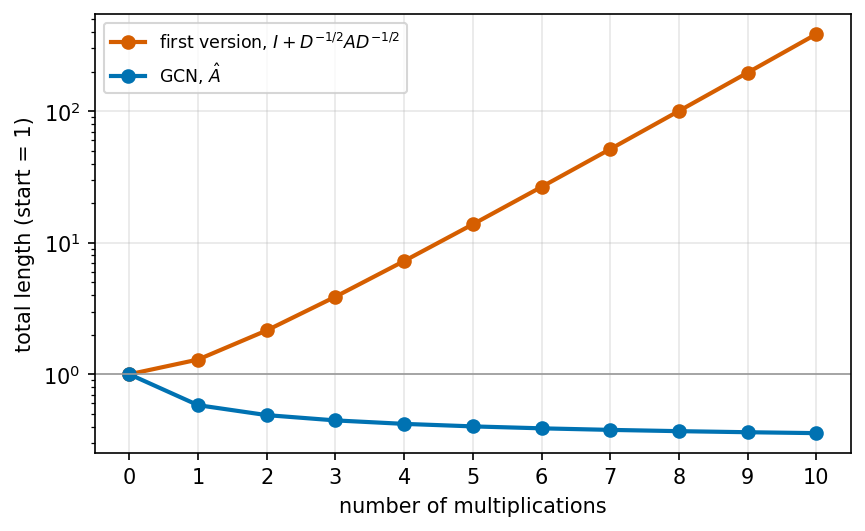

In [57]:
fig, ax = plt.subplots(1, 1, figsize=(6.5, 3.8), dpi=150)

for name, color in [('first version', TWO[1]), ('GCN', TWO[0])]:
    lengths = np.array(total_length[name])
    ax.plot(range(11), lengths / lengths[0], 'o-', color=color, lw=2,
            label='first version, $I + D^{-1/2} A D^{-1/2}$' if name == 'first version' else r'GCN, $\hat{A}$')

ax.set_yscale('log')
ax.axhline(1, color='0.6', lw=0.8)
ax.set_xlabel('number of multiplications')
ax.set_ylabel('total length (start = 1)')
ax.set_xticks(range(11))
ax.legend(loc='upper left', fontsize='small')
ax.grid(alpha=0.3)

plt.show()

With the first version (orange), the total length grows faster and faster, and by the end each multiplication nearly doubles it: after 10 multiplications, the total length is about 385 times what it was at the start. This is the power iteration from Class 4 again. Each multiplication scales the part of the vectors that lines up with the top eigenvector by the top eigenvalue, and for the first version that's 2, so that part doubles every time and soon takes over. With $\hat{A}$ (blue), the top eigenvalue is exactly 1, so the total length can't grow. The total length drops to about 0.58 of where it started after one multiplication, because averaging cancels out some of the differences between neighbors, and then it levels off around 0.36. Each GCN layer also has its own weights, which can stretch or shrink the vectors too, but a matrix that doubles part of every vector at every layer is the kind of thing that makes deep models unstable, and that's what Kipf & Welling were worried about.

(The plain average can't blow up either, because an average of vectors is never longer than the longest of them. Your Turn option 2 below tries a layer with a plain average on Cora.)

#### Matrix formulation
There's also a neat way we can formulate this as a matrix multiplication. Here, $\tilde{A} = A + I$ is the adjacency matrix with self-loops added, and $\tilde{D}$ is the diagonal matrix with the $\tilde{k}_i$ on the diagonal (the degrees of $\tilde{A}$), so $\tilde{D}^{-\frac{1}{2}}$ has $1/\sqrt{\tilde{k}_i}$ on the diagonal. Write $\hat{A} = \tilde{D}^{-\frac{1}{2}} \tilde{A} \tilde{D}^{-\frac{1}{2}}$. Multiplying by $\tilde{D}^{-\frac{1}{2}}$ on the left divides row $i$ by $\sqrt{\tilde{k}_i}$, and multiplying on the right divides column $j$ by $\sqrt{\tilde{k}_j}$, so the entries of $\hat{A}$ are exactly the weights $1/\sqrt{\tilde{k}_i \tilde{k}_j}$ from above. (The right-hand panel above is $\hat{A}$ for our three nodes in a row.) $H^{(l-1)}$ is the matrix of node vectors coming into layer $l$, one row per node (for the first layer, $H^{(0)} = X$). $W^{(l)}$ is the weight matrix of layer $l$, and $b^{(l)}$ is its bias, added to every row:

$$H^{(l)} = \text{ReLU}\big(\hat{A} H^{(l-1)} W^{(l)} + b^{(l)}\big)$$

Compare it with Part 2: $\hat{A}$ does the averaging, $W^{(l)}$ and $b^{(l)}$ are the little neural network, and the ReLU is its activation. The last layer skips the ReLU. Its outputs are the 7 topic scores, which go into a softmax instead (more on that below), and a ReLU there would turn every negative score into 0.

### Building a GCN in PyTorch

We're going to use [`pytorch`](https://pytorch.org/) to build and train our GCN. Pytorch is a widely used package for building & training neural networks. Neural networks do a lot of vector and matrix multiplication, which is very easy to parallelize on a GPU (graphics processing unit), a chip that's great at doing a lot of tiny calculations at the same time. Our `cmns-ml` environment has the CPU version of PyTorch, and Cora is small enough that a CPU is fine.

First we turn everything into PyTorch **tensors** (PyTorch's version of numpy arrays) and build $\hat{A}$. Most entries of $\hat{A}$ are zero, so we store it as a **sparse** matrix, which keeps only the entries that aren't zero. We build it straight from the formula: every link in both directions, plus a self-loop on every node, each with weight $1/\sqrt{\tilde{k}_i \tilde{k}_j}$.

In [58]:
import torch
import torch.nn.functional as F

torch.manual_seed(SEED)       # PyTorch has its own random numbers (for the starting weights), so it gets its own seed
X = torch.tensor(X_cora)      # the word features, as a PyTorch tensor: one row per paper
y = torch.tensor(y_cora)      # the topics, as numbers from 0 to 6

# A_hat as a list of its nonzero entries: entry (src[e], dst[e]) has the value 1 / sqrt(k_i * k_j)
edges = torch.tensor(list(G_cora.edges())).T                # 2 x (number of links): row 0 is one end, row 1 the other
src = torch.cat([edges[0], edges[1], torch.arange(n)])      # each link in both directions, plus a self-loop on every node
dst = torch.cat([edges[1], edges[0], torch.arange(n)])
k_tilde = torch.bincount(src, minlength=n).float()          # degree plus one: how many times each node shows up in src
A_hat = torch.sparse_coo_tensor(torch.stack([src, dst]), 1 / torch.sqrt(k_tilde[src] * k_tilde[dst]), (n, n)).coalesce()

Sanity check: let's make sure this matches the formula $\tilde{D}^{-\frac{1}{2}} \tilde{A} \tilde{D}^{-\frac{1}{2}}$, computed the slow way with an ordinary matrix that stores every entry.

In [59]:
A_dense = nx.to_numpy_array(G_cora, nodelist=range(n)) + np.eye(n)
d_half = 1 / np.sqrt(A_dense.sum(axis=1))
A_hat_dense = d_half[:, None] * A_dense * d_half[None, :]

print('Matches the formula:', np.allclose(A_hat.to_dense().numpy(), A_hat_dense, atol=1e-6))
print(f'A_hat has {n * n:,} entries, and only {len(src):,} of them are not zero')
print(f'row sums of A_hat run from {A_hat_dense.sum(axis=1).min():.2f} to {A_hat_dense.sum(axis=1).max():.2f}')
print(f'eigenvalues of A_hat run from {np.linalg.eigvalsh(A_hat_dense).min():.2f} to {np.linalg.eigvalsh(A_hat_dense).max():.2f}')

Matches the formula: True
A_hat has 7,333,264 entries, and only 13,264 of them are not zero
row sums of A_hat run from 0.46 to 5.75


eigenvalues of A_hat run from -0.48 to 1.00


It matches. Fewer than 0.2% of the entries of $\hat{A}$ aren't zero, which is why storing it as a sparse matrix pays off. And the eigenvalues of Cora's $\hat{A}$ are between $-1$ and 1, like the ones for our three nodes in a row.

Last, the identity matrix $I$. Every node's only "neighbor" is itself, so swapping it in for $\hat{A}$ removes the network. We'll use it for our baseline in a minute.

In [60]:
I = torch.sparse_coo_tensor(torch.arange(n).repeat(2, 1), torch.ones(n), (n, n)).coalesce()

Now the model. In PyTorch a model is a Python class. Its `__init__` creates the weights, its `forward` says what to do with an input, and calling `model(X, A_hat)` runs `forward`. `GCNLayer` is one layer: multiply by the weight matrix, then by $\hat{A}$, then add a bias. (The order doesn't matter, because $\hat{A}(HW) = (\hat{A}H)W$, and multiplying by $W$ first is faster because it makes the vectors shorter.) `GCN` stacks layers with a ReLU between them. Our model has two layers: 1,433 numbers per paper go in, the hidden layer has 16, and 7 come out, one score per topic.

In [61]:
class GCNLayer(torch.nn.Module):
    # One GCN layer: A_hat @ H @ W + b. (The ReLU happens in the GCN model below.)
    def __init__(self, n_in, n_out):
        super().__init__()
        self.W = torch.nn.Linear(n_in, n_out, bias=False)   # the weight matrix, shared by every node
        self.b = torch.nn.Parameter(torch.zeros(n_out))      # the bias, also shared

    def forward(self, H, A_hat):
        return torch.sparse.mm(A_hat, self.W(H)) + self.b


class GCN(torch.nn.Module):
    # A stack of GCN layers. sizes=[1433, 16, 7]: 1,433 numbers in, 16 in the hidden layer, 7 out.
    def __init__(self, sizes):
        super().__init__()
        self.layers = torch.nn.ModuleList([GCNLayer(a, b) for a, b in zip(sizes[:-1], sizes[1:])])

    def forward(self, X, A_hat):
        H = X
        for layer in self.layers[:-1]:
            H = torch.relu(layer(H, A_hat))
        self.hidden = H                    # keep the last hidden layer so we can look at it later
        return self.layers[-1](H, A_hat)   # 7 scores per paper, one per topic

In [62]:
model = GCN([1433, 16, 7])

print(model)
print('numbers to learn:', sum(p.numel() for p in model.parameters()))

GCN(
  (layers): ModuleList(
    (0): GCNLayer(
      (W): Linear(in_features=1433, out_features=16, bias=False)
    )
    (1): GCNLayer(
      (W): Linear(in_features=16, out_features=7, bias=False)
    )
  )
)
numbers to learn: 23063


In the printout, each layer's `Linear(..., bias=False)` is its weight matrix, $1{,}433 \times 16$ for the first layer and $16 \times 7$ for the second. (If you look at `.weight.shape`, PyTorch stores each one the other way around, as $16 \times 1{,}433$, and transposes it when it multiplies.) The biases aren't missing: they're the separate `self.b`, because we add the bias after the averaging, the same way PyTorch Geometric does it (more on that library below). If we added it before, $\hat{A}$ would mix the bias in along with everything else, and since the rows of $\hat{A}$ add up to anywhere from 0.46 to 5.7, every paper would end up with a different multiple of it. That's $1{,}433 \times 16 + 16 + 16 \times 7 + 7 = 23{,}063$ numbers to learn from only 140 labeled papers.

If we hand the model the identity matrix $I$ instead of $\hat{A}$, every node only "averages" with itself, and the GCN turns back into a plain neural network like the one in Part 1, looking at each paper's words and nothing else. It's the same code with the same number of weights, so the only difference between the two models is whether they see the network. We'll use it as our baseline.

![the GCN and the same model with no network](./images/gcn_cora.png)

Each row is one model, read from left to right. The rows are identical except for the blue boxes: the GCN averages each paper with its neighbors before each set of weights, and the model with no network multiplies by $I$, which leaves every paper's vector alone. Both end with 7 scores per paper, which the softmax turns into probabilities.

#### The loss: cross-entropy
For each paper the model gives 7 scores $s_1, \dots, s_7$, one per topic. The **softmax** turns them into probabilities, $p_c = e^{s_c} / \sum_{c'} e^{s_{c'}}$. It's the many-class version of the sigmoid: every $p_c$ is between 0 and 1, and they add up to 1. For example, with three topics and scores $[2, 1, 0]$, we get $e^2 = 7.39$, $e^1 = 2.72$ and $e^0 = 1$, which add up to 11.11, so the probabilities are $[0.67, 0.24, 0.09]$. The **cross-entropy** loss for one paper is $-\log p_{\text{right topic}}$, the many-class version of the loss from Part 1, and we average it over the training papers. A model that knows nothing gives every topic $1/7$, for a loss of $\log 7 = 1.946$, so that's roughly where training should start.

#### The training loop
Each epoch, we run every paper through the network, compute the loss on the 140 training papers only, use backpropagation to get the gradient (the slope of the loss for every weight, like in Part 1), and let the optimizer move the weights. **Adam** (Kingma & Ba, 2015) is a fancier version of "move each weight a little bit downhill": it adjusts the step size for each weight depending on the size of its recent slopes. We also track accuracy on the training and validation papers as we go.

Notice that every paper goes through the model, labeled or not, and every paper gets 7 scores. Only the 140 training papers count in the loss, but the other papers still matter, because their words get averaged into their neighbors' vectors, including the training papers'. The model's guess for any paper is the topic with the highest score.

In [63]:
def accuracy(model, A_hat, idx):
    with torch.no_grad():                       # we're only looking, so we don't need gradients
        pred = model(X, A_hat).argmax(dim=1)    # the topic with the highest score
    return (pred[idx] == y[idx]).float().mean().item()


def train(model, A_hat, split, epochs=200):
    train_idx, val_idx, test_idx = split

    # weight_decay gently pulls every weight toward 0, which helps when there are only 140 labels
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

    history = []
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()                                     # clear out the last epoch's gradients
        scores = model(X, A_hat)                                  # run every paper through the network

        # only the training papers count; F.cross_entropy does the softmax and the -log for us
        loss = F.cross_entropy(scores[train_idx], y[train_idx])
        loss.backward()                                           # backpropagation: which way should each weight move?
        optimizer.step()                                          # move every weight a little bit

        with torch.no_grad():                                     # after the step: which papers does it get right now?
            pred = model(X, A_hat).argmax(dim=1)
        history.append({'epoch': epoch, 'loss': loss.item(),     # (the loss is from before this epoch's step)
                        'train': (pred[train_idx] == y[train_idx]).float().mean().item(),
                        'validation': (pred[val_idx] == y[val_idx]).float().mean().item()})

    return pd.DataFrame(history)

Now let's train both models on the same split we used for logistic regression, starting from the same random weights. (If you run this on a different computer, or with a different version of PyTorch, the numbers can come out a little different from the ones in the text.)

In [64]:
torch.manual_seed(SEED)
gcn = GCN([1433, 16, 7])
gcn_history = train(gcn, A_hat, split)

torch.manual_seed(SEED)
no_net = GCN([1433, 16, 7])
no_net_history = train(no_net, I, split)     # the same model, but every paper's only neighbor is itself

print(f'Loss before any training: {gcn_history.loss[0]:.3f} (log 7 = {np.log(7):.3f})')
print(f'Training accuracy at the end:   GCN {gcn_history.train.iloc[-1]:.2f}, no network {no_net_history.train.iloc[-1]:.2f}')
print(f'Validation accuracy at the end: GCN {gcn_history.validation.iloc[-1]:.3f}, no network {no_net_history.validation.iloc[-1]:.3f}')
print(f'Test accuracy, GCN:        {accuracy(gcn, A_hat, split[2]):.3f}')
print(f'Test accuracy, no network: {accuracy(no_net, I, split[2]):.3f}')

Loss before any training: 1.947 (log 7 = 1.946)
Training accuracy at the end:   GCN 1.00, no network 1.00
Validation accuracy at the end: GCN 0.792, no network 0.584
Test accuracy, GCN:        0.755
Test accuracy, no network: 0.553


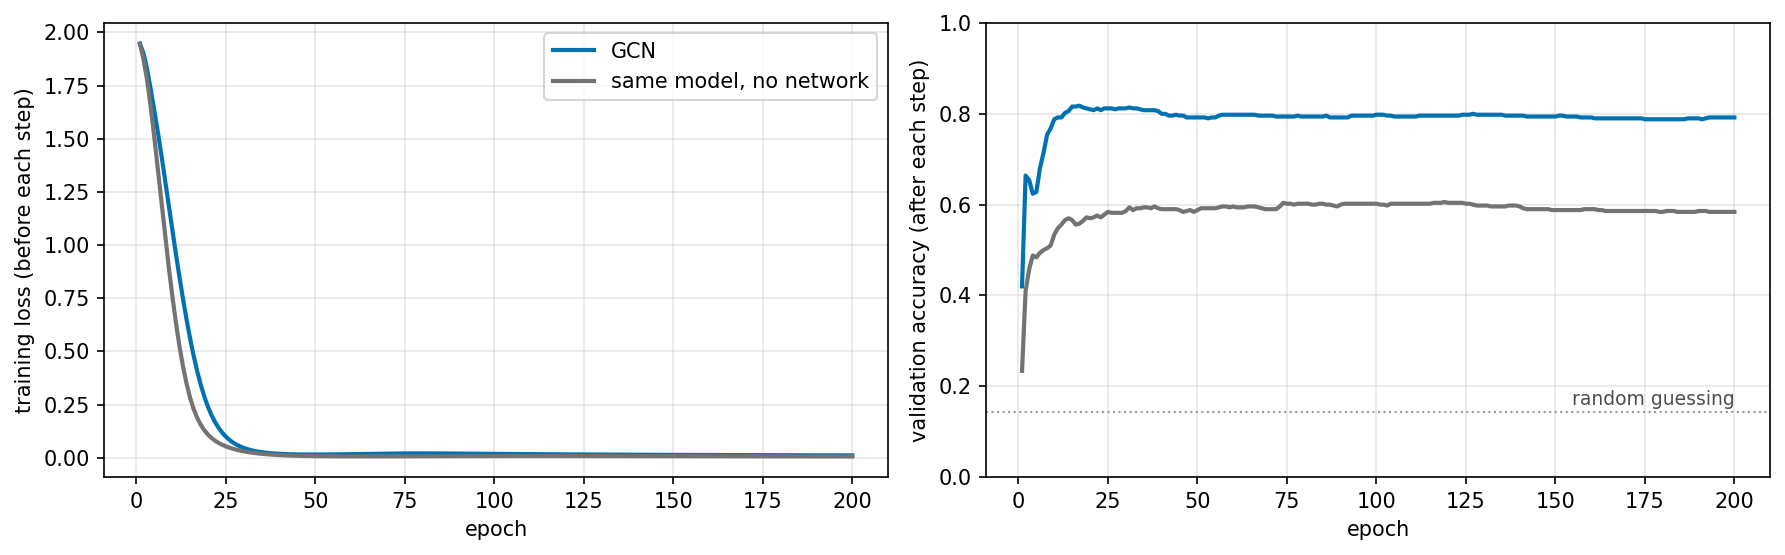

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), dpi=150)

for history, name, color in [(gcn_history, 'GCN', TWO[0]), (no_net_history, 'same model, no network', '0.45')]:
    axes[0].plot(history.epoch, history.loss, color=color, lw=2, label=name)
    axes[1].plot(history.epoch, history.validation, color=color, lw=2, label=name)

axes[0].set_ylabel('training loss (before each step)')
axes[1].set_ylabel('validation accuracy (after each step)')
axes[1].axhline(1 / 7, color='0.6', ls=':', lw=1)
axes[1].text(200, 1 / 7 + 0.015, 'random guessing', ha='right', fontsize=9, color='0.3')
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)

axes[0].legend(loc='upper right')

plt.tight_layout()
plt.show()

The loss starts at 1.947, right where a model that knows nothing should start. Both models get the training loss down to almost zero and get all 140 training papers right. With 23,000 weights and 140 papers that's easy, so training accuracy can't tell us which model is better, but validation accuracy can. The GCN levels off around 0.8 and the model with no network around 0.6. On the test papers, the GCN gets 0.755 right and the model with no network gets 0.553.

Notice that the GCN's validation accuracy, 0.792, is about the same as what logistic regression got on the twice-averaged words at the start of this part (0.80). So on Cora, most of what the GCN gains over the words-only model comes from mixing each paper's words with its neighbors' words. Wu et al. (2019) took this further: they removed the ReLUs (and the biases) from between a GCN's layers, which turns it into averaging the words a few times with $\hat{A}$ and then fitting a linear model, much like our logistic regression, and found that this didn't hurt accuracy in many of the tasks they tried.

If averaging the words twice and fitting logistic regression gets about as far, what does the GCN add by learning a hidden layer, with its own weights and a ReLU, in between the two rounds of averaging? On this split, not much, because Cora is friendly to averaging (more on that after the ten runs below). Learning matters more on harder problems. In networks where linked nodes tend to be different from each other, Zhu et al. (2020) found that it helps to keep a node's own vector separate from its neighbors' vectors, like our Part 2 layer did with $W_{\text{self}}$ and $W_{\text{neigh}}$, so the model can treat them differently. Graph attention networks (Veličković et al., 2018) go a step further and learn a rule that gives each neighbor its own weight, worked out from the two nodes' vectors, instead of using fixed averaging weights like $\hat{A}$'s. And when we want to predict something about a whole network instead of one node, the model has to learn node vectors that are still useful after they're combined into one vector for the whole network, which is Part 4.

### One paper up close

Before we run more splits, let's zoom in on a single test paper and see what the network did for it. First we count the test papers that one model gets right and the other gets wrong. Then we pick one of the papers that only the GCN gets right, on purpose: one with 3 to 5 neighbors, all on its own topic, and no training papers within 2 hops of it, so none of the papers that our two-layer GCN averages into this paper's vector has a label the GCN was trained on. We take the first paper on our list of test papers that fits.

In [66]:
with torch.no_grad():
    p_gcn = F.softmax(gcn(X, A_hat), dim=1).numpy()       # each paper's probability for each topic
    p_no_net = F.softmax(no_net(X, I), dim=1).numpy()

right_gcn = p_gcn.argmax(axis=1) == y_cora
right_no_net = p_no_net.argmax(axis=1) == y_cora

print('test papers only the GCN gets right:                   ', (right_gcn & ~right_no_net)[test_idx].sum())
print('test papers only the model with no network gets right: ', (~right_gcn & right_no_net)[test_idx].sum())


def labeled_within_2_hops(u):
    return sum(labeled[v] for v in nx.single_source_shortest_path_length(G_cora, u, cutoff=2) if v != u)


candidates = [u for u in test_idx if right_gcn[u] and not right_no_net[u] and 3 <= G_cora.degree(u) <= 5
              and all(y_cora[v] == y_cora[u] for v in G_cora.neighbors(u)) and labeled_within_2_hops(u) == 0]
if not candidates:   # in case the models come out differently on your computer, drop the conditions on the neighborhood
    candidates = [u for u in test_idx if right_gcn[u] and not right_no_net[u]]
paper = candidates[0]
ego = nx.ego_graph(G_cora, paper, radius=2)        # the paper and everything within 2 hops of it

print(f'\npaper {paper} (Cora ID {papers.paper_id[paper]}): topic {topics[y_cora[paper]]}, {G_cora.degree(paper)} neighbors, '
      f'{ego.number_of_nodes() - 1} papers within 2 hops, {labeled_within_2_hops(paper)} of them training papers')

test papers only the GCN gets right:                    255
test papers only the model with no network gets right:  53

paper 1896 (Cora ID 83746): topic Neural_Networks, 3 neighbors, 9 papers within 2 hops, 0 of them training papers


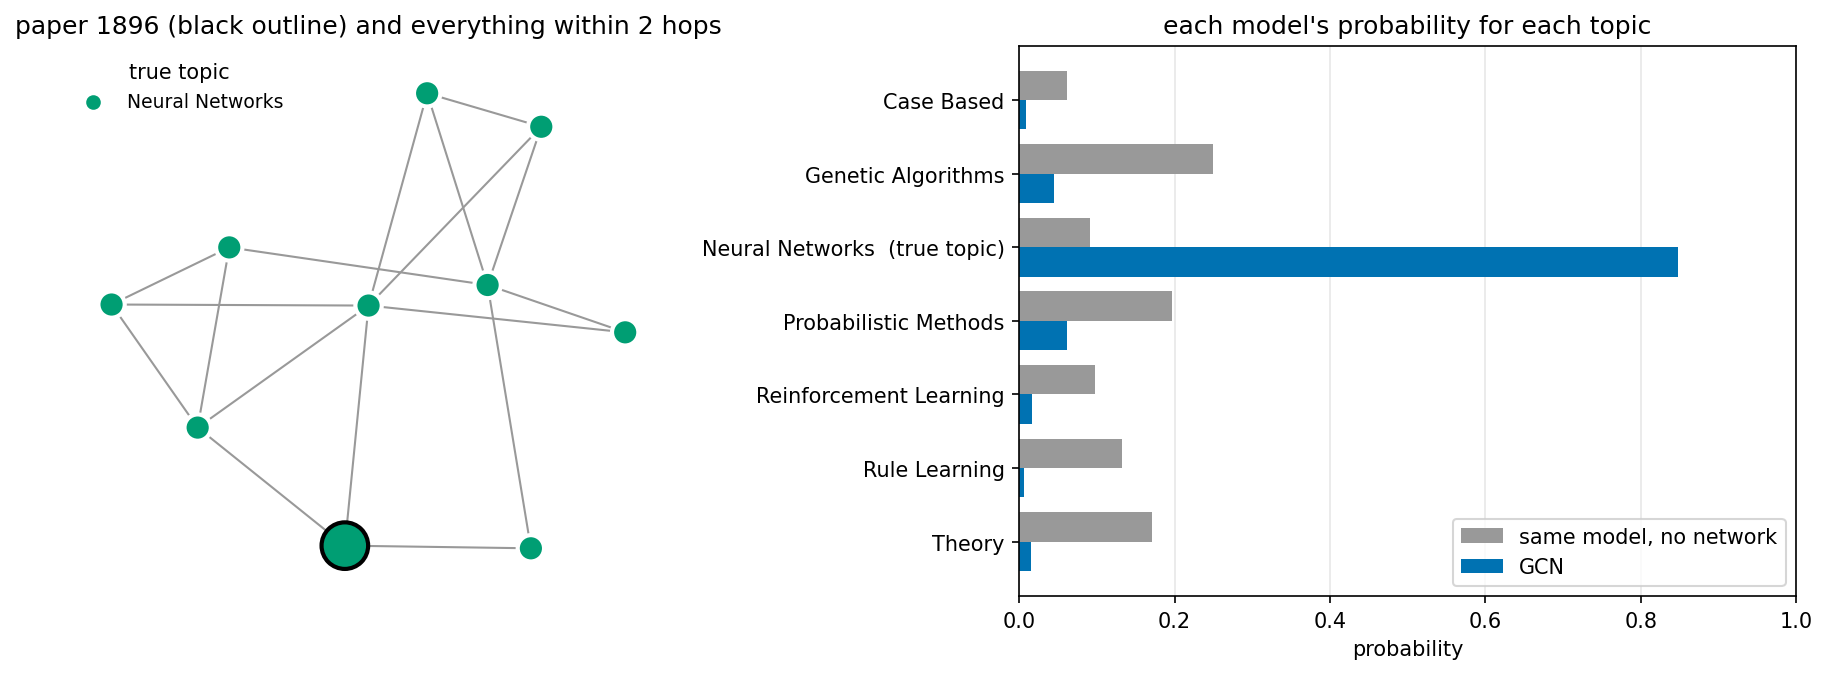

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=150, gridspec_kw={'width_ratios': [1, 1.25]})
pos_ego = nx.spring_layout(ego, seed=SEED)
nx.draw_networkx_edges(ego, pos_ego, ax=axes[0], edge_color='0.6')
nx.draw_networkx_nodes(ego, pos_ego, ax=axes[0], nodelist=list(ego), node_color=[SEVEN[y_cora[u]] for u in ego],
                       node_size=[500 if u == paper else 160 for u in ego],
                       edgecolors=['k' if u == paper else 'w' for u in ego], linewidths=2)

for t in sorted(set(y_cora[list(ego)])):
    axes[0].scatter([], [], color=SEVEN[t], label=topics[t].replace('_', ' '))

axes[0].legend(loc='upper left', frameon=False, fontsize=9, title='true topic')
axes[0].set_title(f'paper {paper} (black outline) and everything within 2 hops')
axes[0].axis('off')

rows = np.arange(7)
axes[1].barh(rows - 0.2, p_no_net[paper], height=0.4, color='0.6', label='same model, no network')
axes[1].barh(rows + 0.2, p_gcn[paper], height=0.4, color=TWO[0], label='GCN')
axes[1].set_yticks(rows)
axes[1].set_yticklabels([t.replace('_', ' ') + ('  (true topic)' if k == y_cora[paper] else '') for k, t in enumerate(topics)])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('probability')
axes[1].legend(loc='lower right')
axes[1].set_title("each model's probability for each topic")
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

On the left is the paper (black outline) and every paper within 2 hops of it, colored by true topic. All of its neighbors share its topic, which is one of the things we picked it for, but none of the papers around it is a training paper, so the GCN never saw any of their labels, only their words.

On the right are the two models' probabilities for each topic. The model with no network only has this paper's own words to go on, and it picks the wrong topic (gray bars). The GCN averages this paper's words with its neighbors' words, which look like the words of papers on the right topic, and it picks the right one (blue bars). We picked this paper on purpose to show the network helping. The first printout says how often that happens on this split, and also how often it goes the other way, where the GCN gets a paper wrong that the model with no network gets right.

That's one split and one set of starting weights. Let's make sure that wasn't a lucky split, and redo it ten times, with ten different random splits and starting weights. While we're at it, let's keep track of which test papers each model gets right, so we can ask *where* the network helps. For each paper we compute the share of its neighbors that have the same topic it does. (This cell takes a little while, because it trains 20 models.)

In [68]:
same_share = np.array([np.mean([y_cora[v] == y_cora[u] for v in G_cora.neighbors(u)]) for u in range(n)])

results = []
for seed in range(10):
    split_s = make_split(seed)
    test_s = split_s[2]
    for name, A in [('GCN', A_hat), ('no network', I)]:
        torch.manual_seed(seed)
        m = GCN([1433, 16, 7])
        train(m, A, split_s)

        with torch.no_grad():
            correct = (m(X, A).argmax(dim=1)[test_s] == y[test_s]).numpy()
        results.append(pd.DataFrame({'seed': seed, 'model': name, 'paper': test_s, 'correct': correct}))

results = pd.concat(results, ignore_index=True)
results['neighbors on the same topic'] = pd.cut(same_share[results.paper], bins=[-0.01, 0, 0.499, 0.999, 1],
                                                labels=['none', 'under half', 'half or more (not all)', 'all'])

per_run = results.groupby(['model', 'seed']).correct.mean().unstack(0)
by_share = results.groupby(['neighbors on the same topic', 'model'], observed=True).correct.mean().unstack(1)
counts = results[results.model == 'GCN'].groupby('neighbors on the same topic', observed=True).size() / 10

print(per_run.describe().loc[['mean', 'std', 'min', 'max']].round(3))
print()
print(by_share.round(3))

model    GCN  no network
mean   0.796       0.539
std    0.017       0.030
min    0.774       0.490
max    0.819       0.574

model                          GCN  no network
neighbors on the same topic                   
none                         0.315       0.330
under half                   0.377       0.374
half or more (not all)       0.751       0.484
all                          0.892       0.592


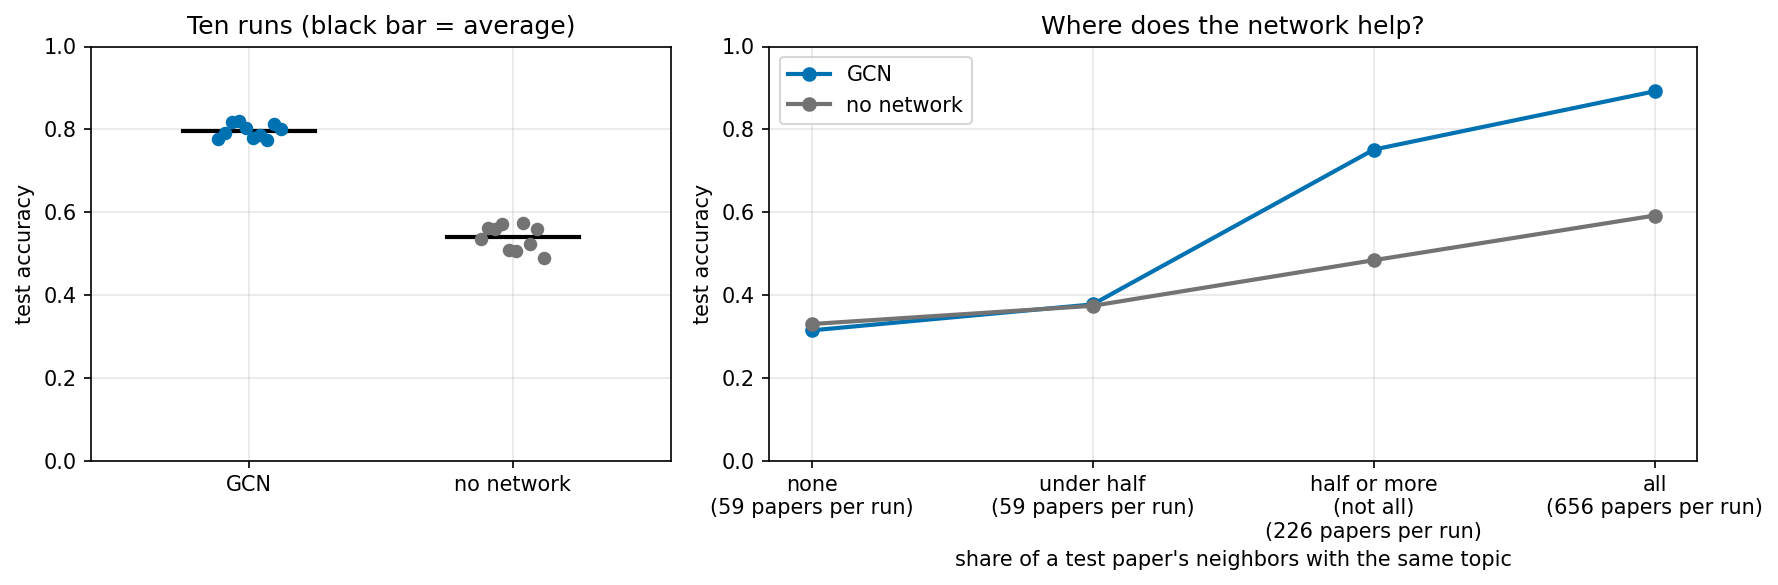

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=150, gridspec_kw={'width_ratios': [1, 1.6]})

for k, (name, color) in enumerate([('GCN', TWO[0]), ('no network', '0.45')]):
    axes[0].scatter(np.full(10, k) + np.linspace(-0.12, 0.12, 10), per_run[name], color=color, s=30, zorder=3)
    axes[0].plot([k - 0.25, k + 0.25], [per_run[name].mean()] * 2, color='k', lw=2)
    axes[1].plot(range(4), by_share[name], marker='o', color=color, lw=2, label=name)

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['GCN', 'no network'])
axes[0].set_xlim(-0.6, 1.6)
axes[0].set_ylabel('test accuracy')
axes[0].set_title('Ten runs (black bar = average)')

axes[1].set_xticks(range(4))
axes[1].set_xticklabels([label.replace(' (not', '\n(not') + f'\n({counts[label]:.0f} papers per run)' for label in by_share.index])
axes[1].set_xlabel("share of a test paper's neighbors with the same topic")
axes[1].set_ylabel('test accuracy')
axes[1].set_title('Where does the network help?')
axes[1].legend(loc='upper left')

for ax in axes:
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Over ten random splits, the GCN gets 0.796 of the test papers right on average (between 0.774 and 0.819), and the model with no network gets 0.539 (between 0.490 and 0.574). Every GCN run beat every no-network run. Our first run, from earlier in this part, gave the GCN 0.755, below all ten of these. That run had its own split and its own starting weights, so we can't tell which of the two made it come out low. Kipf & Welling report 80.1% over their own ten random splits, so our version without dropout or early stopping lands within a point of theirs. The GCN's accuracy also moves by several points from one split to the next, so a one-point difference between two methods on a single split doesn't tell us much.

The right panel shows where the gain comes from. When all of a test paper's neighbors share its topic, the GCN gets 0.89 of those papers right, compared with 0.59 for the model with no network. When half or more of them do, but not all, it's 0.75 compared with 0.48. But when fewer than half of a paper's neighbors share its topic, the GCN does no better than the model that ignores the network (0.377 versus 0.374 when some of them do, and 0.315 versus 0.330 when none of them do). For those papers, averaging mixes in words from the wrong topics. A paper's own words are still part of its average, which may be why the GCN ties with the model with no network there instead of doing worse.

The model with no network also does better on papers whose neighbors share their topic (0.59 when all of them do, compared with 0.33 when none do), even though it never sees the links. Those papers are probably more typical of their topic, so their words are easier to classify, too. The gap between the two lines is what the network adds.

Cora is friendly to GCNs, because 81% of its links join papers on the same topic. In networks where linked nodes tend to be *different* from each other, which people call **heterophily**, a plain GCN can do worse than a model that ignores the network entirely (Zhu et al., 2020).

### What did the GCN learn? Embeddings

When we talk about making **embeddings**, we're talking about representing our data points or objects in our dataset as meaningful vectors. In graphs, and in natural language, we *could* represent nodes and words as sparse vectors. These might look like the sparse rows in an adjacency matrix, or like our 1,433 zeros and ones per paper. These work as inputs (the model with no network used exactly these), but they're long and mostly zeros, and two papers on the same topic can share almost none of their words, which makes them bad for comparing papers to each other. Embeddings can result from dimensionality reduction techniques like principal component analysis (PCA), but nowadays, when we think about embeddings, we tend to think about vectors that are created via training a neural network model to do a task.

That's exactly what the hidden layer of our GCN is: 16 numbers per paper, learned while training the model to predict topics. On Wednesday we hand-built one number per node to describe where it sits in the network, and here the model learned 16 of them. To look at 16 numbers per paper, we squash them down to 2 with t-SNE (van der Maaten & Hinton, 2008), a method that tries to keep papers that are close together in 16 dimensions close together in 2. Then we color each paper by its true topic.

In [70]:
tsne_xy = {}
for name, m, A in [('no network', no_net, I), ('GCN', gcn, A_hat)]:
    with torch.no_grad():
        m(X, A)                                    # run the model once so m.hidden is filled in
    tsne_xy[name] = TSNE(n_components=2, init='pca', random_state=SEED).fit_transform(m.hidden.numpy())

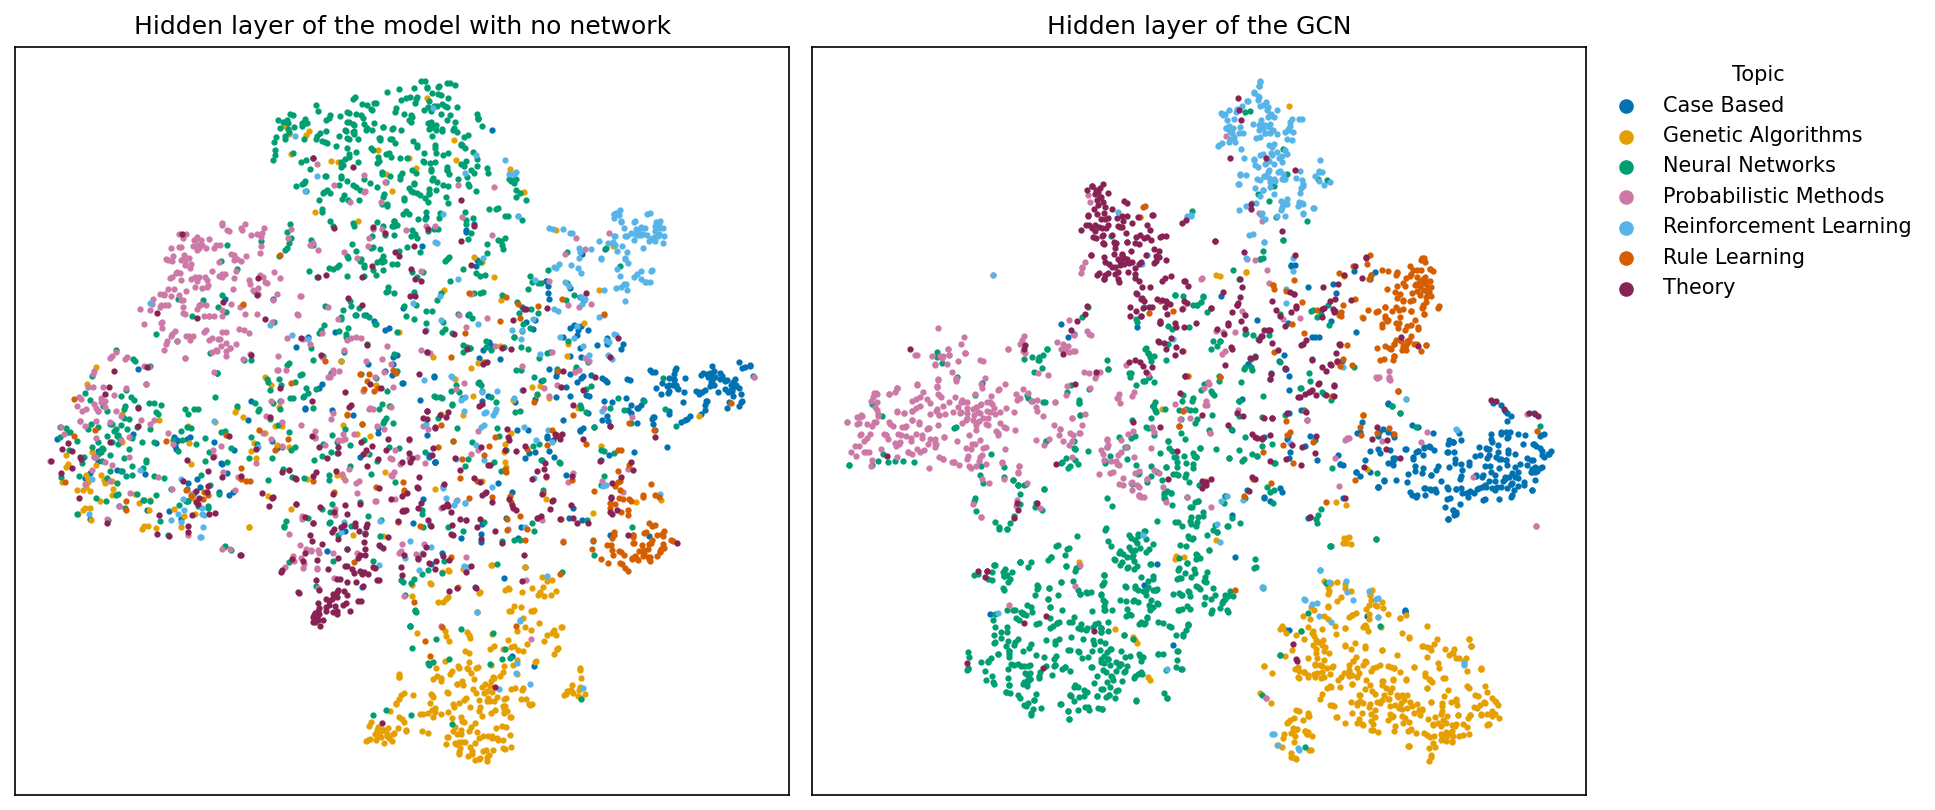

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)

for ax, name, title in [(axes[0], 'no network', 'Hidden layer of the model with no network'),
                        (axes[1], 'GCN', 'Hidden layer of the GCN')]:

    xy = tsne_xy[name]
    for t, topic in enumerate(topics):
        ax.scatter(*xy[y_cora == t].T, s=4, color=SEVEN[t], label=topic.replace('_', ' '))
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1), markerscale=3, frameon=False, title='Topic')

plt.tight_layout()
plt.show()

Both models were trained to predict topics, so in both pictures papers on the same topic tend to land near each other. Notice the difference, though. With no network, lots of papers end up in a mixed-up middle where every color shows up. With the GCN, most papers sit in a group with their own topic. Remember that the GCN only knew the topics of 140 of these 2,708 papers. The rest landed near their topic group partly because of their words, which the model with no network had too, and partly because each paper's vector is an average over its neighborhood, which pulls papers on the same topic toward each other.

One warning about t-SNE pictures: they're good at showing which points are close together, but the sizes of the groups and the distances between them don't mean much.

Kipf & Welling made the same kind of picture in their paper, from a two-layer GCN trained on Cora with 5% of the labels, which is about what we have:

![Figure 1b from Kipf & Welling (2017)](./images/kipf_welling_fig1b.png)

*Figure 1b from Kipf & Welling (2017). The colors are Cora's topics, but they aren't the same colors as ours.*

Their groups look a lot like the ones in our GCN panel: each group is mostly one color, with some mixing where the groups meet. Their picture has less of a mixed-up middle than ours. Their GCN was trained a little differently from ours (with dropout, and they stopped training early), and t-SNE pictures change from one run to the next, so we shouldn't read too much into that difference.

### In practice: PyTorch Geometric

We wrote our GCN layer by hand so we could see each step of the calculation. In practice, people use [`pytorch-geometric`](https://pytorch-geometric.readthedocs.io/en/latest/) (PyG), which has dozens of GNN layers ready to go (Fey & Lenssen, 2019). Its `GCNConv` layer takes the node features and the list of links, adds the self-loops and the $1/\sqrt{\tilde{k}_i \tilde{k}_j}$ weights itself, and does the same calculation as our `GCNLayer`. Sanity check: give it the same weights as the first layer of our trained GCN, and it should give the same output.

In [72]:
from torch_geometric.nn import GCNConv

edge_index = torch.cat([edges, edges.flip(0)], dim=1)   # PyG wants every link listed in both directions

conv = GCNConv(1433, 16)
ours = gcn.layers[0]
with torch.no_grad():
    conv.lin.weight.copy_(ours.W.weight)
    conv.bias.copy_(ours.b)
    print('Same output as our first layer:', torch.allclose(conv(X, edge_index), ours(X, A_hat), atol=1e-5))

Same output as our first layer: True


## Your Turn
In the neural network context, **hyperparameters** are settings we choose before training that training doesn't change, like on Wednesday. The weights are the plain parameters, the ones training does change. Some hyperparameters shape the model (number of layers, layer size, activation function) and some control how we find its weights (learning rate, choice of optimizer). Finding good hyperparameters can take a lot of time, depending on the number and types of hyperparameters you're playing with. Choose them by looking at the **validation** accuracy, and look at the test set only at the very end, like on Wednesday.

For this Your Turn section, I want you to do one or more of the following:

1) Our `GCN` class already takes a list of layer sizes, so `GCN([1433, 16, 16, 16, 7])` is a GCN with four layers. Train models with 1, 2, 3, 4, 6 and 8 layers. Tell me how the validation accuracy changes as the number of layers increases or decreases. Optionally, make the t-SNE picture for the deepest model and tell me if the embeddings get better or worse.

2) Swap the GCN layer for the Part 2 layer: one weight matrix for the node itself and one for the plain average of its neighbors (use $D^{-1}A$ instead of $\hat{A}$, and leave out the self-loops). Does it do better or worse on Cora than the GCN?

3) Look at the different choices of convolutional layers available in PyG [here](https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html#convolutional-layers). Choose a couple different types of convolutional layers and build models with those layers. Compare their validation accuracies, and tell me one possible reason for the difference.

### Spoiler for option 1: what happens with more layers?

Don't look below until you've tried it!

Here's option 1, with five random splits for each number of layers. This cell trains 30 models, so it takes a few minutes.

In [73]:
depths = [1, 2, 3, 4, 6, 8]
sweep = []
for L in depths:
    for seed in range(5):
        torch.manual_seed(seed)
        m = GCN([1433] + [16] * (L - 1) + [7])
        history = train(m, A_hat, make_split(seed))
        sweep.append({'layers': L, 'seed': seed, 'train': history.train.iloc[-1], 'validation': history.validation.iloc[-1]})

sweep = pd.DataFrame(sweep).groupby('layers').agg(train=('train', 'mean'), validation=('validation', 'mean'),
                                                  validation_std=('validation', 'std'))

print(sweep.round(3))

        train  validation  validation_std
layers                                   
1       1.000       0.738           0.015
2       1.000       0.782           0.020
3       1.000       0.756           0.016
4       1.000       0.721           0.025
6       1.000       0.561           0.080
8       0.496       0.303           0.138


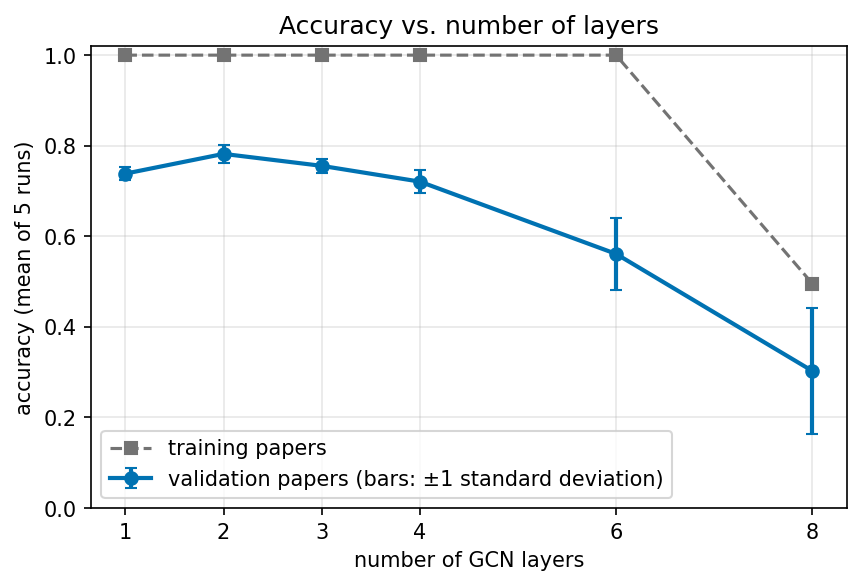

In [74]:
fig, ax = plt.subplots(1, 1, figsize=(6.5, 4), dpi=150)
ax.plot(sweep.index, sweep['train'], 's--', color='0.45', lw=1.5, label='training papers')
ax.errorbar(sweep.index, sweep['validation'], yerr=sweep['validation_std'], fmt='o-', color=TWO[0], capsize=3, lw=2,
            label='validation papers (bars: ±1 standard deviation)')

ax.set_xticks(depths)
ax.set_xlabel('number of GCN layers')
ax.set_ylabel('accuracy (mean of 5 runs)')
ax.set_ylim(0, 1.02)
ax.legend(loc='lower left')
ax.set_title('Accuracy vs. number of layers')
ax.grid(alpha=0.3)

plt.show()

Two layers does best. One layer lets each paper hear only from its direct neighbors. Past two layers, each deeper model we tried does worse, and with 8 layers the GCN gets fewer than half of the validation papers right, with big differences from run to run. If you run this cell on a different computer, your numbers for 6 and 8 layers may not match ours. Deep models are touchy, and tiny rounding differences in the arithmetic, which depend on the computer and how many processors it uses, get amplified over 200 epochs of training. The numbers for 1 to 4 layers barely move.

Why? Look at the gray line, which shows accuracy on the training papers. Up to 4 layers (and at 6 too, on our computer), every model gets all 140 training papers right, and still does worse on the validation papers as we add layers. So the deeper models fit the labels we gave them, but in a way that carries over less and less to the papers whose labels they never saw. That's overfitting, from Wednesday. By 8 layers the GCN can't even fit the 140 training papers anymore, so training itself has gotten hard. The big spread at 6 and 8 layers is another sign of trouble, because the same model, with different starting weights and a different split, ends up in very different places.

Here's Kipf & Welling's version of this experiment, from the appendix of their paper. The middle panel is Cora.

![Figure 5 from Kipf & Welling (2017)](./images/kipf_welling_fig5.png)

*Figure 5 from Kipf & Welling (2017).*

Their setup is different from ours. They used all of Cora's labels instead of 140, split the papers into 5 groups and took turns holding one group out for testing (5-fold cross-validation), and trained for 400 epochs, with dropout. The dashed lines are a GCN like ours, and the solid lines are the same model with residual connections (where each layer adds its input back onto its output). Two or three layers does best, like in ours. With that many labels, their plain GCN's test accuracy stays flat out to about 7 layers, and then the test and the training accuracy both fall. That's the same kind of trouble our 8-layer models had, and Kipf & Welling found that past 7 layers, training could become difficult without residual connections. With residual connections, both stay up all the way to 10 layers.

The usual explanation for what goes wrong in deep GCNs is **over-smoothing**: averaging over and over makes every paper look like every other paper. Let's check it. We strip away the weights and the ReLUs and just apply $\hat{A}$ to the word features over and over, which is the averaging part of a GCN with no little neural network in between. After each round of averaging we measure how similar papers are to each other, separately for pairs of papers on the same topic and pairs on different topics. We use the **cosine similarity** of their vectors,

$$\cos(u, v) = \frac{u \cdot v}{\|u\| \, \|v\|},$$

where $u \cdot v$ is the dot product and $\|u\|$ is the length of $u$. It's 1 when two vectors point in exactly the same direction, and 0 when they have nothing in common. For example, a paper that uses words 1 and 2 and a paper that uses only word 1 have $u = [1, 1, 0]$ and $v = [1, 0, 0]$, so $\cos(u, v) = 1 / (\sqrt{2} \times 1) = 0.71$.

In [75]:
# Pairs of papers in the largest component (averaging can't mix papers in different components)
rng = np.random.default_rng(SEED)
pairs = rng.choice(sorted(giant), size=(20000, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
same_pair = y_cora[pairs[:, 0]] == y_cora[pairs[:, 1]]

rounds = [0, 1, 2, 4, 8, 16, 32, 64, 128, 256]
similarity, H = [], X.clone()
for r in range(rounds[-1] + 1):
    if r in rounds:
        Hn = F.normalize(H, dim=1)
        cos = (Hn[pairs[:, 0]] * Hn[pairs[:, 1]]).sum(dim=1).numpy()
        similarity.append({'rounds': r, 'same topic': cos[same_pair].mean(), 'different topics': cos[~same_pair].mean()})

    H = torch.sparse.mm(A_hat, H)

similarity = pd.DataFrame(similarity)
similarity['gap'] = similarity['same topic'] - similarity['different topics']

print(similarity.round(3).to_string(index=False))

 rounds  same topic  different topics    gap
      0       0.079             0.054  0.025
      1       0.205             0.150  0.055
      2       0.326             0.246  0.080
      4       0.463             0.364  0.099
      8       0.616             0.512  0.105
     16       0.762             0.673  0.088
     32       0.869             0.816  0.053
     64       0.933             0.915  0.018
    128       0.968             0.966  0.002
    256       0.989             0.991 -0.001


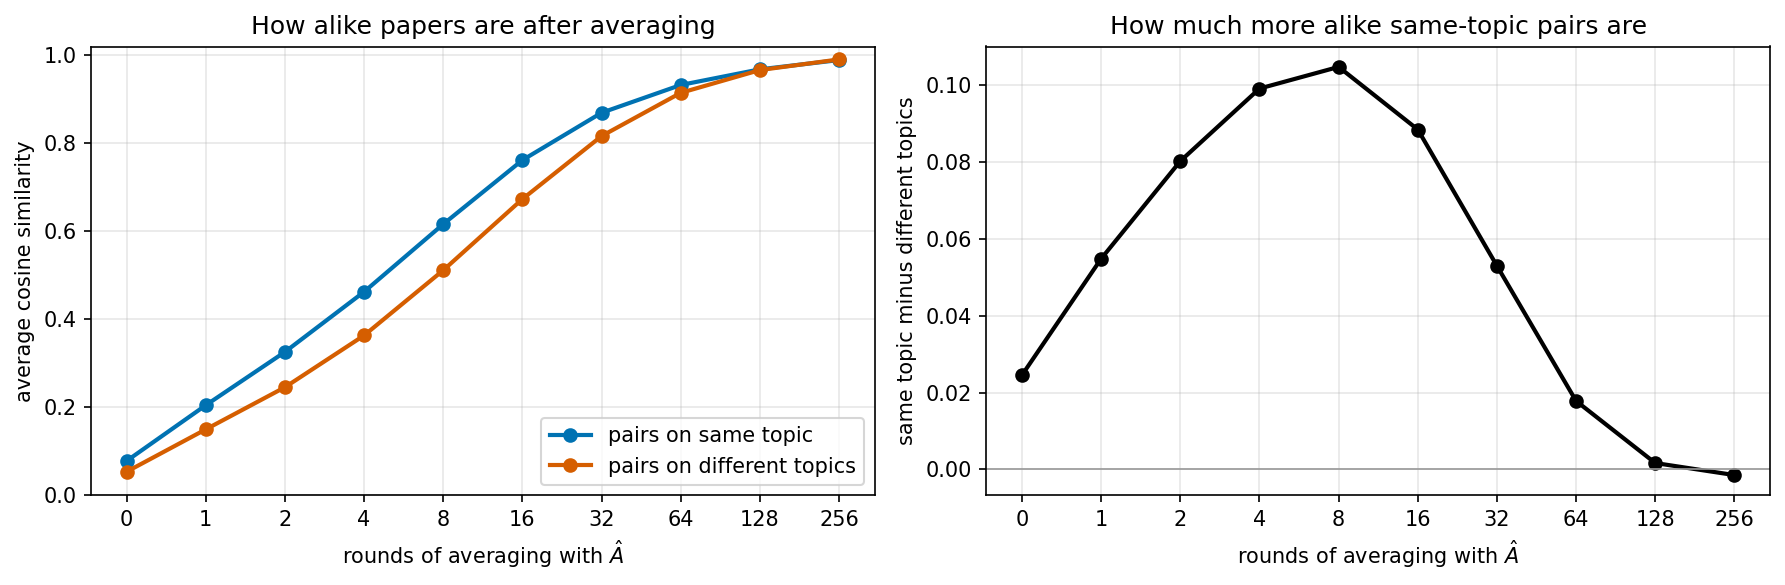

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=150)

for name, color in [('same topic', TWO[0]), ('different topics', TWO[1])]:
    axes[0].plot(range(len(rounds)), similarity[name], 'o-', color=color, lw=2, label=f'pairs on {name}')

axes[0].set_ylabel('average cosine similarity')
axes[0].set_ylim(0, 1.02)
axes[0].legend(loc='lower right')
axes[0].set_title('How alike papers are after averaging')

axes[1].plot(range(len(rounds)), similarity['gap'], 'o-', color='k', lw=2)
axes[1].axhline(0, color='0.6', lw=0.8)
axes[1].set_ylabel('same topic minus different topics')
axes[1].set_title('How much more alike same-topic pairs are')

for ax in axes:
    ax.set_xticks(range(len(rounds)))
    ax.set_xticklabels(rounds)
    ax.set_xlabel('rounds of averaging with $\\hat{A}$')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Every round of averaging makes papers more similar to each other, whether or not they share a topic (left panel). Notice that after the first step, the number of rounds doubles at every step along the x-axis. For the first few rounds, papers on the same topic become alike faster than papers on different topics, so the difference between them grows (right panel). That fits with what we saw at the start of this part, where a little averaging helped logistic regression a lot. The difference is still growing from 4 rounds to 8, and it's at its largest at 8 rounds, out of the ones we tried. So at the depths in our sweep, averaging by itself hasn't washed out the topics yet, and it can't be the whole reason accuracy drops from 3 to 6 layers. What the sweep did show is that the models up to 4 layers fit every training paper but do worse on the validation papers as they get deeper, and that by 8 layers training itself gets hard.

After 8 rounds the difference shrinks, and by 256 rounds it's gone. On average, two papers on the same topic now have about the same cosine similarity as two papers on different topics, around 0.99. This is the power iteration from Class 4, where we found eigenvector centrality by multiplying by the same matrix over and over. Each round of averaging pushes the numbers toward the top eigenvector of $\hat{A}$, and if we kept going forever, every paper's vector in the big component would end up pointing the same way (only their lengths would differ). Li, Han & Wu (2018) call this over-smoothing.

But an average of 0.99 doesn't mean every pair of papers is that alike, and the small differences that are left might still say something about topics. We take the vectors after 256 rounds and, for each validation paper in the big component, guess the topic of the training paper whose vector is most similar to it (the highest cosine similarity).

In [77]:
H_256 = X.clone()
for r in range(256):
    H_256 = torch.sparse.mm(A_hat, H_256)          # 256 rounds of averaging, no weights, no ReLU

Hn = F.normalize(H_256, dim=1)                     # every vector scaled to length 1, so dot products are cosines
train_big = [u for u in train_idx if u in giant]   # training and validation papers in the largest component
val_big = [u for u in val_idx if u in giant]

closest = (Hn[val_big] @ Hn[train_big].T).argmax(dim=1).numpy()   # each validation paper's most similar training paper
right = y_cora[np.array(train_big)[closest]] == y_cora[val_big]

print(f'guessing from the most similar training paper: {right.sum()} of {len(val_big)} right ({right.mean():.0%})')
print(f'always guessing the most common topic:          {np.bincount(y_cora[val_big]).max() / len(val_big):.0%}')

guessing from the most similar training paper: 323 of 469 right (69%)
always guessing the most common topic:          30%


That's still about 69% right, far above the 30% we'd get by always guessing the most common topic. So after 256 rounds, the vectors point in nearly the same direction on average, but the small differences that are left still carry a lot of information about topics. Plain averaging hasn't erased the topics at any depth we tried. To find out whether over-smoothing is part of what goes wrong in our deep GCNs, we'd have to look at the vectors inside the trained models, which have weights and ReLUs between the rounds of averaging.

In [78]:
reach = {L: np.mean([len(nx.single_source_shortest_path_length(G_cora, u, cutoff=L)) for u in range(n)]) for L in depths}

print('average number of papers within L hops:', {L: round(v) for L, v in reach.items()})

average number of papers within L hops: {1: 5, 2: 37, 3: 128, 4: 373, 6: 1325, 8: 1993}


By 8 layers, a typical paper's new vector can depend on most of the network, because receptive fields grow fast in real networks. Counting the paper itself, there are 37 papers within 2 hops of a Cora paper on average, 373 within 4 hops, and 1,993 within 8 hops, out of 2,708. (Cora has 78 connected components, as we counted at the start of this part, and a paper in one of the small ones can only ever hear from its own component, however many layers we add.) Remember the diamonds on the grid: in a network with hubs, the diamond grows much faster. So for most papers, an 8-layer GCN isn't looking at a small neighborhood anymore, even though, as we just saw, the averaging hasn't erased the topics yet.

__________
## Part 4: From node vectors to a whole graph

Our GNN layers give us one vector per node. Often we need something more than just node embeddings: we might need information about the whole graph, like whether a molecule is toxic, or whether a group of accounts is a bot network. In that case, we apply a permutation-invariant function (like the mean, again) to the entire set of node vectors produced by our last GNN layer, which gives one vector for the whole graph. This step is called the **readout**, and that graph vector can go into a regular neural network like the one in Part 1.

Sanity check, back on the tiny graph from Part 2: if we number the nodes differently, the node vectors come out in a different order, but the readout shouldn't change.

In [79]:
perm = np.random.default_rng(SEED).permutation(6)    # a random new numbering of the 6 nodes
P = np.eye(6)[perm]                                  # the matching permutation matrix

# The same graph, with the nodes listed in a different order: P @ X_tiny reorders the rows of X_tiny,
# and P @ A_tiny @ P.T reorders both the rows and the columns of A_tiny, so the links still match the nodes
A_perm, X_perm = P @ A_tiny @ P.T, P @ X_tiny

H_perm = np.maximum(0, X_perm @ W_self + np.diag(1 / A_perm.sum(axis=1)) @ A_perm @ X_perm @ W_neigh)

print('node vectors, original numbering:\n', H_matrix)
print('node vectors, new numbering:\n', H_perm)
print('readout, original numbering:', H_matrix.mean(axis=0).round(3))
print('readout, new numbering:     ', H_perm.mean(axis=0).round(3))

node vectors, original numbering:
 [[2.25       0.         0.        ]
 [1.5        0.         1.        ]
 [1.         0.         3.        ]
 [3.16666667 1.16666667 0.        ]
 [1.75       0.         0.5       ]
 [1.         0.         2.        ]]
node vectors, new numbering:
 [[3.16666667 1.16666667 0.        ]
 [1.         0.         3.        ]
 [1.         0.         2.        ]
 [1.75       0.         0.5       ]
 [1.5        0.         1.        ]
 [2.25       0.         0.        ]]
readout, original numbering: [1.778 0.194 1.083]
readout, new numbering:      [1.778 0.194 1.083]


Xu et al. (2019) describe most GNNs in terms of three steps:
- **AGGREGATE** (steps 1 and 2 of our list in Part 2): gather up the vectors of a node's neighbors and pass them through a permutation-invariant function like MEAN, which gives a vector of fixed length.
- **COMBINE** (step 3): mix that with the node's own vector to get its new vector. Some GNNs, like the GCN, include a node in its own neighborhood during aggregation, which takes care of this step.
- **READOUT**: when we need one answer for the whole graph, apply a permutation-invariant function to all of the node vectors from the last layer.

People also call AGGREGATE and COMBINE together **message passing** (Gilmer et al., 2017): every node sends its vector to its neighbors as a "message", and every node updates itself based on the messages it receives.

**INTERACTIVE MOMENT:** What would you use a GNN to do?

----------------------
Examples: protein-protein interaction prediction, fraud detection, or social network recommendations.

_______________
## Appendix A: Backpropagation
At a very high level, backpropagation is how we work out which way to adjust each of our weights (the slopes from Part 1), going back from the output layer (and our loss function) all the way back to the weights from the input layer (Rumelhart et al., 1986).

It involves computing a bunch of partial derivatives (gradients) of the loss with respect to our weights and biases (the parameters we're learning in our neural network). Then an optimizer, like gradient descent or Adam, uses those gradients to adjust the weights and biases.

### What ingredients do we need to do backpropagation?

First, we need a loss function. Our loss function (or cost function) needs to be differentiable with respect to the weights and biases we use in the network. Our loss also has to be expressed as a function of the input and our weights and biases. For example, let's look at a toy example with one hidden layer and a squared error loss function.

Leaving out the biases to keep things short, and treating the input $\vec{x}$ as a row vector like in Part 2, the output $g(\vec{x})$ of our neural network, given weight matrices $W^{(1)}$ and $W^{(2)}$ and activation functions $\sigma^{(1)}$ and $\sigma^{(2)}$, is

$$g(\vec{x}) = \sigma^{(2)}\big(\sigma^{(1)}(\vec{x}\, W^{(1)})\, W^{(2)}\big)$$

Write $\vec{h} = \sigma^{(1)}(\vec{x}\, W^{(1)})$ for the hidden layer's output, and $\hat{\vec{y}} = g(\vec{x})$ for the network's output. With ground truth $\vec{y}$, our loss is $C = \sum_j (\hat{y}_j - y_j)^2$.

Next, we need partial derivatives and the chain rule! Say $w^{(2)}_{ij}$ is the weight from hidden unit $i$ to output unit $j$. It only affects the loss through the weighted sum going into output $j$, which we'll call $o_j = \sum_{k} w^{(2)}_{kj} h_k$, and then through $\hat{y}_j = \sigma^{(2)}(o_j)$. The chain rule follows that path:

$$\frac{\partial C}{\partial w^{(2)}_{ij}} = \frac{\partial C}{\partial \hat{y}_j} \, \frac{\partial \hat{y}_j}{\partial o_j} \, \frac{\partial o_j}{\partial w^{(2)}_{ij}}$$

What are we doing here? We're tracing how our specific weight $w^{(2)}_{ij}$ affects our computed loss for a particular input (or batch of inputs). Each of the three derivatives is easy to work out:

- Only one term in the sum $o_j$ relies on $w^{(2)}_{ij}$, and that's $w^{(2)}_{ij} h_i$. So $\frac{\partial o_j}{\partial w^{(2)}_{ij}} = h_i$.
- $\frac{\partial \hat{y}_j}{\partial o_j}$ is the derivative of the activation function $\sigma^{(2)}$. For a sigmoid, it's $\sigma(o_j)(1 - \sigma(o_j)) = \hat{y}_j (1 - \hat{y}_j)$.
- For the squared error loss, $\frac{\partial C}{\partial \hat{y}_j} = 2 (\hat{y}_j - y_j)$.

Therefore, for a sigmoid output and a squared error loss, the gradient of our loss with respect to $w^{(2)}_{ij}$ is

$$\frac{\partial C}{\partial w^{(2)}_{ij}} = 2 (\hat{y}_j - y_j) \, \hat{y}_j (1 - \hat{y}_j) \, h_i.$$

The weights in the first layer work the same way with a longer chain, because each of them affects every output through the hidden layer. Backpropagation computes all of these products starting at the output and working backwards, reusing the products it has already computed, which is where the name comes from.

Sanity check: nudge one weight by a tiny amount, see how much the loss changes, and compare that to the formula.

In [80]:
rng = np.random.default_rng(SEED)
x_in = rng.normal(size=3)               # one input with 3 features
y_true = np.array([1.0, 0.0])           # the right answer, 2 outputs
W1_bp = rng.normal(size=(3, 4))         # 3 inputs -> 4 hidden units (ReLU)
W2_bp = rng.normal(size=(4, 2))         # 4 hidden units -> 2 outputs (sigmoid); W2_bp[i, j] is w_ij


def forward(W1, W2):
    h = np.maximum(0, x_in @ W1)
    return h, sigmoid(h @ W2)


def loss(W1, W2):
    return np.sum((forward(W1, W2)[1] - y_true) ** 2)

In [81]:
h, y_hat = forward(W1_bp, W2_bp)
i, j = int(np.argmax(h)), 0             # a hidden unit that's switched on, and the first output
chain_rule = 2 * (y_hat[j] - y_true[j]) * y_hat[j] * (1 - y_hat[j]) * h[i]

eps = 1e-6
W2_nudged = W2_bp.copy()
W2_nudged[i, j] += eps
nudge = (loss(W1_bp, W2_nudged) - loss(W1_bp, W2_bp)) / eps

print(f'chain rule formula: {chain_rule:.6f}')
print(f'nudging the weight: {nudge:.6f}')

chain rule formula: -0.375968
nudging the weight: -0.375969


### Moving right along/TL;DR (For those who hate math!!)
We take partial derivatives with the chain rule to figure out how much our loss function changes with respect to a particular parameter (like a weight or bias) in the neural network.

Then we can change that specific weight with this information. Like in Part 1, we usually have a learning rate $\eta$ (or an optimizer that governs the learning rate, which is fancier) that tells us how far to move a weight or bias given our computed gradient:

$$ w^{(2)}_{ij} \leftarrow w^{(2)}_{ij} - \eta \frac{\partial C}{\partial w^{(2)}_{ij}}. $$

The minus sign is there because we want to go downhill: if making a weight bigger makes the loss bigger, we make the weight smaller. We don't want to update our parameters too much based on any one example, which is why the learning rate is usually kept small (for Adam, values like 0.01 or 0.001 are common), and many training setups lower the learning rate as training goes on and the model gets better at its task.
________
Let's review how backpropagation works by watching [this video](https://www.youtube.com/watch?v=GlcnxUlrtek&list=PLiaHhY2iBX9hdHaRr6b7XevZtgZRa1PoU&index=4).

_______________
## Appendix B: node2vec, embeddings without a neural network on every node

GNNs are one way to learn node embeddings. An older and still very popular way doesn't use node features at all, only the links, and it's adapted from word2vec, a method from natural language processing for learning embeddings of words.

#### Word2Vec
[Word2Vec](https://arxiv.org/pdf/1301.3781) (Mikolov, Chen, et al., 2013) was an early and very influential way to learn word embeddings, and it was very exciting at the time. It trained a fairly simple neural network to do one of two tasks: Continuous Bag-of-Words (CBOW) or Skip-Gram. CBOW involves predicting which word is missing from a given context of surrounding words, and Skip-Gram involves doing the opposite: predicting the surrounding context given a specific word. The loss function here is cross-entropy loss. In principle, a softmax turns the outputs of the final layer into a probability for every word in the vocabulary, and the cross-entropy loss quantifies how incorrect we were. With a big vocabulary that softmax is slow to compute, so the original paper uses a faster version called hierarchical softmax, which gets the probability of a word from a short series of yes-or-no decisions down a tree instead of from the whole vocabulary at once. A follow-up paper (Mikolov, Sutskever, et al., 2013) introduced negative sampling, which we describe below. There are good pictures of [the two word2vec tasks](https://devopedia.org/word2vec) and of [softmax with cross-entropy loss](https://gombru.github.io/2018/05/23/cross_entropy_loss/) online.

#### Node2Vec
[Node2Vec](https://arxiv.org/pdf/1607.00653) follows similar logic to Word2Vec. We do random walks through a network and treat these random walks like sentences. Then node2vec trains a Skip-Gram model on these walks to get node embeddings. Node2Vec samples $r$ random walks starting at each of the $n$ nodes, so $n \cdot r$ walks in all. It has hyperparameters that influence how likely the walk is to step straight back to the node it just came from ($p$) and how much we favor visiting nodes close to the one we just came from versus nodes that are further away ($q$). 

When people around the time of Node2Vec were thinking about building node embeddings, they tended to consider homophily (nodes that are linked are likely to be similar) or structural equivalence (nodes that play similar roles in the network, like the hubs of two different communities, are likely to be similar). In older network analysis the term is stricter, and means that two nodes have exactly the same neighbors. Random walks that are closer to depth-first search (DFS) tend to get further away from their start node, so they'll have a better sense of the community structure of a given graph and we'll get more information about node homophily (in theory). However, longer-range dependencies can be harder to make sense of and more complicated. If we instead do something more like a breadth-first search (BFS), we're thinking more about structural equivalence, which asks whose neighborhoods look similar. This isn't likely to explore more distant parts of the graph, and nodes will repeat themselves a lot in a given walk. So Grover & Leskovec structured their random walks with hyperparameters $p$ and $q$ that allow us to figure out where on the BFS–DFS spectrum we want to end up.

Say the walk just moved from node $t$ to node $v$, and is deciding where to go next. Our non-normalized probability of stepping to a neighbor $x$ of $v$ is $\alpha(t, x) \, w(v, x)$, where $w(v, x)$ is the weight of the link (1 if the network is unweighted) and

$$
\alpha(t, x) =
\begin{cases}
\frac{1}{p} & \text{if } d(t, x) = 0 \\
1 & \text{if } d(t, x) = 1 \\
\frac{1}{q} & \text{if } d(t, x) = 2
\end{cases}
$$

where $d(i, j)$ is the number of hops between node $i$ and node $j$. So $d(t, x) = 0$ means stepping straight back to $t$, a small $p$ makes that more likely, and a small $q$ makes the walk wander away from where it just was.

Here's what a few random walks look like on our tiny graph from Part 2, written out like sentences. These are plain random walks, which is node2vec with $p = q = 1$, and also what node2vec's predecessor DeepWalk used (Perozzi et al., 2014).

In [82]:
rng = np.random.default_rng(SEED)

for start in [0, 0, 5, 5]:
    walk = [start]
    for step in range(7):
        walk.append(int(rng.choice(sorted(G_tiny.neighbors(walk[-1])))))
    print(' '.join(str(u) for u in walk))

0 1 2 1 0 1 2 0
0 2 0 1 2 3 5 4
5 4 5 4 3 5 3 4
5 3 2 3 5 4 3 5


Here's an image from the original Node2Vec paper of the different outcomes of Node2Vec on a network generated from the novel *Les Misérables* with hyperparameter settings that lean more towards prioritizing homophily (closer to DFS) and structural equivalence (closer to BFS).

![lesmis](./images/les_mis_node2vec.png)

Node2Vec also uses **negative sampling**. Computing the softmax over every node in the network for every training example is slow. Instead, the model learns a yes-or-no score for pairs of nodes. For each real pair (a node, and a node near it in a walk), we also draw a few nodes at random, which are probably **not** in its neighborhood, and train the score to say yes for the real pair and no for the random ones. It's possible to tune how many negative samples we draw for each positive sample. This is much cheaper than the full softmax, because each step only changes the weights of a handful of nodes. 

To train node2vec yourself, PyTorch Geometric has a `Node2Vec` model (`torch_geometric.nn.Node2Vec`), and gensim's `Word2Vec` can be trained on walks like the ones above (with `sg=1`, which picks Skip-Gram). Both are installed in `cmns-ml`.

__________
## Next time...
Network Comparison & Graph Distances `class_20_graph_distances.ipynb` (Mon, Nov 30)
_______

## References and further resources:

1. Class Webpages
    - Jupyter Book: https://computational-methods-network-science.github.io/nets7052_fa26/README.html
    - Github: https://github.com/computational-methods-network-science/nets7052_fa26/
    - Syllabus and course details: https://brennanklein.com/nets7052-fall26
2. Bagrow, J. P., & Ahn, Y.-Y. (2024). *Working with Network Data: A Data Science Perspective*. Cambridge University Press.
3. Fey, M., & Lenssen, J. E. (2019). Fast graph representation learning with PyTorch Geometric. *ICLR Workshop on Representation Learning on Graphs and Manifolds*. arXiv:1903.02428. https://arxiv.org/abs/1903.02428
4. Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O., & Dahl, G. E. (2017). Neural message passing for quantum chemistry. In *Proceedings of the 34th International Conference on Machine Learning (ICML 2017)* (pp. 1263–1272). arXiv:1704.01212. https://arxiv.org/abs/1704.01212
5. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. https://www.deeplearningbook.org/
6. Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’16)* (pp. 855–864). https://doi.org/10.1145/2939672.2939754
7. Hamilton, W. L., Ying, R., & Leskovec, J. (2017). Inductive representation learning on large graphs. In *Advances in Neural Information Processing Systems (NeurIPS 2017)* (pp. 1025–1035). arXiv:1706.02216. https://arxiv.org/abs/1706.02216
8. Hopfield, J. J. (1982). Neural networks and physical systems with emergent collective computational abilities. *Proceedings of the National Academy of Sciences*, 79(8), 2554–2558. https://doi.org/10.1073/pnas.79.8.2554
9. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *International Conference on Learning Representations (ICLR 2015)*. arXiv:1412.6980. https://arxiv.org/abs/1412.6980
10. Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. In *International Conference on Learning Representations (ICLR 2017)*. arXiv:1609.02907. https://arxiv.org/abs/1609.02907
11. Li, Q., Han, Z., & Wu, X.-M. (2018). Deeper insights into graph convolutional networks for semi-supervised learning. In *Proceedings of the AAAI Conference on Artificial Intelligence*, 32(1). arXiv:1801.07606. https://arxiv.org/abs/1801.07606
12. McCallum, A. K., Nigam, K., Rennie, J., & Seymore, K. (2000). Automating the construction of internet portals with machine learning. *Information Retrieval*, 3(2), 127–163. https://doi.org/10.1023/A:1009953814988
13. McCulloch, W. S., & Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. *The Bulletin of Mathematical Biophysics*, 5(4), 115–133. https://doi.org/10.1007/BF02478259
14. Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. *arXiv preprint* arXiv:1301.3781. https://arxiv.org/abs/1301.3781
15. Mikolov, T., Sutskever, I., Chen, K., Corrado, G. S., & Dean, J. (2013). Distributed representations of words and phrases and their compositionality. In *Advances in Neural Information Processing Systems 26 (NIPS 2013)* (pp. 3111–3119). arXiv:1310.4546. https://arxiv.org/abs/1310.4546
16. Minsky, M., & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.
17. Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). DeepWalk: Online learning of social representations. In *Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’14)* (pp. 701–710). https://doi.org/10.1145/2623330.2623732
18. Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408. https://doi.org/10.1037/h0042519
19. Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature*, 323(6088), 533–536. https://doi.org/10.1038/323533a0
20. Sen, P., Namata, G., Bilgic, M., Getoor, L., Gallagher, B., & Eliassi-Rad, T. (2008). Collective classification in network data. *AI Magazine*, 29(3), 93–106. https://doi.org/10.1609/aimag.v29i3.2157
21. van der Maaten, L., & Hinton, G. (2008). Visualizing data using t-SNE. *Journal of Machine Learning Research*, 9(86), 2579–2605. https://www.jmlr.org/papers/v9/vandermaaten08a.html
22. Veličković, P., Cucurull, G., Casanova, A., Romero, A., Liò, P., & Bengio, Y. (2018). Graph attention networks. In *International Conference on Learning Representations (ICLR 2018)*. arXiv:1710.10903. https://arxiv.org/abs/1710.10903
23. Wu, F., Zhang, T., Souza Jr., A. H. de, Fifty, C., Yu, T., & Weinberger, K. Q. (2019). Simplifying graph convolutional networks. In *Proceedings of the 36th International Conference on Machine Learning (ICML 2019)*. arXiv:1902.07153. https://arxiv.org/abs/1902.07153
24. Xu, K., Hu, W., Leskovec, J., & Jegelka, S. (2019). How powerful are graph neural networks? In *International Conference on Learning Representations (ICLR 2019)*. arXiv:1810.00826. https://arxiv.org/abs/1810.00826
25. Yang, Z., Cohen, W. W., & Salakhutdinov, R. (2016). Revisiting semi-supervised learning with graph embeddings. In *Proceedings of the 33rd International Conference on Machine Learning (ICML 2016)* (pp. 40–48). arXiv:1603.08861. https://arxiv.org/abs/1603.08861
26. Zhu, J., Yan, Y., Zhao, L., Heimann, M., Akoglu, L., & Koutra, D. (2020). Beyond homophily in graph neural networks: Current limitations and effective designs. In *Advances in Neural Information Processing Systems (NeurIPS 2020)*, 33, 7793–7804. arXiv:2006.11468. https://arxiv.org/abs/2006.11468
27. Labonne, M. (2022). Graph convolutional networks: Introduction to GNNs. *Towards Data Science*. https://towardsdatascience.com/graph-convolutional-networks-introduction-to-gnns-24b3f60d6c95
28. Kipf, T. (2016). Graph convolutional networks. Blog post. https://tkipf.github.io/graph-convolutional-networks/